In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

plt.style.use('ggplot')
sns.set_palette("muted")

input_pairs = [
    {
        "model_name": "TF_Ablation_IaCGOD",
        "result_file": "../results/TF_Ablation_IaCGOD/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_IaCGOD.csv"
    },
    {
        "model_name": "TF_Ablation_NoDenseRAG",
        "result_file": "../results/TF_Ablation_NoDenseRAG/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_NoDenseRAG.csv"
    },
    {
        "model_name": "TF_Ablation_NoGraphRAG",
        "result_file": "../results/TF_Ablation_NoGraphRAG/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_NoGraphRAG.csv"
    },
    {
        "model_name": "TF_Ablation_NoPlanner",
        "result_file": "../results/TF_Ablation_NoPlanner/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_NoPlanner.csv"
    },
    {
        "model_name": "TF_Ablation_OpenCodeRetriever",
        "result_file": "../results/TF_Ablation_OpenCodeRetriever/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_OpenCodeRetriever.csv"
    },
    {
        "model_name": "TF_Ablation_TrivyAllSeverities",
        "result_file": "../results/TF_Ablation_TrivyAllSeverities/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_TrivyAllSeverities.csv"
    },
    {
        "model_name": "TF_IaCEval_DSV4F_LintOnly",
        "result_file": "../results/TF_IaCEval_DSV4F_LintOnly/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_IaCEval_DSV4F_LintOnly.csv"
    },
    {
        "model_name": "TF_RealAWS_DSV4F",
        "result_file": "../results/TF_RealAWS_DSV4F/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_DSV4F.csv"
    },
    {
        "model_name": "TF_RealAWS_GLM53F",
        "result_file": "../results/TF_RealAWS_GLM53F/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_GLM53F.csv"
    },
    {
        "model_name": "TF_RealAWS_Gemini38F",
        "result_file": "../results/TF_RealAWS_Gemini38F/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_Gemini38F.csv"
    },
    {
        "model_name": "TF_RealAWS_OpenCode_DSV4F",
        "result_file": "../results/TF_RealAWS_OpenCode_DSV4F/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_OpenCode_DSV4F.csv"
    },
    {
        "model_name": "TF_RealAWS_Opus55",
        "result_file": "../results/TF_RealAWS_Opus55/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_Opus55.csv"
    },
        {
        "model_name": "TF_RealAWS_OneShot_GLM53F",
        "result_file": "../results/TF_RealAWS_OneShot_GLM53F/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_OneShot_GLM53F.csv"
    },
        {
        "model_name": "TF_RealAWS_ZeroShot_Opus55",
        "result_file": "../results/TF_RealAWS_ZeroShot_Opus55/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_ZeroShot_Opus55.csv"
    },
    {
        "model_name": "TF_Ablation_NoQueryRewrite",
        "result_file": "../results/TF_Ablation_NoQueryRewrite/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_NoQueryRewrite.csv"
    },
    {
        "model_name": "TF_Ablation_NoRemediator",
        "result_file": "../results/TF_Ablation_NoRemediator/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_Ablation_NoRemediator.csv"
    },
    {
        "model_name": "TF_RealAWS_OneShot_DSV4F",
        "result_file": "../results/TF_RealAWS_OneShot_DSV4F/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_OneShot_DSV4F.csv"
    },
    {
        "model_name": "TF_RealAWS_OneShot_Gemini38F",
        "result_file": "../results/TF_RealAWS_OneShot_Gemini38F/results_final.csv",
        "coverage_file": "result/final/Coverage_TF_RealAWS_OneShot_Gemini38F.csv"
    },
]

In [3]:
merged_dataframes = {}

for pair in input_pairs:
    model = pair["model_name"]
    res_df = pd.read_csv(pair["result_file"])
    cov_df = pd.read_csv(pair["coverage_file"])

    merge_key = "ground_truth_path" if "ground_truth_path" in cov_df.columns else "row_number"
    
    cols_to_use = cov_df.columns.difference(res_df.columns).tolist() + [merge_key]
    merged_df = pd.merge(res_df, cov_df[cols_to_use], on=merge_key, how="left")

    for _dc in ["difficulty_level", "difficulty"]:
        if _dc in merged_df.columns:
            merged_df[_dc] = pd.to_numeric(merged_df[_dc], errors="coerce").astype("Int64")

    merged_dataframes[model] = merged_df

    print(f"✅ Successfully merged {len(merged_df)} rows for {model} (Key: {merge_key}).")

✅ Successfully merged 50 rows for TF_Ablation_IaCGOD (Key: ground_truth_path).
✅ Successfully merged 49 rows for TF_Ablation_NoDenseRAG (Key: ground_truth_path).
✅ Successfully merged 50 rows for TF_Ablation_NoGraphRAG (Key: ground_truth_path).
✅ Successfully merged 50 rows for TF_Ablation_NoPlanner (Key: ground_truth_path).
✅ Successfully merged 50 rows for TF_Ablation_OpenCodeRetriever (Key: ground_truth_path).
✅ Successfully merged 50 rows for TF_Ablation_TrivyAllSeverities (Key: ground_truth_path).
✅ Successfully merged 372 rows for TF_IaCEval_DSV4F_LintOnly (Key: ground_truth_path).
✅ Successfully merged 250 rows for TF_RealAWS_DSV4F (Key: ground_truth_path).


✅ Successfully merged 250 rows for TF_RealAWS_GLM53F (Key: ground_truth_path).
✅ Successfully merged 250 rows for TF_RealAWS_Gemini38F (Key: ground_truth_path).
✅ Successfully merged 250 rows for TF_RealAWS_OpenCode_DSV4F (Key: ground_truth_path).
✅ Successfully merged 250 rows for TF_RealAWS_Opus55 (Key: ground_truth_path).


✅ Successfully merged 250 rows for TF_RealAWS_OneShot_GLM53F (Key: ground_truth_path).
✅ Successfully merged 250 rows for TF_RealAWS_ZeroShot_Opus55 (Key: ground_truth_path).
✅ Successfully merged 50 rows for TF_Ablation_NoQueryRewrite (Key: ground_truth_path).
✅ Successfully merged 50 rows for TF_Ablation_NoRemediator (Key: ground_truth_path).
✅ Successfully merged 250 rows for TF_RealAWS_OneShot_DSV4F (Key: ground_truth_path).
✅ Successfully merged 250 rows for TF_RealAWS_OneShot_Gemini38F (Key: ground_truth_path).


In [4]:
import ipywidgets as widgets
from IPython.display import display

_all_models = list(merged_dataframes.keys())
model_selector = widgets.SelectMultiple(
    options=_all_models,
    value=tuple(_all_models),
    description='Models:',
    rows=min(len(_all_models), 8),
    layout=widgets.Layout(width='420px'),
)
display(widgets.HTML(
    '<b>Model filter</b> (Cmd/Ctrl-click to select multiple; applies to every '
    'comparison chart below — defaults to all models):'
))
display(model_selector)

def get_selected_models():
    selected = set(model_selector.value)
    ordered = [m for m in _all_models if m in selected]
    return ordered if ordered else list(_all_models)

HTML(value='<b>Model filter</b> (Cmd/Ctrl-click to select multiple; applies to every comparison chart below — …

SelectMultiple(description='Models:', index=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17), la…

📊 Overall Pass Rates:
  -> TF_Ablation_IaCGOD: 50/50 (100.0%)
  -> TF_Ablation_NoDenseRAG: 47/49 (95.9%)
  -> TF_Ablation_NoGraphRAG: 48/50 (96.0%)
  -> TF_Ablation_NoPlanner: 49/50 (98.0%)
  -> TF_Ablation_OpenCodeRetriever: 47/50 (94.0%)
  -> TF_Ablation_TrivyAllSeverities: 49/50 (98.0%)
  -> TF_IaCEval_DSV4F_LintOnly: 367/372 (98.7%)
  -> TF_RealAWS_DSV4F: 246/250 (98.4%)
  -> TF_RealAWS_GLM53F: 246/250 (98.4%)
  -> TF_RealAWS_Gemini38F: 249/250 (99.6%)
  -> TF_RealAWS_OpenCode_DSV4F: 242/250 (96.8%)
  -> TF_RealAWS_Opus55: 250/250 (100.0%)
  -> TF_RealAWS_OneShot_GLM53F: 74/250 (29.6%)
  -> TF_RealAWS_ZeroShot_Opus55: 178/250 (71.2%)
  -> TF_Ablation_NoQueryRewrite: 49/50 (98.0%)
  -> TF_Ablation_NoRemediator: 49/50 (98.0%)
  -> TF_RealAWS_OneShot_DSV4F: 111/250 (44.4%)
  -> TF_RealAWS_OneShot_Gemini38F: 96/250 (38.4%)


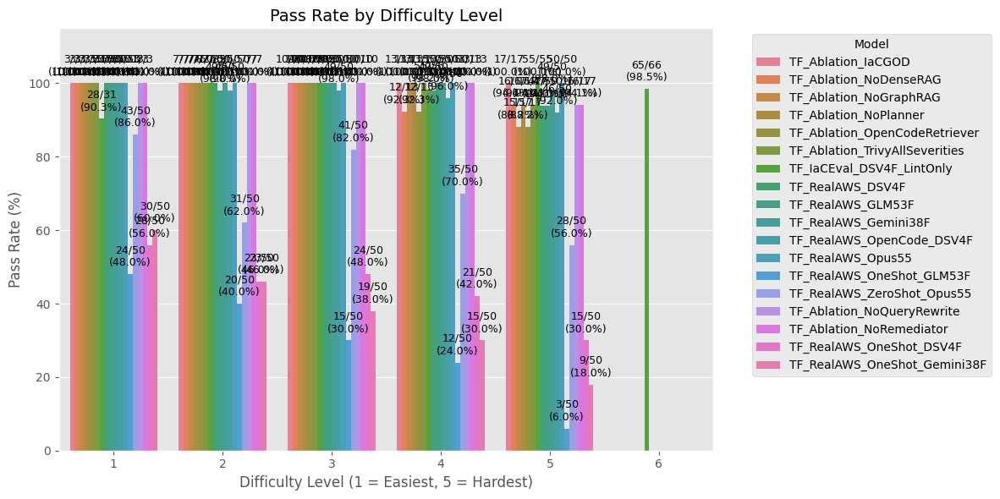

None

In [5]:
def _plot_pass_rate_by_difficulty(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    difficulty_stats = []

    print("📊 Overall Pass Rates:")
    for model_name, df in dfs.items():
        diff_col = 'difficulty_level' if 'difficulty_level' in df.columns else 'difficulty'
        val_col = 'final_validation_passed' if 'final_validation_passed' in df.columns else ('deploy_pass' if 'deploy_pass' in df.columns else None)

        if diff_col in df.columns and val_col in df.columns:
            total_passed = int(df[val_col].sum())
            total_scenarios = len(df)
            overall_rate = (total_passed / total_scenarios * 100) if total_scenarios > 0 else 0
            print(f"  -> {model_name}: {total_passed}/{total_scenarios} ({overall_rate:.1f}%)")

            grouped = df.groupby(diff_col)[val_col].agg(['sum', 'count', 'mean'])

            for diff, row in grouped.iterrows():
                passed_cnt = int(row['sum'])
                total_cnt = int(row['count'])
                rate = row['mean'] * 100

                difficulty_stats.append({
                    'Model': model_name,
                    'Difficulty Level': diff,
                    'Passed': passed_cnt,
                    'Total': total_cnt,
                    'Pass Rate (%)': rate
                })

    if difficulty_stats:
        diff_df = pd.DataFrame(difficulty_stats)

        plt.figure(figsize=(12, 6))
        ax = sns.barplot(data=diff_df, x='Difficulty Level', y='Pass Rate (%)', hue='Model')

        plt.title('Pass Rate by Difficulty Level', fontsize=14)
        plt.ylim(0, 115)
        plt.xlabel('Difficulty Level (1 = Easiest, 5 = Hardest)')
        plt.ylabel('Pass Rate (%)')

        plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')

        for i, container in enumerate(ax.containers):
            model_name = ax.get_legend().get_texts()[i].get_text()

            for j, p in enumerate(container):
                height = p.get_height()
                if pd.isna(height) or (height == 0 and p.get_y() == 0):
                    continue

                diff_level = ax.get_xticklabels()[j].get_text()

                row = diff_df[(diff_df['Model'] == model_name) & (diff_df['Difficulty Level'].astype(str) == diff_level)]

                if not row.empty:
                    passed = row['Passed'].values[0]
                    total = row['Total'].values[0]
                    rate = row['Pass Rate (%)'].values[0]

                    label_text = f"{passed}/{total}\n({rate:.1f}%)"

                    ax.annotate(label_text,
                                (p.get_x() + p.get_width() / 2., height),
                                ha='center', va='bottom',
                                xytext=(0, 5), textcoords='offset points',
                                fontsize=9)

        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ Could not find difficulty or validation columns to plot Pass Rate.")

_out_pass_rate_by_difficulty = widgets.interactive_output(_plot_pass_rate_by_difficulty, {'selected_models': model_selector})
display(_out_pass_rate_by_difficulty)

📊 Calculating Cumulative Pass Rates by Iteration Milestones...





None

In [6]:
def _plot_pass_at_n(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    target_iterations = [1, 5, 10, 15]
    iteration_stats = []

    print("📊 Calculating Cumulative Pass Rates by Iteration Milestones...")
    for model_name, df in dfs.items():
        diff_col = 'difficulty_level' if 'difficulty_level' in df.columns else 'difficulty'
        val_col = 'final_validation_passed' if 'final_validation_passed' in df.columns else ('deploy_pass' if 'deploy_pass' in df.columns else None)
        iter_col = 'iterations_used'

        if diff_col in df.columns and val_col in df.columns and iter_col in df.columns:
            df[iter_col] = pd.to_numeric(df[iter_col], errors='coerce')

            for diff in sorted(df[diff_col].dropna().unique()):
                subset = df[df[diff_col] == diff]
                total_in_diff = len(subset)

                if total_in_diff == 0:
                    continue

                for t_iter in target_iterations:
                    passed_subset = subset[(subset[val_col] == 1) & (subset[iter_col] <= t_iter)]
                    pass_rate = (len(passed_subset) / total_in_diff) * 100

                    iteration_stats.append({
                        'Model': model_name,
                        'Difficulty Level': str(diff),
                        'Iteration Limit': f'≤ {t_iter}',
                        'Iteration_Num': t_iter,
                        'Pass Rate (%)': pass_rate
                    })
        else:
            print(f"⚠️ Missing required columns for model {model_name}. Need difficulty, validation, and 'iterations_used'.")

    if iteration_stats:
        iter_df = pd.DataFrame(iteration_stats).sort_values(by=['Model', 'Difficulty Level', 'Iteration_Num'])

        g = sns.catplot(
            data=iter_df,
            kind="point",
            x="Iteration Limit",
            y="Pass Rate (%)",
            hue="Difficulty Level",
            col="Model",
            palette="viridis",
            height=5.5,
            aspect=1.3,
            markers=["o", "s", "D", "^", "v", "P", "X", "*"][:len(iter_df['Difficulty Level'].unique())],
            linestyles="-"
        )

        g.set_axis_labels("Iteration Milestones", "Cumulative Pass Rate (%)")
        g.set(ylim=(-5, 105))
        g.fig.suptitle('Cumulative Pass Rate by Iteration Milestones (Actual LLM Effort)', fontsize=16, y=1.05)

        for ax in g.axes.flat:
            for line in ax.lines:
                if len(line.get_xdata()) > 0:
                    x_last = line.get_xdata()[-1]
                    y_last = line.get_ydata()[-1]
                    if pd.notna(y_last):
                        ax.annotate(
                            f'{y_last:.1f}%',
                            xy=(x_last, y_last),
                            xytext=(10, 0),
                            textcoords='offset points',
                            ha='left', va='center',
                            fontsize=9,
                            fontweight='bold'
                        )

        plt.show()
    else:
        print("⚠️ No valid data processed for iteration milestones.")

_out_pass_at_n = widgets.interactive_output(_plot_pass_at_n, {'selected_models': model_selector})
display(_out_pass_at_n)

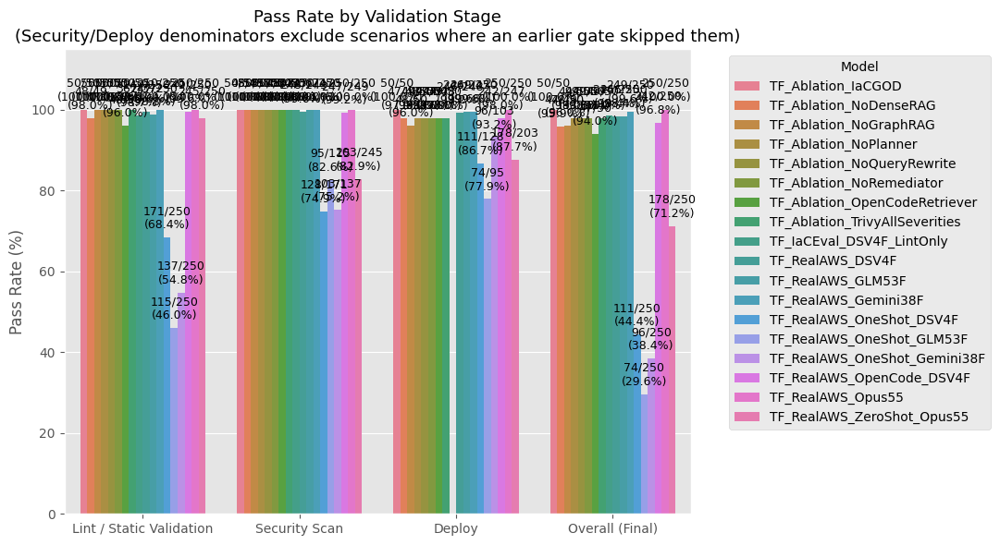

📊 Stage pass rates -- 'Total' is scenarios that actually reached that stage (excludes ones an earlier gate already skipped them past):


,Model,Stage,Passed,Total,Pass Rate (%)
0,TF_Ablation_IaCGOD,Lint / Static Validation,50,50,100.0
1,TF_Ablation_NoDenseRAG,Lint / Static Validation,48,49,98.0
2,TF_Ablation_NoGraphRAG,Lint / Static Validation,50,50,100.0
3,TF_Ablation_NoPlanner,Lint / Static Validation,50,50,100.0
4,TF_Ablation_NoQueryRewrite,Lint / Static Validation,50,50,100.0
...,...,...,...,...,...
66,TF_RealAWS_OneShot_GLM53F,Overall (Final),74,250,29.6
67,TF_RealAWS_OneShot_Gemini38F,Overall (Final),96,250,38.4
68,TF_RealAWS_OpenCode_DSV4F,Overall (Final),242,250,96.8
69,TF_RealAWS_Opus55,Overall (Final),250,250,100.0


None

In [7]:
STAGE_CONFIG = [
    {"key": "tflint",              "label": "TFLint",             "all_col": "all_yaml_errors",     "latest_col": "latest_error_tflint",             "passed_col": "val_stage_tflint_passed"},
    {"key": "terraform-validate",  "label": "terraform validate", "all_col": "all_cfn_lint_errors", "latest_col": "latest_error_terraform-validate", "passed_col": "val_stage_terraform-validate_passed"},
    {"key": "trivy",               "label": "Trivy/Security",     "all_col": "all_security_errors", "latest_col": "latest_error_trivy",              "passed_col": "val_stage_trivy_passed"},
]

lint_keys = [s["key"] for s in STAGE_CONFIG if s["key"] != "trivy"]
security_keys = [s["key"] for s in STAGE_CONFIG if s["key"] == "trivy"]
stage_col_map = {s["key"]: s["passed_col"] for s in STAGE_CONFIG}

def stage_rate(df: pd.DataFrame, keys: list, gate_keys: list = None):
    cols = [stage_col_map[k] for k in keys if stage_col_map[k] in df.columns]
    if not cols:
        return None, None
    reached = df[cols].notna().all(axis=1)
    if gate_keys:
        gate_cols = [stage_col_map[k] for k in gate_keys if stage_col_map[k] in df.columns]
        if gate_cols:
            reached = reached & df[gate_cols].eq(True).all(axis=1)
    passed = reached & df[cols].eq(True).all(axis=1)
    return int(passed.sum()), int(reached.sum())

def _plot_pass_rate_by_stage(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    stage_pass_rows = []
    for model_name, df in dfs.items():
        for label, keys, gate in [
            ("Lint / Static Validation", lint_keys, None),
            ("Security Scan", security_keys, lint_keys),
        ]:
            p, t = stage_rate(df, keys, gate_keys=gate)
            if t:
                stage_pass_rows.append({"Model": model_name, "Stage": label, "Passed": p, "Total": t, "Pass Rate (%)": p / t * 100})

        if "deploy_passed" in df.columns:
            gate_cols = [stage_col_map[k] for k in (lint_keys + security_keys) if stage_col_map[k] in df.columns]
            reached = df[gate_cols].eq(True).all(axis=1) if gate_cols else pd.Series(True, index=df.index)
            if "deploy_target" in df.columns:
                reached = reached & (df["deploy_target"] != "skipped")
            passed = reached & (df["deploy_passed"] == True)
            t = int(reached.sum())
            if t:
                stage_pass_rows.append({"Model": model_name, "Stage": "Deploy", "Passed": int(passed.sum()), "Total": t, "Pass Rate (%)": passed.sum() / t * 100})

        if "final_validation_passed" in df.columns:
            s = df["final_validation_passed"]
            t = int(s.notna().sum())
            if t:
                stage_pass_rows.append({"Model": model_name, "Stage": "Overall (Final)", "Passed": int((s == True).sum()), "Total": t, "Pass Rate (%)": (s == True).sum() / t * 100})

    if stage_pass_rows:
        stage_df = pd.DataFrame(stage_pass_rows)
        stage_order = ["Lint / Static Validation", "Security Scan", "Deploy", "Overall (Final)"]
        stage_df["Stage"] = pd.Categorical(stage_df["Stage"], categories=stage_order, ordered=True)
        stage_df = stage_df.sort_values(["Stage", "Model"])

        plt.figure(figsize=(11, 6))
        ax = sns.barplot(data=stage_df, x="Stage", y="Pass Rate (%)", hue="Model", order=stage_order)
        plt.title("Pass Rate by Validation Stage\n(Security/Deploy denominators exclude scenarios where an earlier gate skipped them)", fontsize=13)
        plt.ylim(0, 115)
        plt.xlabel("")
        plt.ylabel("Pass Rate (%)")
        plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")

        for i, container in enumerate(ax.containers):
            model_name = ax.get_legend().get_texts()[i].get_text()
            for j, p in enumerate(container):
                height = p.get_height()
                if pd.isna(height) or (height == 0 and p.get_y() == 0):
                    continue
                stage_label = ax.get_xticklabels()[j].get_text()
                row = stage_df[(stage_df["Model"] == model_name) & (stage_df["Stage"].astype(str) == stage_label)]
                if not row.empty:
                    passed = row["Passed"].values[0]
                    total = row["Total"].values[0]
                    rate = row["Pass Rate (%)"].values[0]
                    ax.annotate(f"{passed}/{total}\n({rate:.1f}%)",
                                (p.get_x() + p.get_width() / 2., height),
                                ha="center", va="bottom", xytext=(0, 5),
                                textcoords="offset points", fontsize=9)

        plt.tight_layout()
        plt.show()

        print("📊 Stage pass rates -- 'Total' is scenarios that actually reached that stage "
              "(excludes ones an earlier gate already skipped them past):")
        display(stage_df[["Model", "Stage", "Passed", "Total", "Pass Rate (%)"]]
                .sort_values(["Stage", "Model"]).round(1).reset_index(drop=True))
    else:
        print("⚠️ No stage-level pass/fail columns found.")

_out_pass_rate_by_stage = widgets.interactive_output(_plot_pass_rate_by_stage, {'selected_models': model_selector})
display(_out_pass_rate_by_stage)

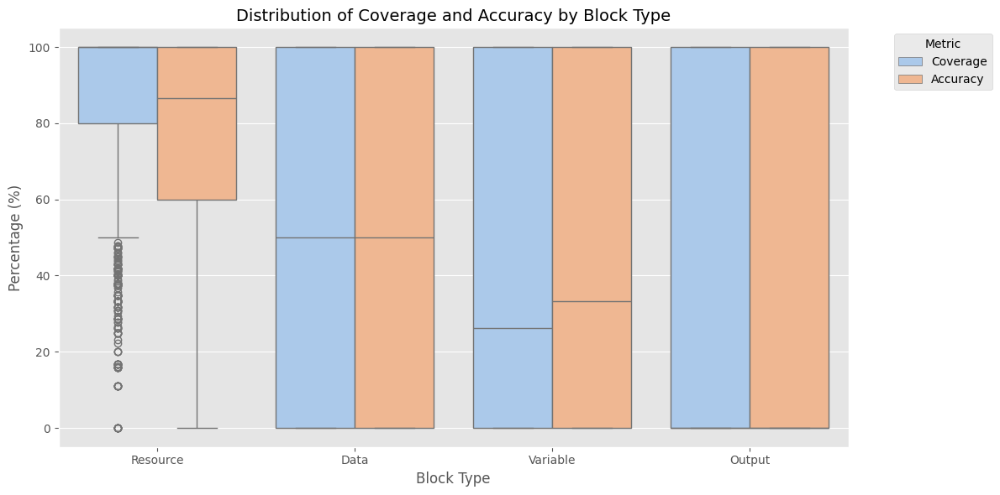

None

In [8]:
block_types = ['resource', 'data', 'variable', 'output']

def _plot_coverage_accuracy_boxplots(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    box_data = []

    for model_name, df in dfs.items():
        if 'coverage_pct' in df.columns:
            for _, row in df.dropna(subset=['coverage_pct', 'accuracy_pct']).iterrows():
                box_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Coverage', 'Percentage': row['coverage_pct']})
                box_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Accuracy', 'Percentage': row['accuracy_pct']})
        else:
            for btype in block_types:
                cov_col, acc_col = f'{btype}_cov_pct', f'{btype}_acc_pct'
                if cov_col in df.columns and acc_col in df.columns:
                    for _, row in df.dropna(subset=[cov_col, acc_col]).iterrows():
                        box_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Coverage', 'Percentage': row[cov_col]})
                        box_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Accuracy', 'Percentage': row[acc_col]})

    if box_data:
        box_df = pd.DataFrame(box_data)
        plt.figure(figsize=(12, 6))
        sns.boxplot(data=box_df, x='Block Type', y='Percentage', hue='Metric', palette='pastel')
        plt.title('Distribution of Coverage and Accuracy by Block Type', fontsize=14)
        plt.ylabel('Percentage (%)')
        plt.ylim(-5, 105)
        plt.legend(title="Metric", bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

_out_coverage_accuracy_boxplots = widgets.interactive_output(_plot_coverage_accuracy_boxplots, {'selected_models': model_selector})
display(_out_coverage_accuracy_boxplots)




None

In [9]:
def _plot_avg_coverage_accuracy(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    avg_metrics_data = []

    for model_name, df in dfs.items():
        if 'coverage_pct' in df.columns:
            avg_metrics_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Coverage (%)', 'Value': df['coverage_pct'].mean()})
            avg_metrics_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Accuracy (%)', 'Value': df['accuracy_pct'].mean()})
        else:
            for btype in block_types:
                cov_col, acc_col = f'{btype}_cov_pct', f'{btype}_acc_pct'
                if cov_col in df.columns and acc_col in df.columns:
                    avg_metrics_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Coverage (%)', 'Value': df[cov_col].mean()})
                    avg_metrics_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Accuracy (%)', 'Value': df[acc_col].mean()})

    if avg_metrics_data:
        avg_df = pd.DataFrame(avg_metrics_data)

        g = sns.catplot(
            data=avg_df, kind="bar",
            x="Block Type", y="Value", hue="Metric", col="Model",
            palette="viridis", height=5, aspect=1.2
        )

        g.set_axis_labels("", "Percentage (%)")
        g.set(ylim=(0, 115))
        g.fig.suptitle('Average Coverage and Accuracy by Block Type', fontsize=16, y=1.05)

        for ax in g.axes.flat:
            for p in ax.patches:
                height = p.get_height()
                if pd.notna(height) and height > 0:
                    ax.text(p.get_x() + p.get_width() / 2., height + 2, f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

        plt.show()

_out_avg_coverage_accuracy = widgets.interactive_output(_plot_avg_coverage_accuracy, {'selected_models': model_selector})
display(_out_avg_coverage_accuracy)




None

In [10]:
def _plot_resource_alignment(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    overprovisioning_data = []

    for model_name, df in dfs.items():
        if 'correct_resources' in df.columns:
            overprovisioning_data.append({'Model': model_name, 'Block Type': 'Resource', 'Status': 'Correctly Provisioned', 'Total': df['correct_resources'].sum()})
            overprovisioning_data.append({'Model': model_name, 'Block Type': 'Resource', 'Status': 'Extra (Overprovisioned)', 'Total': df['extra_resources'].sum()})
        else:
            for btype in block_types:
                cor_col, ext_col = f'{btype}_cor', f'{btype}_extra'
                if cor_col in df.columns and ext_col in df.columns:
                    overprovisioning_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Status': 'Correctly Provisioned', 'Total': df[cor_col].sum()})
                    overprovisioning_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Status': 'Extra (Overprovisioned)', 'Total': df[ext_col].sum()})

    if overprovisioning_data:
        over_df = pd.DataFrame(overprovisioning_data)

        g = sns.catplot(
            data=over_df, kind="bar",
            x="Block Type", y="Total", hue="Status", col="Model",
            palette="Set2", height=5, aspect=1.2, sharey=False
        )

        g.set_axis_labels("", "Total Raw Count")
        g.fig.suptitle('Alignment: Correct vs Overprovisioned by Block Type', fontsize=16, y=1.05)

        for ax in g.axes.flat:
            for p in ax.patches:
                height = p.get_height()
                if pd.notna(height) and height > 0:
                    ax.text(p.get_x() + p.get_width() / 2., height + (ax.get_ylim()[1] * 0.02), f'{int(height)}', ha='center', va='bottom', fontsize=10)

        plt.show()

_out_resource_alignment = widgets.interactive_output(_plot_resource_alignment, {'selected_models': model_selector})
display(_out_resource_alignment)

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


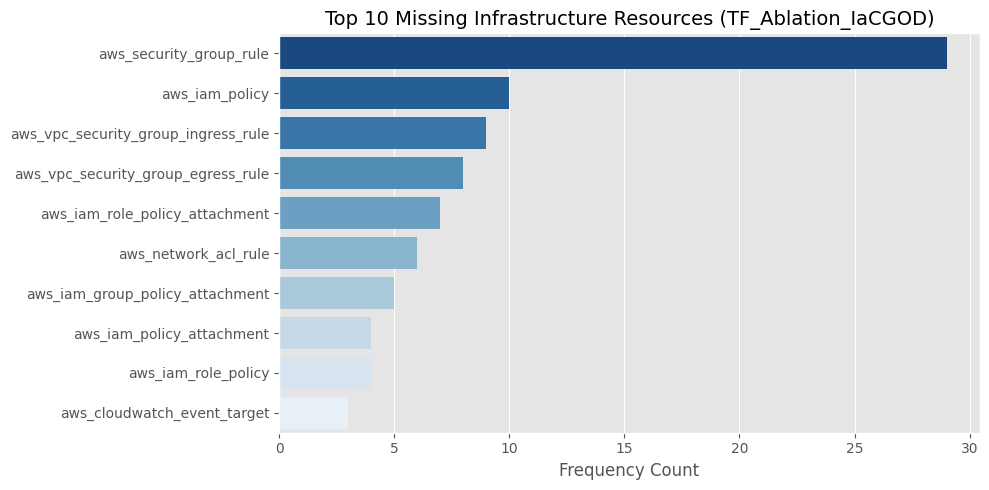

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


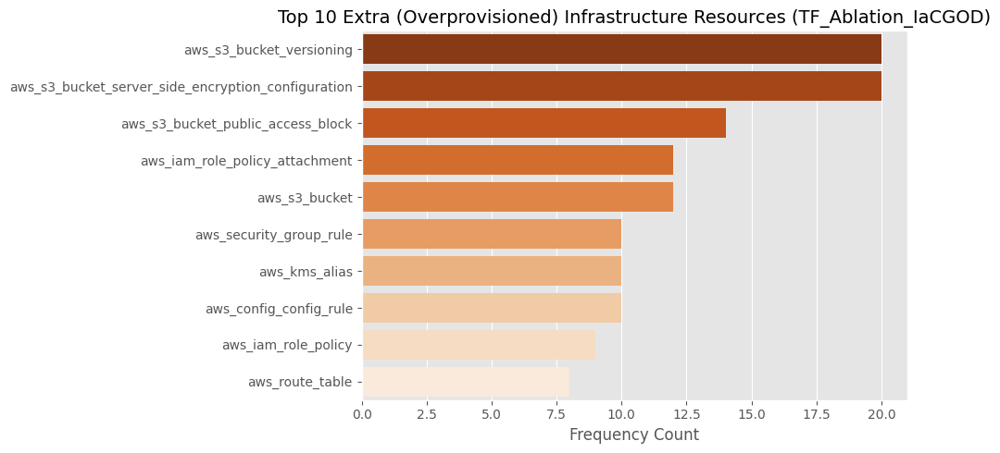

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


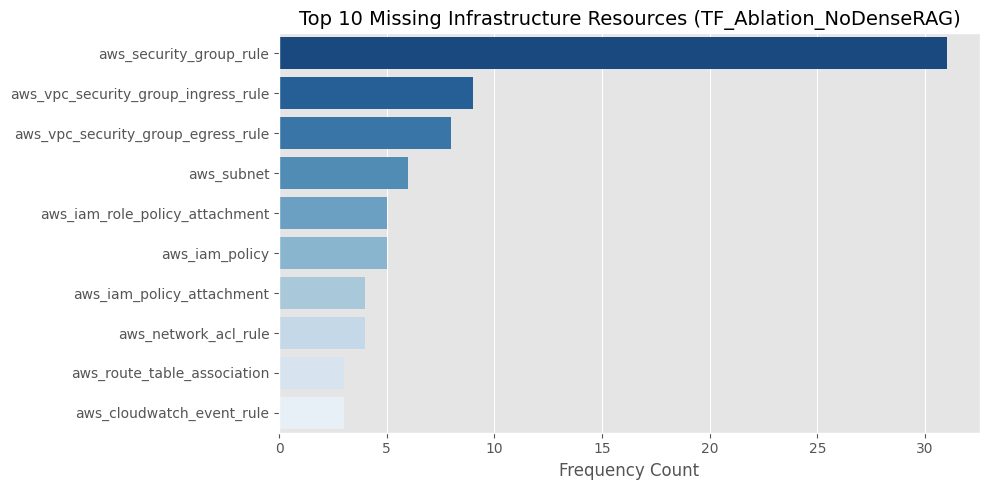

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


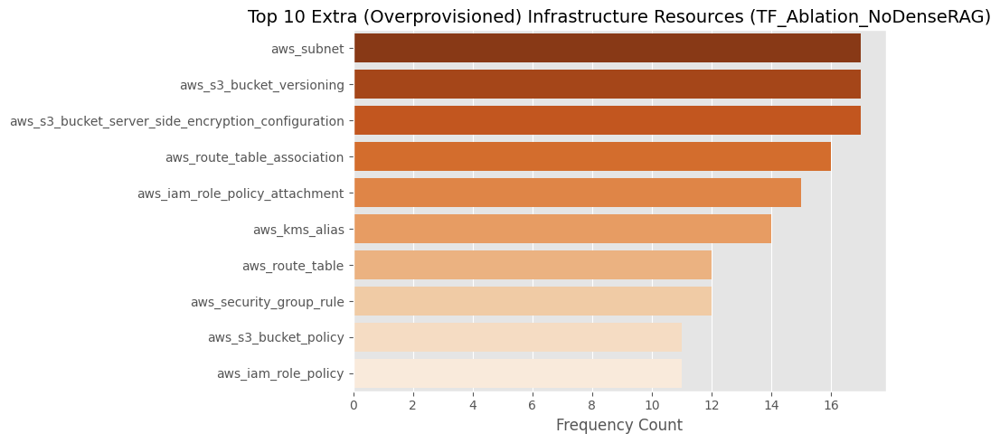

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


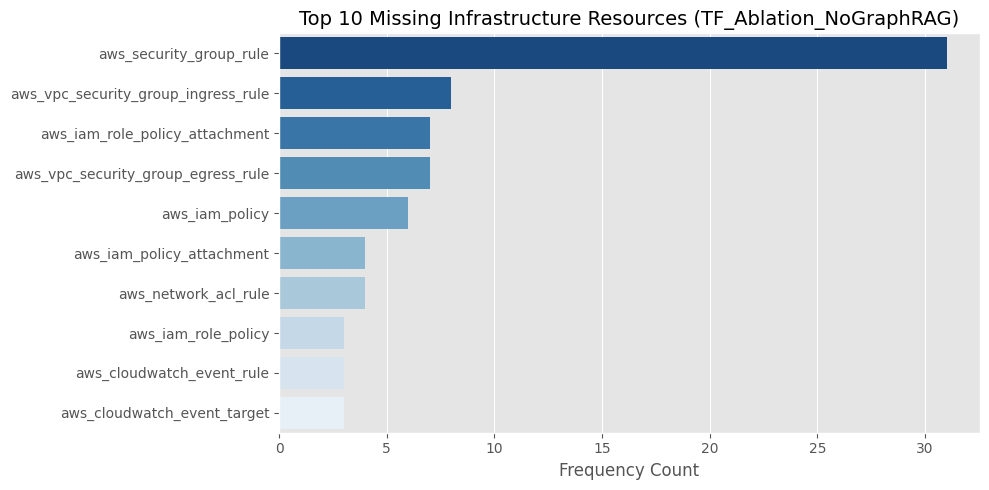

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


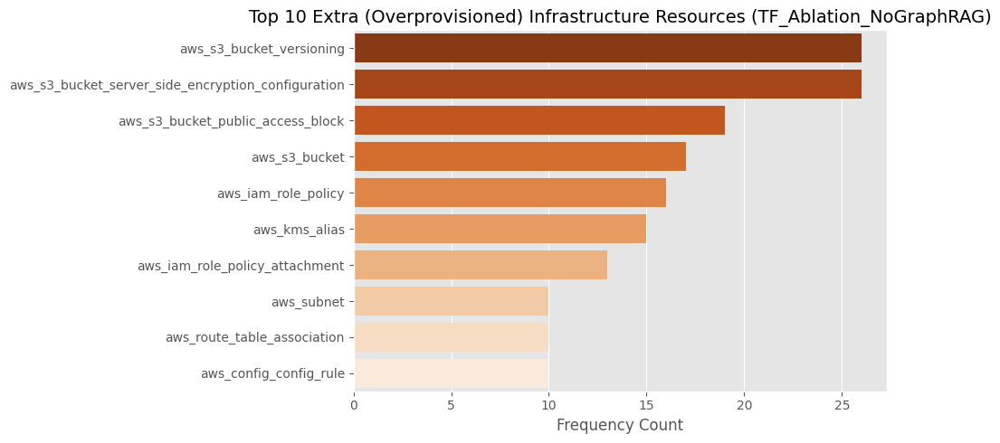

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


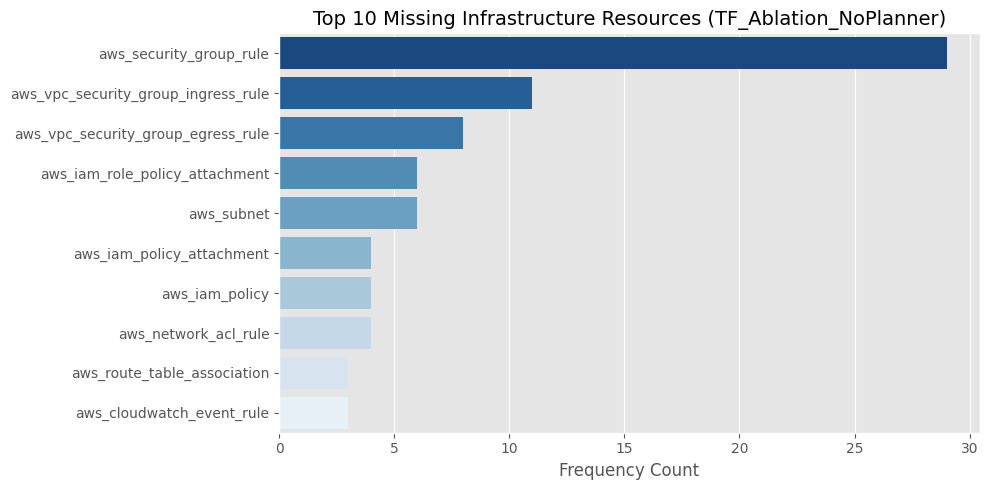

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


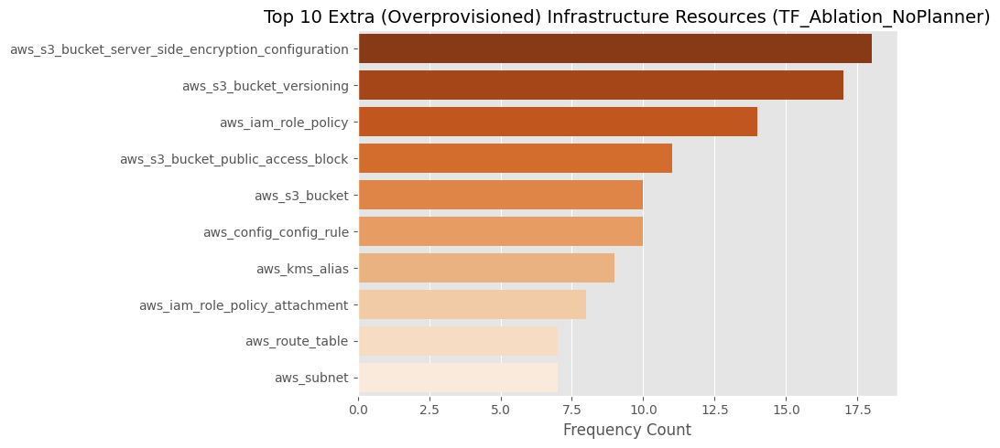

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


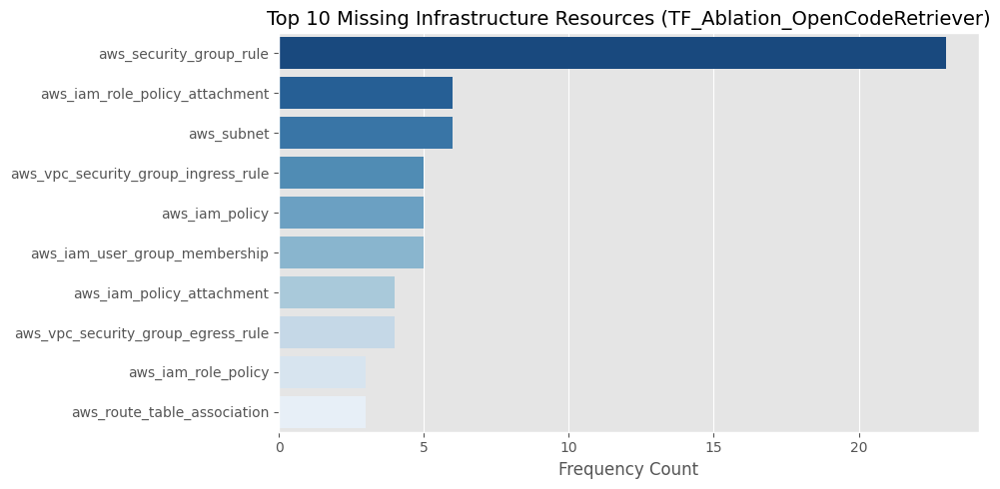

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


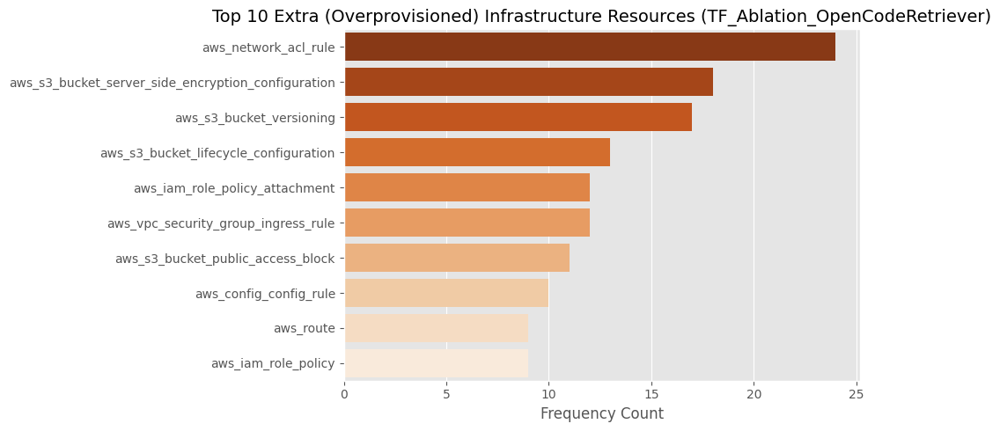

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


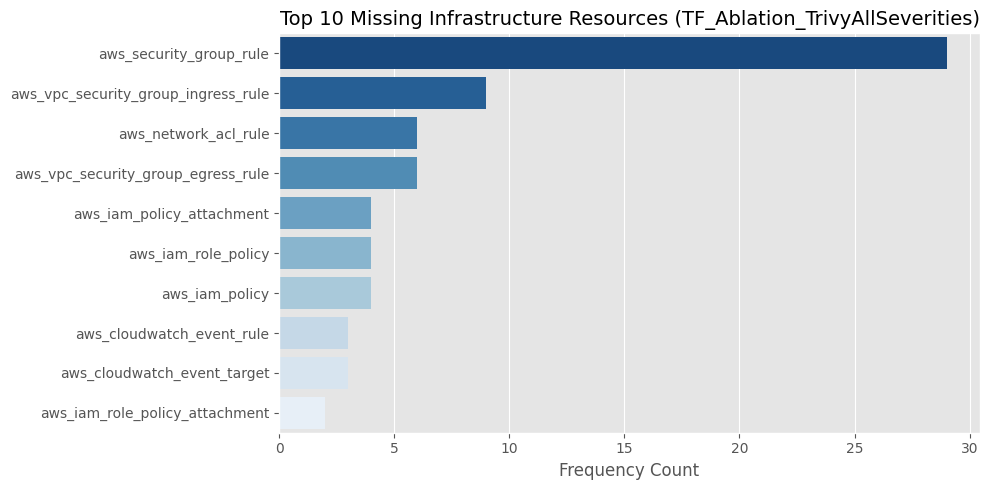

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


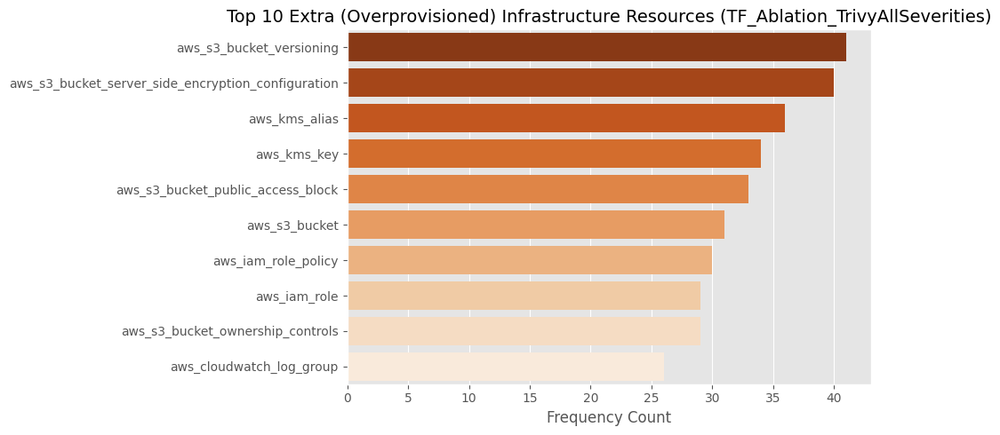

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


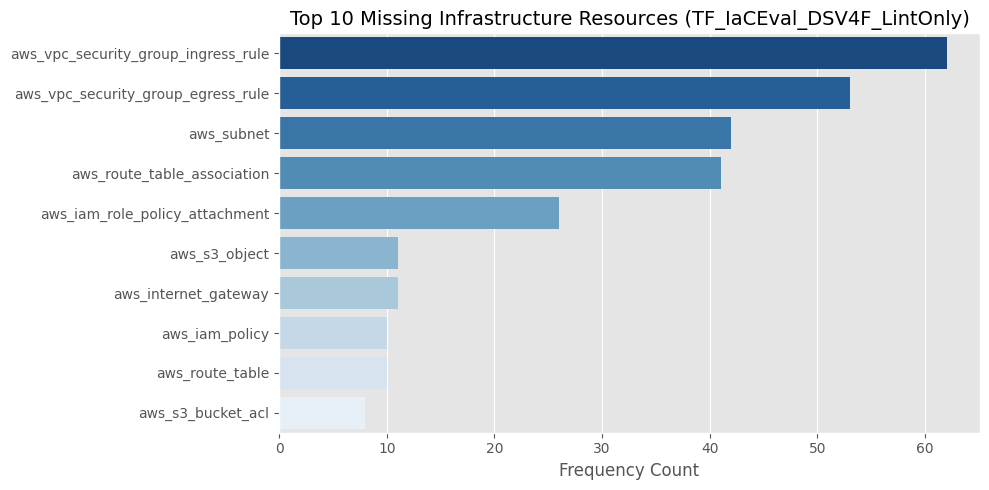

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


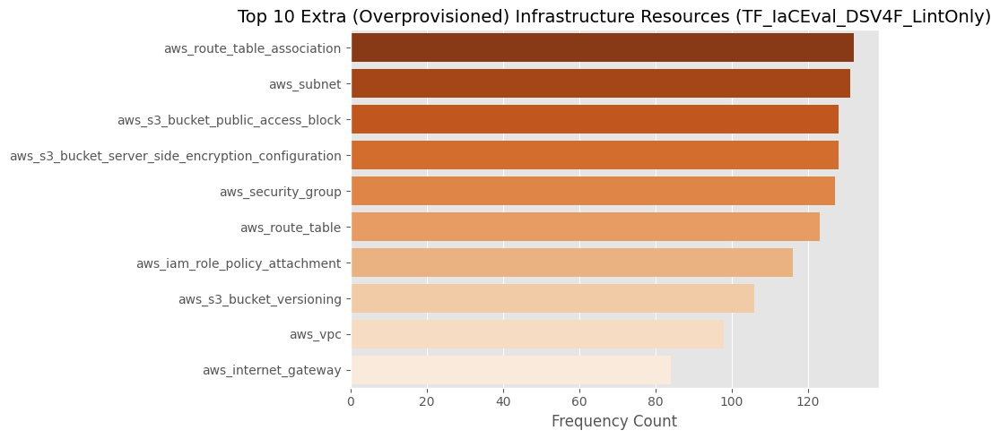

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


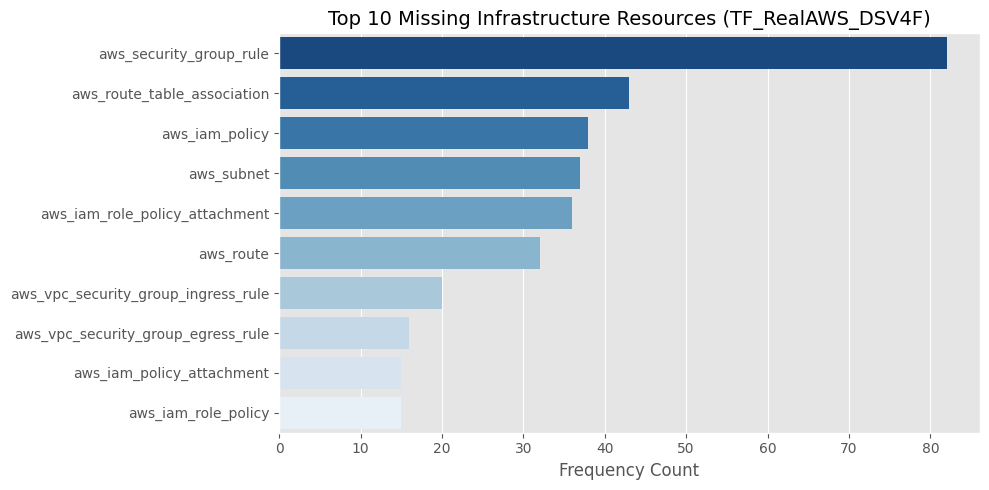

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


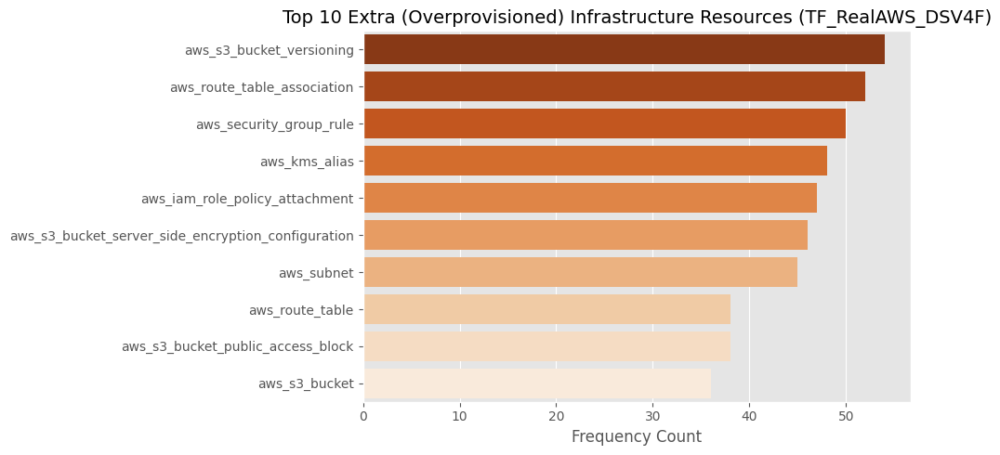

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


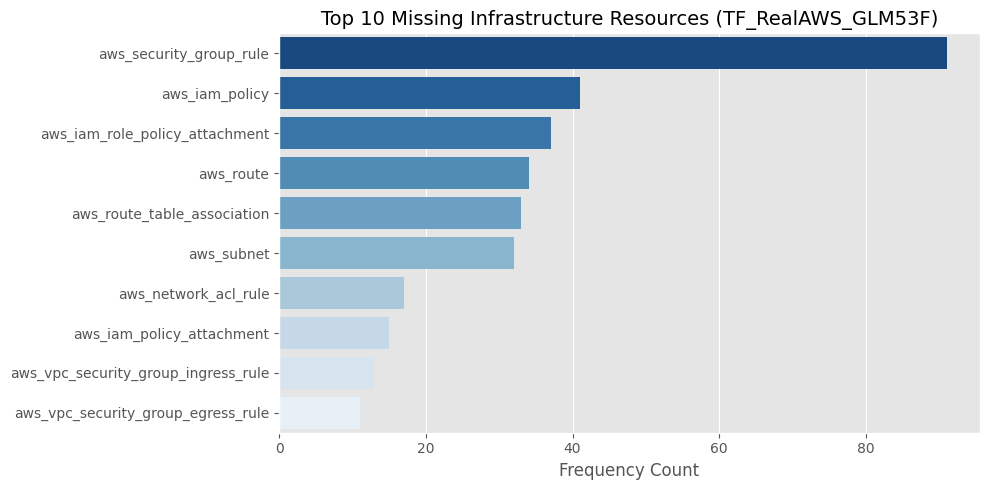

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


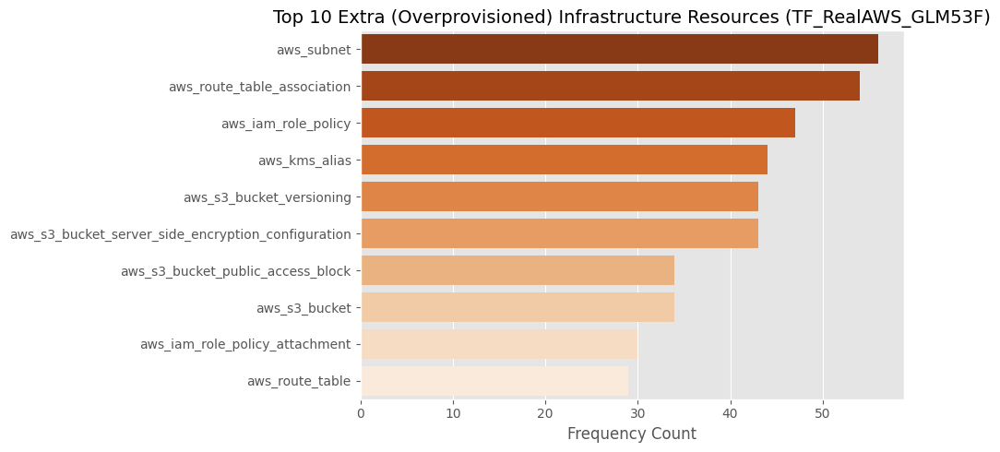

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


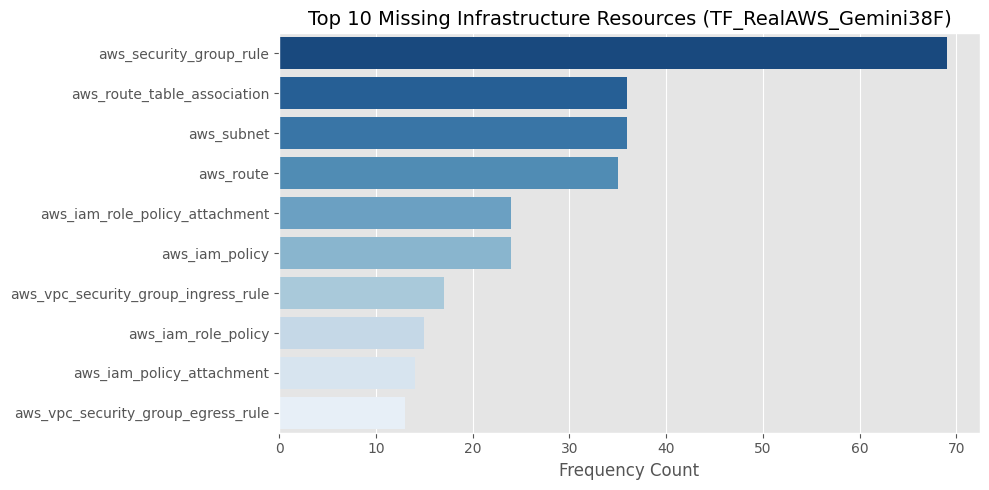

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


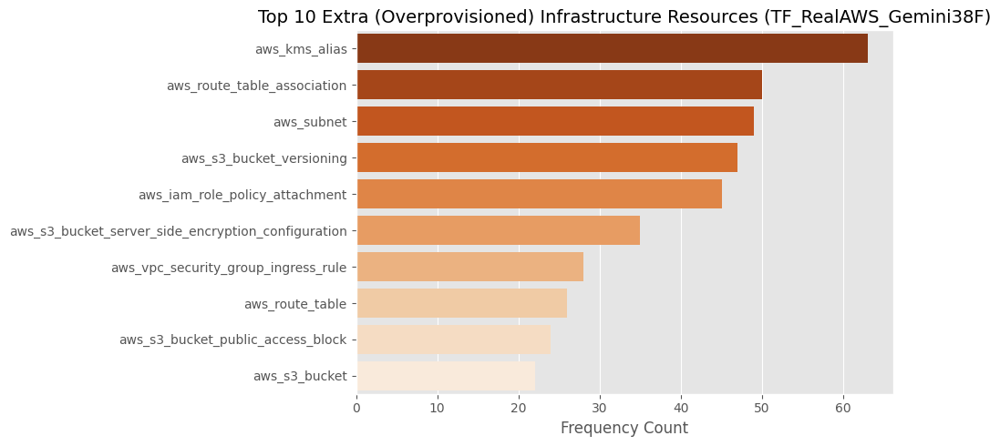

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


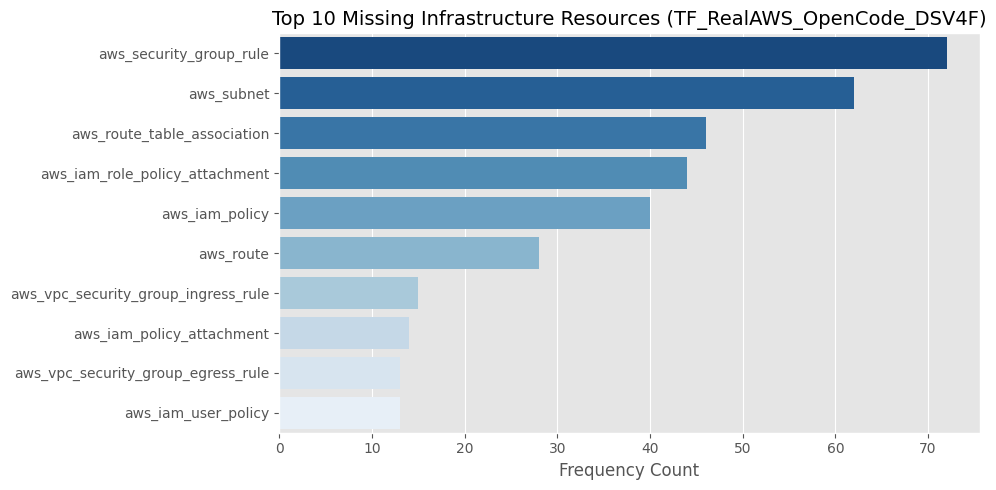

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


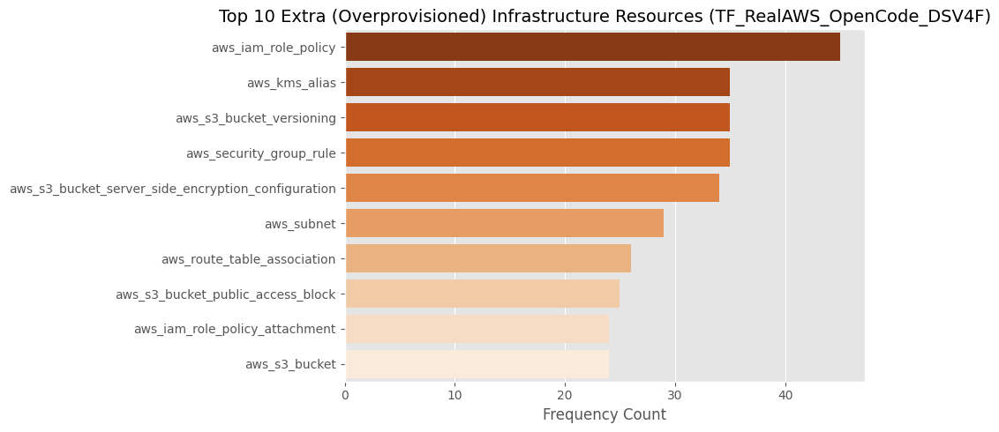

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


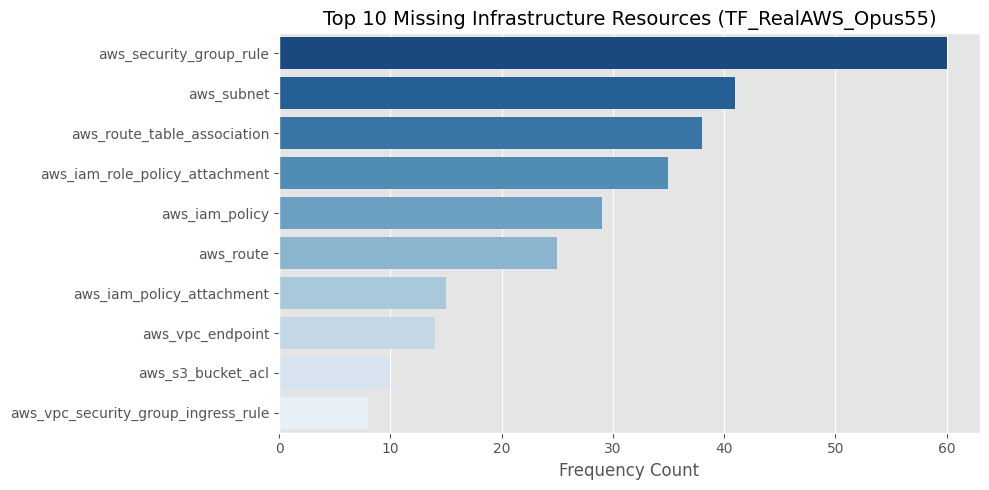

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


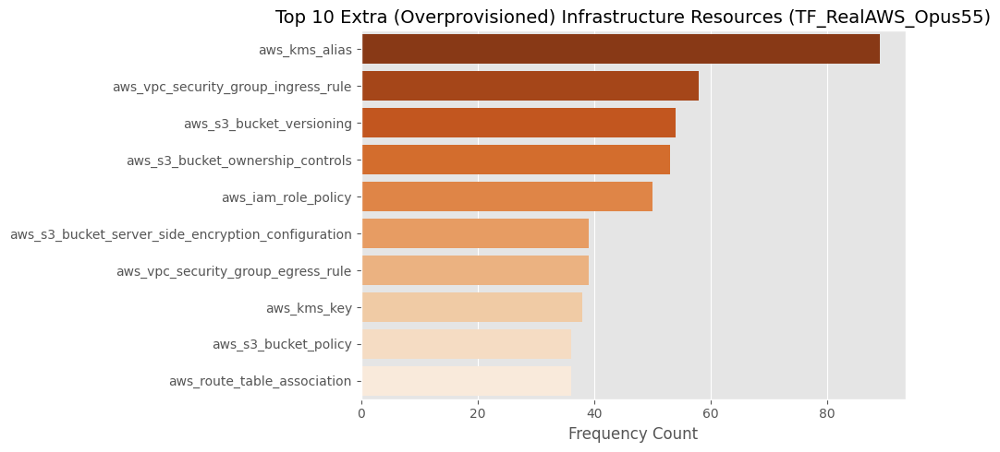

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


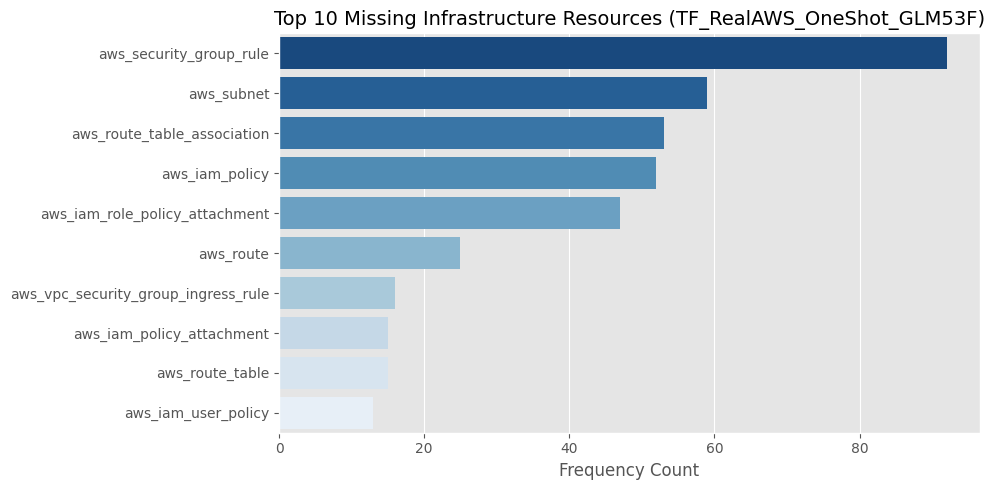

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


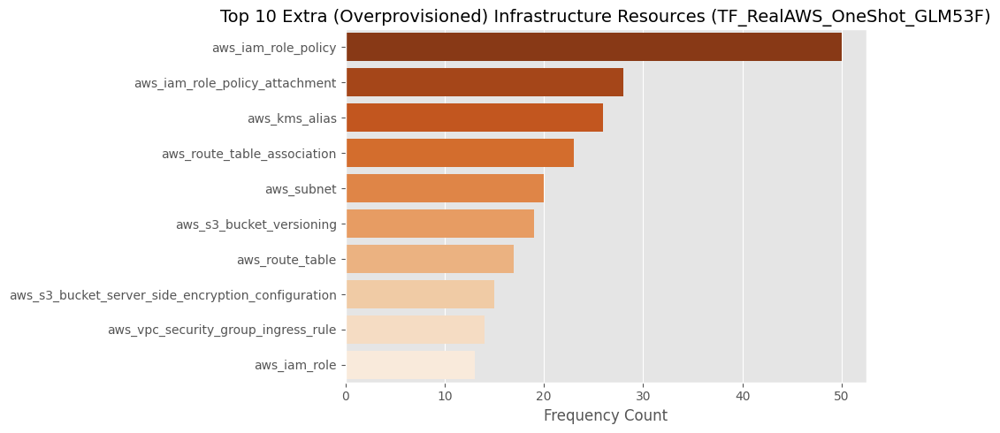

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


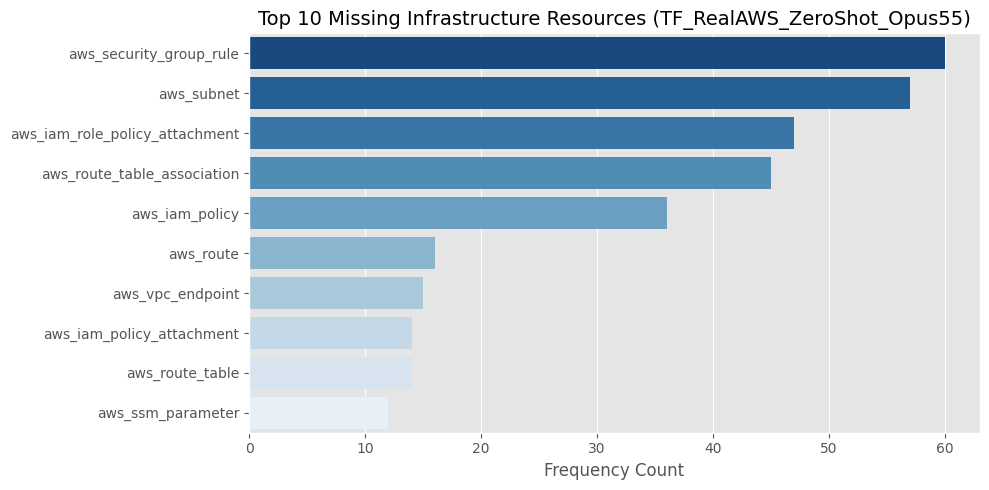

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


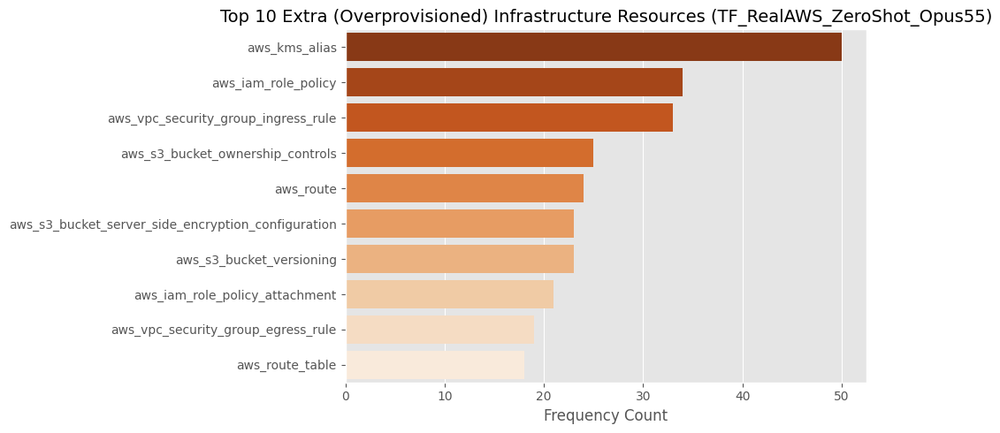

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


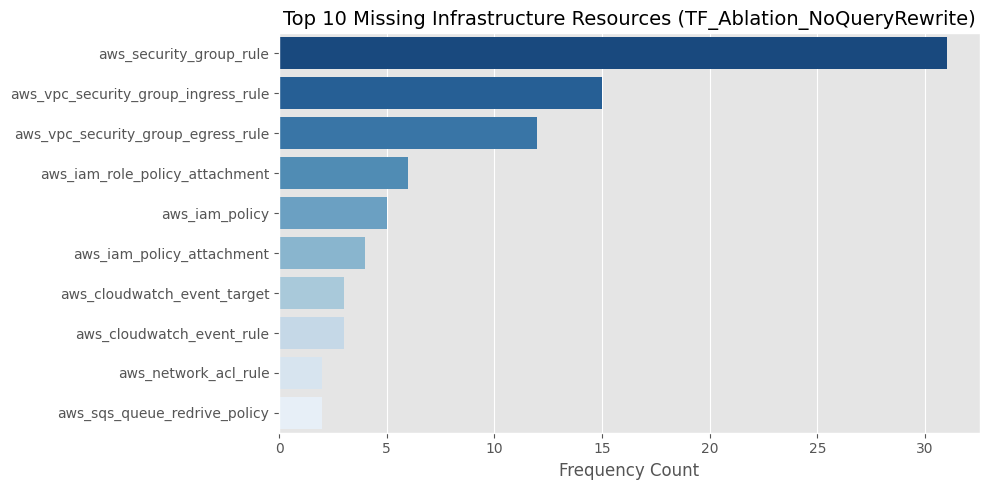

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


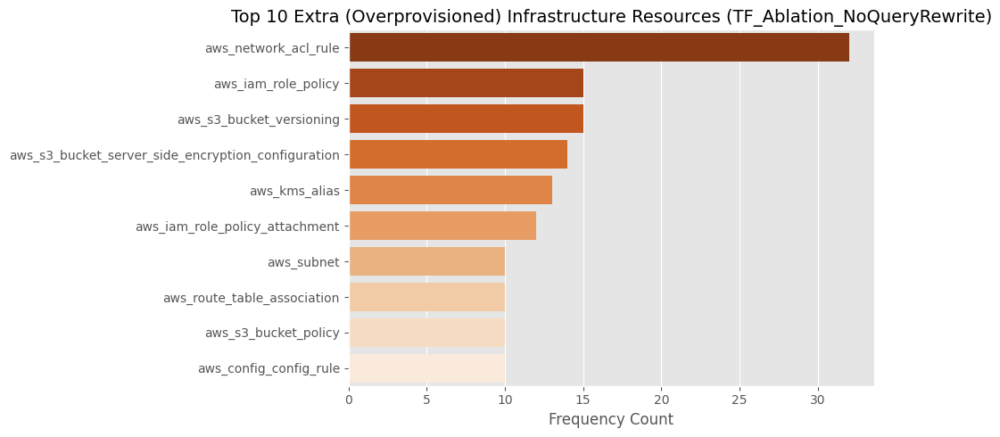

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


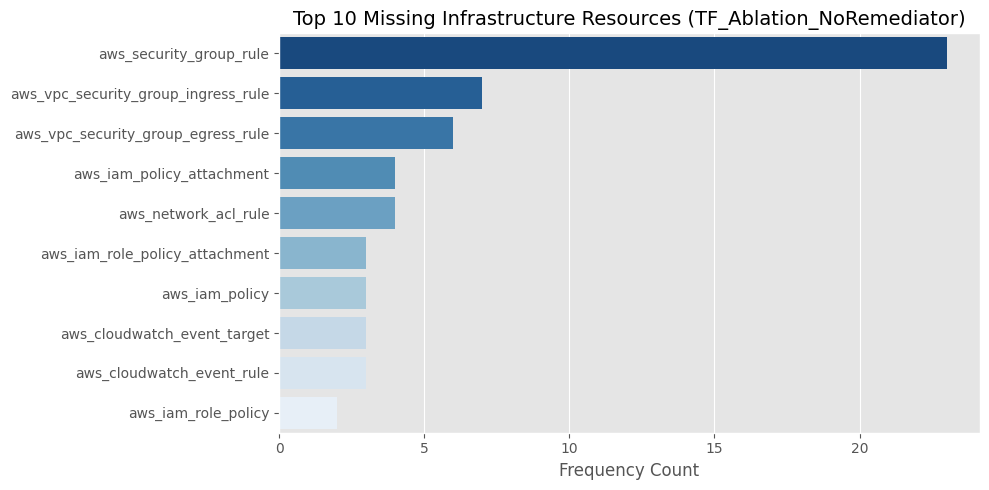

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


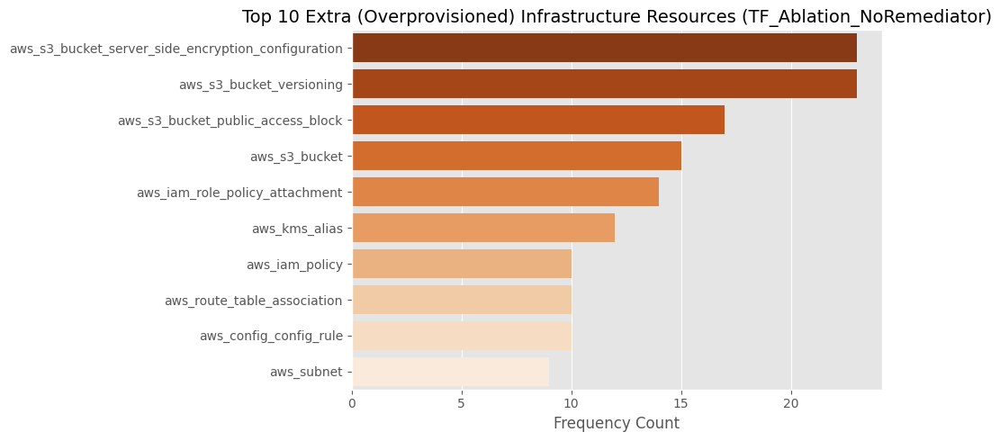

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


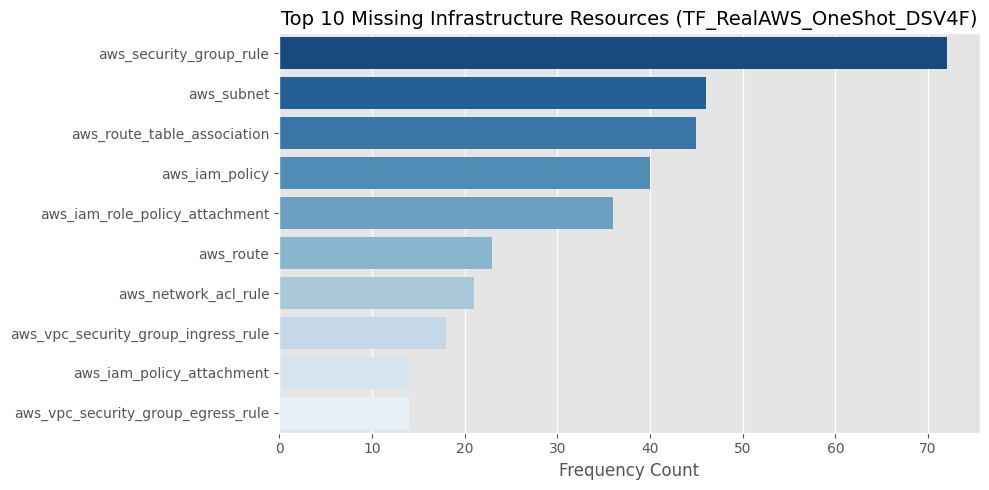

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


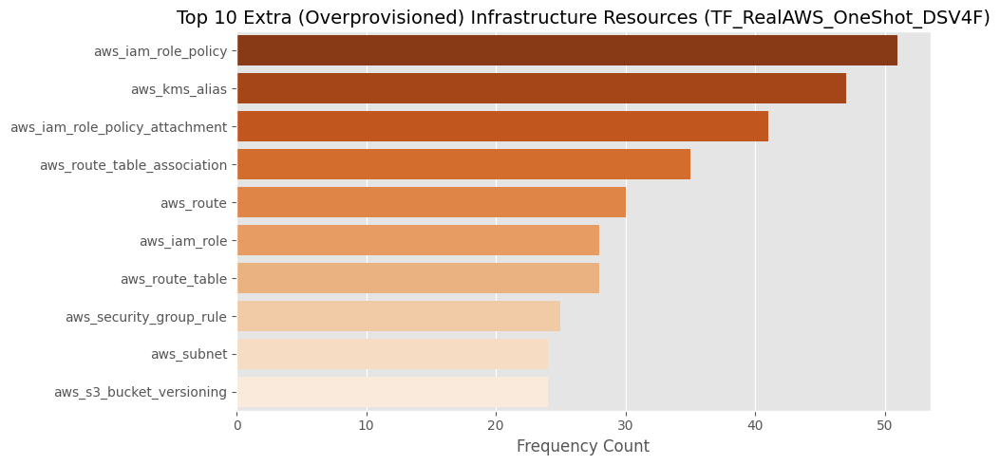

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


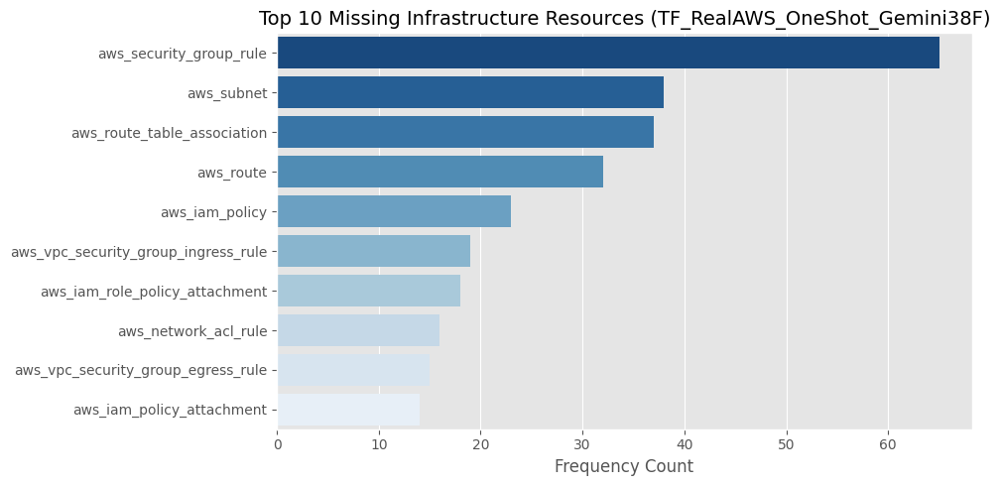

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_49730/3011957370.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


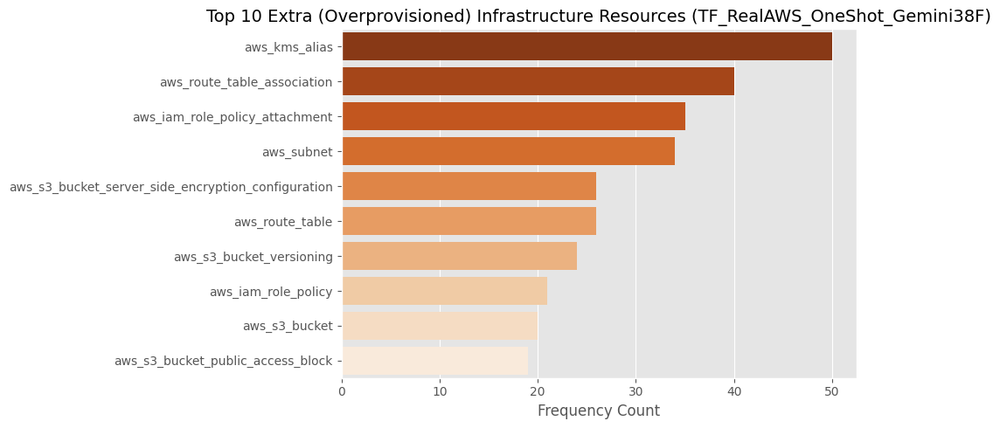

None

In [11]:
def _plot_top_missing_extra_resources(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}

    for model_name, df in dfs.items():
        missing_counter = Counter()
        extra_counter = Counter()

        missing_col = 'resource_missing_list' if 'resource_missing_list' in df.columns else 'missing_resource_types'
        extra_col = 'resource_extra_list' if 'resource_extra_list' in df.columns else 'extra_resource_types'

        if missing_col in df.columns:
            for items in df[missing_col].dropna():
                for item in str(items).split(';'):
                    if item.strip():
                        missing_counter[item.strip()] += 1

        if extra_col in df.columns:
            for items in df[extra_col].dropna():
                for item in str(items).split(';'):
                    if item.strip():
                        extra_counter[item.strip()] += 1

        top_missing = pd.DataFrame(missing_counter.most_common(10), columns=['Resource Type', 'Frequency'])
        top_extra = pd.DataFrame(extra_counter.most_common(10), columns=['Resource Type', 'Frequency'])

        if not top_missing.empty:
            plt.figure(figsize=(10, 5))
            sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')
            plt.title(f'Top 10 Missing Infrastructure Resources ({model_name})', fontsize=14)
            plt.xlabel('Frequency Count')
            plt.ylabel('')
            plt.tight_layout()
            plt.show()

        if not top_extra.empty:
            plt.figure(figsize=(10, 5))
            sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')
            plt.title(f'Top 10 Extra (Overprovisioned) Infrastructure Resources ({model_name})', fontsize=14)
            plt.xlabel('Frequency Count')
            plt.ylabel('')
            plt.tight_layout()
            plt.show()

_out_top_missing_extra_resources = widgets.interactive_output(_plot_top_missing_extra_resources, {'selected_models': model_selector})
display(_out_top_missing_extra_resources)

In [12]:
df = list(merged_dataframes.values())[-1]
df.columns

Index(['row_number', 'ground_truth_path', 'run_id', 'status',
       'final_validation_passed', 'iterations_used', 'llm_calls_total',
       'token_all_tokens', 'token_input_tokens', 'token_output_tokens',
       'token_prompt_tokens', 'token_completion_tokens',
       'token_cache_creation_input_tokens', 'token_cache_read_input_tokens',
       'token_reasoning_tokens', 'scenario_policy_pass_rate',
       'filtered_compliance_rate', 'unfiltered_compliance_rate',
       'duration_seconds', 'error_message', 'error_traceback',
       'extraction_method', 'policy_total_policies', 'policy_passed_policies',
       'final_template', 'deploy_target', 'deploy_passed', 'deploy_stack_id',
       'deploy_error_message', 'deploy_logs', 'deploy_duration_seconds',
       'deploy_failed_resources', 'deploy_completed_resources',
       'total_yaml_errors', 'total_cfn_lint_errors', 'total_security_errors',
       'all_yaml_errors', 'all_cfn_lint_errors', 'all_security_errors',
       'latest_error_tflin


TF_Ablation_IaCGOD: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,179,16.67,22.22,True,iac_benchmark/scenarios/gh_7ae21b79



TF_Ablation_NoDenseRAG: 1/49 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,231,15.79,16.67,True,iac_benchmark/scenarios_greenfield/terrads_b7c89fdf0ecb



TF_Ablation_NoGraphRAG: 0/50 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_Ablation_NoPlanner: 0/50 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_Ablation_OpenCodeRetriever: 0/50 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_Ablation_TrivyAllSeverities: 0/50 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_IaCEval_DSV4F_LintOnly: 6/372 scenarios (1.6%) below 30% on both coverage and accuracy.
  ⚠️ 5 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,122,0.00,0.0,True,iac_eval_ground_truth/row_0122_aws-s3-bucket-object.tf
1,124,0.00,0.0,True,iac_eval_ground_truth/row_0124_aws-ami.tf
2,139,0.00,0.0,False,iac_eval_ground_truth/row_0139_aws-redshift-cluster.tf
3,193,0.00,0.0,True,iac_eval_ground_truth/row_0193_aws-elasticache-cluster.tf
4,380,0.00,0.0,True,iac_eval_ground_truth/row_0380_aws-glacier-vault.tf
5,209,23.08,20.0,True,iac_eval_ground_truth/row_0209_aws-msk-serverless-cluster.tf



TF_RealAWS_DSV4F: 1/250 scenarios (0.4%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,179,16.67,25.0,True,iac_benchmark/scenarios/gh_7ae21b79



TF_RealAWS_GLM53F: 1/250 scenarios (0.4%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,231,15.79,25.0,True,iac_benchmark/scenarios_greenfield/terrads_b7c89fdf0ecb



TF_RealAWS_Gemini38F: 0/250 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_RealAWS_OpenCode_DSV4F: 2/250 scenarios (0.8%) below 30% on both coverage and accuracy.
  ⚠️ 2 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,198,0.00,0.00,True,iac_benchmark/scenarios/terrads_3dbbe8b7f105
1,172,11.11,18.18,True,iac_benchmark/scenarios/terrads_33766381a4b4



TF_RealAWS_Opus55: 0/250 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_RealAWS_OneShot_GLM53F: 4/250 scenarios (1.6%) below 30% on both coverage and accuracy.


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,240,0.00,0.00,False,iac_benchmark/scenarios_greenfield/terrads_8c37ece6a9a8
1,368,0.00,0.00,False,iac_benchmark/scenarios_greenfield/terrads_d8bc612be4e0
2,172,11.11,18.18,False,iac_benchmark/scenarios/terrads_33766381a4b4
3,231,15.79,27.27,False,iac_benchmark/scenarios_greenfield/terrads_b7c89fdf0ecb



TF_RealAWS_ZeroShot_Opus55: 0/250 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_Ablation_NoQueryRewrite: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,coverage_pct,accuracy_pct,final_validation_passed,ground_truth_path
0,231,15.79,27.27,True,iac_benchmark/scenarios_greenfield/terrads_b7c89fdf0ecb



TF_Ablation_NoRemediator: 0/50 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_RealAWS_OneShot_DSV4F: 0/250 scenarios (0.0%) below 30% on both coverage and accuracy.

TF_RealAWS_OneShot_Gemini38F: 0/250 scenarios (0.0%) below 30% on both coverage and accuracy.





In [13]:
DRIFT_THRESHOLD_PCT = 30.0

scenario_diagnostics = {}

for model_name, df in merged_dataframes.items():
    if not {'resource_cov_pct', 'resource_acc_pct'}.issubset(df.columns):
        print(f"⚠️ Skipping {model_name}: no coverage_pct/accuracy_pct columns.")
        continue

    diag_cols = {
        'row_number': df.get('row_number'),
        'difficulty_level': df.get('difficulty_level'),
        'coverage_pct': df['resource_cov_pct'],
        'accuracy_pct': df['resource_acc_pct'],
        'final_validation_passed': df.get('final_validation_passed'),
        'deploy_passed': df.get('deploy_passed'),
        'run_status': df.get('status'),
        'required': df.get('total_required_resources'),
        'generated': df.get('total_generated_resources'),
        'correct': df.get('correct_resources'),
        'missing': df.get('missing_resources'),
        'extra': df.get('extra_resources'),
        'missing_resource_types': df.get('missing_resource_types'),
        'extra_resource_types': df.get('extra_resource_types'),
        'ground_truth_path': df.get('ground_truth_path'),
        'prompt': df.get('prompt'),
    }
    diag_df = pd.DataFrame({k: v for k, v in diag_cols.items() if v is not None})
    diag_df = diag_df.dropna(subset=['coverage_pct', 'accuracy_pct'])

    diag_df['likely_drift'] = (
        (diag_df['coverage_pct'] < DRIFT_THRESHOLD_PCT) &
        (diag_df['accuracy_pct'] < DRIFT_THRESHOLD_PCT)
    )

    scenario_diagnostics[model_name] = diag_df

    n_total = len(diag_df)
    n_flagged = diag_df['likely_drift'].sum()
    n_flagged_but_valid = ((diag_df['likely_drift']) & (diag_df['final_validation_passed'] == True)).sum() \
        if 'final_validation_passed' in diag_df.columns else 0

    print(f"\n{'='*90}\n{model_name}: {n_flagged}/{n_total} scenarios ({n_flagged / n_total:.1%}) "
          f"below {DRIFT_THRESHOLD_PCT:.0f}% on both coverage and accuracy.")
    if n_flagged_but_valid:
        print(f"  ⚠️ {n_flagged_but_valid} of those still PASSED final validation despite the drift -- "
              f"the generated stack was deployable/secure but unrelated to what was asked, which is "
              f"exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed "
              f"alone would have hidden it).")

    if n_flagged:
        display_cols = ['row_number', 'difficulty_level', 'coverage_pct', 'accuracy_pct',
                         'final_validation_passed', 'required', 'generated', 'correct',
                         'missing', 'extra', 'ground_truth_path']
        display_cols = [c for c in display_cols if c in diag_df.columns]
        flagged = diag_df[diag_df['likely_drift']].sort_values('coverage_pct').reset_index(drop=True)
        with pd.option_context('display.max_colwidth', 80, 'display.width', 200):
            display(flagged[display_cols])

if scenario_diagnostics:
    n_models = len(scenario_diagnostics)
    fig, axes = plt.subplots(1, n_models, figsize=(7 * n_models, 6), squeeze=False)
    axes = axes[0]

    for ax, (model_name, diag_df) in zip(axes, scenario_diagnostics.items()):
        ok = diag_df[~diag_df['likely_drift']]
        bad = diag_df[diag_df['likely_drift']]
        ax.scatter(ok['coverage_pct'], ok['accuracy_pct'], alpha=0.5, s=25,
                   label='Normal', color='steelblue')
        ax.scatter(bad['coverage_pct'], bad['accuracy_pct'], alpha=0.8, s=35,
                   label='Likely drift', color='crimson', marker='x')
        ax.axvline(DRIFT_THRESHOLD_PCT, color='gray', linestyle='--', linewidth=1)
        ax.axhline(DRIFT_THRESHOLD_PCT, color='gray', linestyle='--', linewidth=1)
        ax.set_title(model_name, fontsize=13)
        ax.set_xlabel('Coverage %')
        ax.set_ylabel('Accuracy %')
        ax.set_xlim(-5, 105)
        ax.set_ylim(-5, 105)
        ax.legend(loc='lower right', fontsize=9)

    fig.suptitle(f'Coverage vs Accuracy per Scenario (drift threshold = {DRIFT_THRESHOLD_PCT:.0f}%)',
                 fontsize=15, y=1.03)
    plt.tight_layout()
    plt.show()

## Failure Analysis

📊 Failure-stage funnel (first gate that stopped each scenario):


Model,TF_Ablation_IaCGOD,TF_Ablation_NoDenseRAG,TF_Ablation_NoGraphRAG,TF_Ablation_NoPlanner,TF_Ablation_NoQueryRewrite,TF_Ablation_NoRemediator,TF_Ablation_OpenCodeRetriever,TF_Ablation_TrivyAllSeverities,TF_IaCEval_DSV4F_LintOnly,TF_RealAWS_DSV4F,TF_RealAWS_GLM53F,TF_RealAWS_Gemini38F,TF_RealAWS_OneShot_DSV4F,TF_RealAWS_OneShot_GLM53F,TF_RealAWS_OneShot_Gemini38F,TF_RealAWS_OpenCode_DSV4F,TF_RealAWS_Opus55,TF_RealAWS_ZeroShot_Opus55
Stage,,,,,,,,,,,,,,,,,,
Passed,50,47,48,49,49,49,47,49,367,246,246,249,111,74,96,242,250,178
terraform validate,0,1,0,0,0,0,2,0,5,1,3,0,79,135,113,1,0,5
Deploy,0,1,2,1,1,1,1,1,0,2,1,1,17,21,7,5,0,25
Trivy/Security,0,0,0,0,0,0,0,0,0,1,0,0,43,20,34,2,0,42


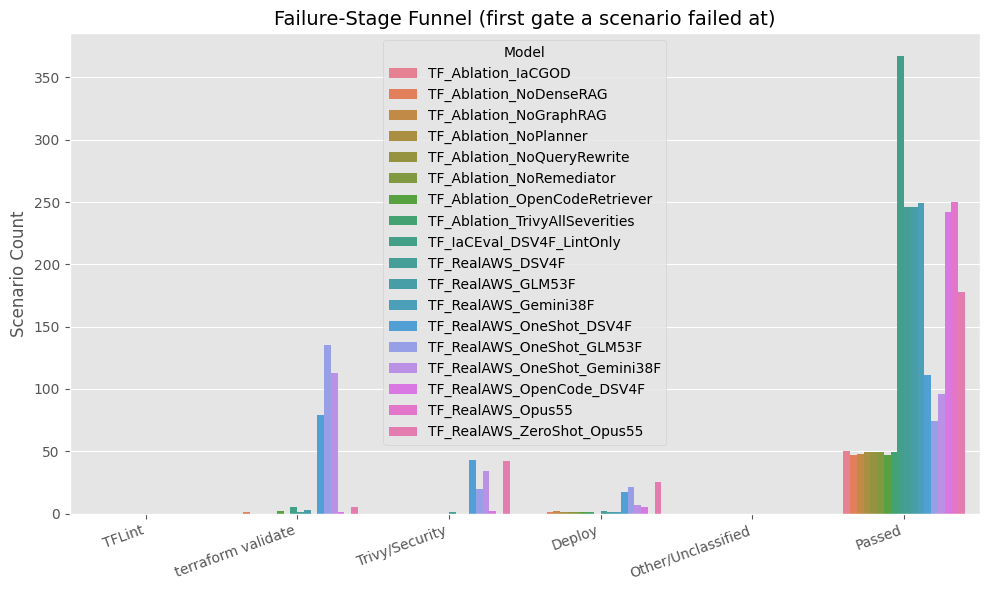

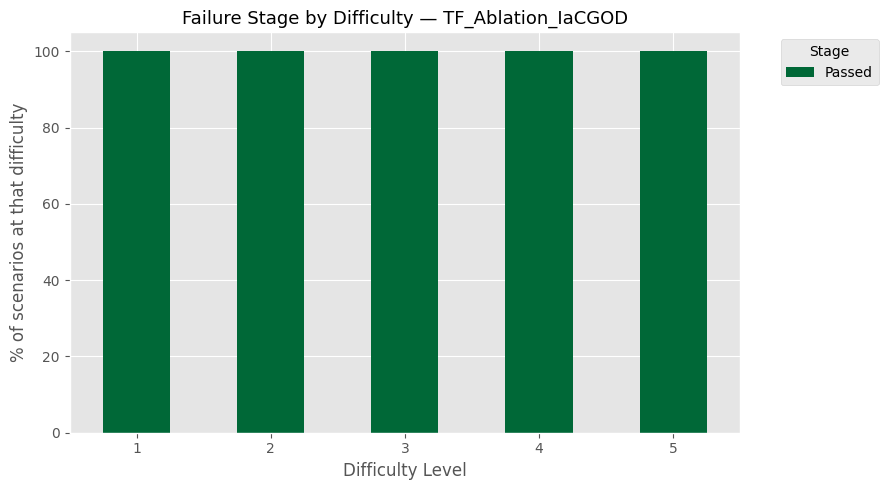

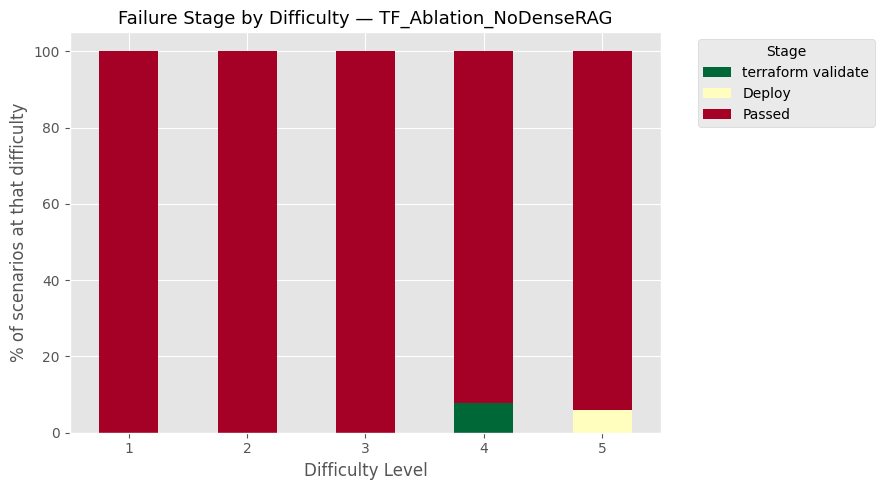

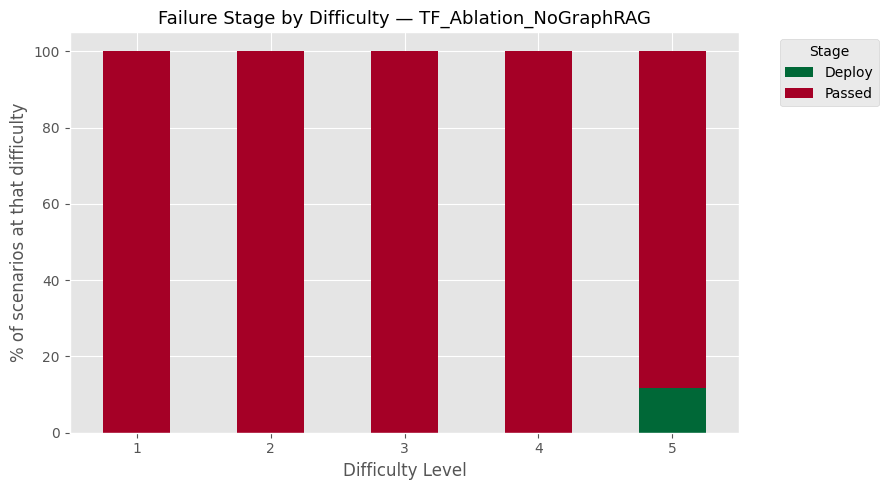

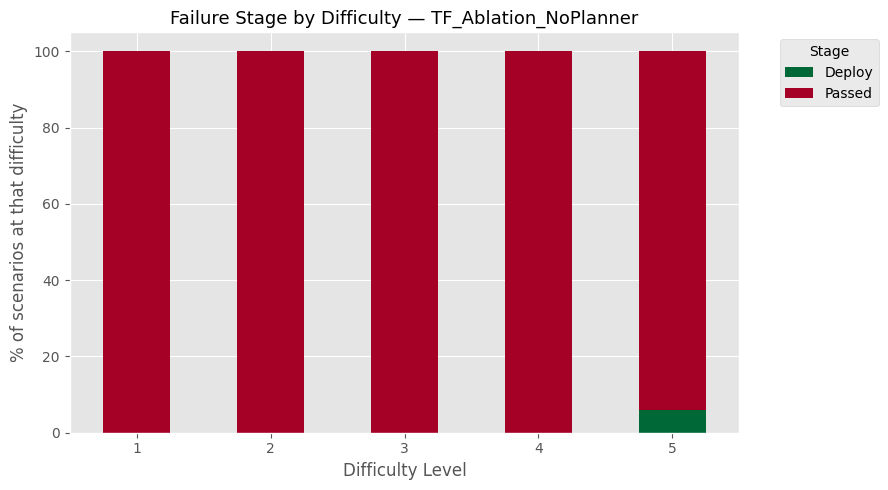

...

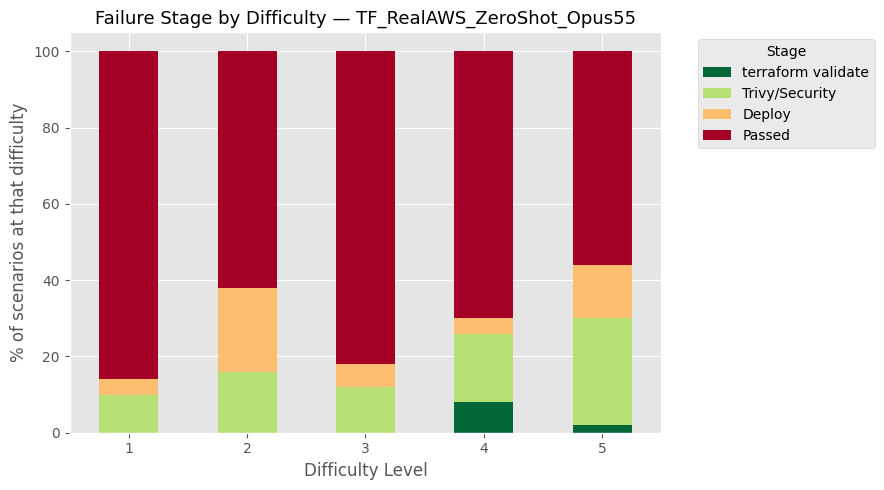

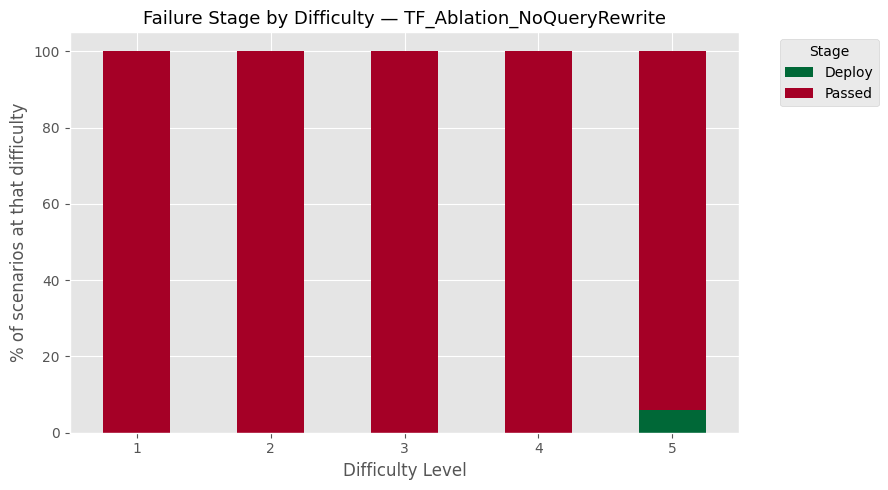

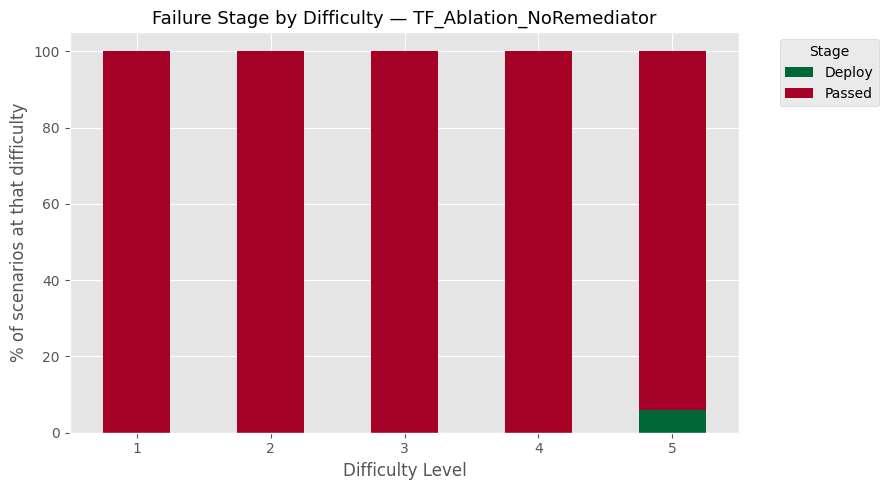

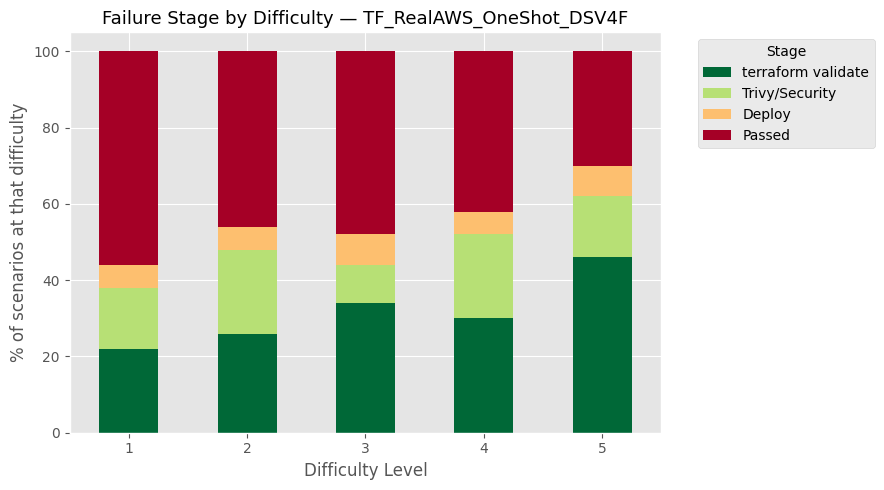

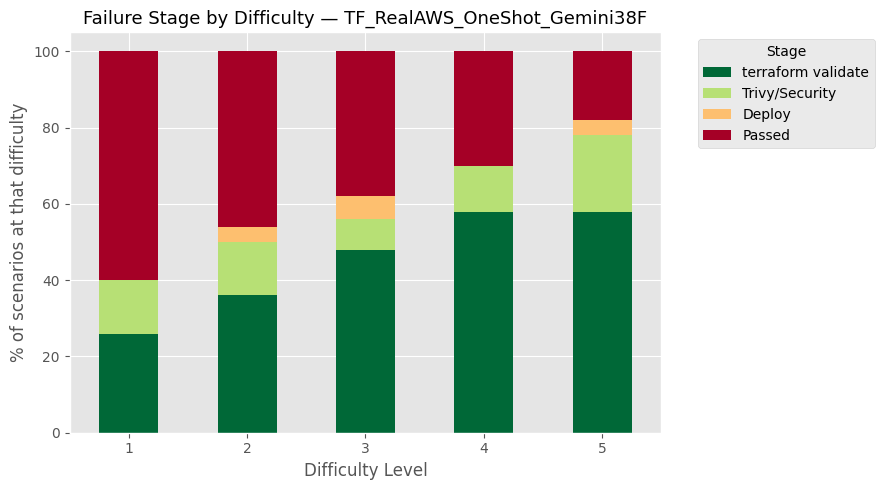

None

In [16]:
STAGE_CONFIG = [
    {"key": "tflint",              "label": "TFLint",             "all_col": "all_yaml_errors",     "latest_col": "latest_error_tflint",             "passed_col": "val_stage_tflint_passed"},
    {"key": "terraform-validate",  "label": "terraform validate", "all_col": "all_cfn_lint_errors", "latest_col": "latest_error_terraform-validate", "passed_col": "val_stage_terraform-validate_passed"},
    {"key": "trivy",               "label": "Trivy/Security",     "all_col": "all_security_errors", "latest_col": "latest_error_trivy",              "passed_col": "val_stage_trivy_passed"},
]

for _df in merged_dataframes.values():
    if "difficulty_level" not in _df.columns and "difficulty" in _df.columns:
        _df["difficulty_level"] = _df["difficulty"]

def compute_failure_stage(row: pd.Series) -> str:
    for stage in STAGE_CONFIG:
        col = stage["passed_col"]
        if col in row.index and row[col] is False:
            return stage["label"]
    if "deploy_passed" in row.index and row["deploy_passed"] is False:
        return "Deploy"
    if "final_validation_passed" in row.index and row["final_validation_passed"] is False:
        return "Other/Unclassified"
    return "Passed"

def _plot_failure_stage_funnel(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    funnel_rows = []
    for model_name, df in dfs.items():
        if "final_validation_passed" not in df.columns:
            continue
        df["failure_stage"] = df.apply(compute_failure_stage, axis=1)
        counts = df["failure_stage"].value_counts()
        for stage_label, cnt in counts.items():
            funnel_rows.append({"Model": model_name, "Stage": stage_label, "Count": cnt, "Pct": cnt / len(df) * 100})

    if funnel_rows:
        funnel_df = pd.DataFrame(funnel_rows)
        stage_order = [s["label"] for s in STAGE_CONFIG] + ["Deploy", "Other/Unclassified", "Passed"]
        funnel_df["Stage"] = pd.Categorical(funnel_df["Stage"], categories=stage_order, ordered=True)
        funnel_df = funnel_df.sort_values(["Model", "Stage"])

        print("📊 Failure-stage funnel (first gate that stopped each scenario):")
        with pd.option_context('display.max_rows', None):
            display(funnel_df.pivot(index="Stage", columns="Model", values="Count").fillna(0).astype(int))

        plt.figure(figsize=(10, 6))
        sns.barplot(data=funnel_df, x="Stage", y="Count", hue="Model", order=stage_order)
        plt.title("Failure-Stage Funnel (first gate a scenario failed at)", fontsize=14)
        plt.ylabel("Scenario Count")
        plt.xlabel("")
        plt.xticks(rotation=20, ha="right")
        plt.legend(title="Model")
        plt.tight_layout()
        plt.show()

        for model_name, df in dfs.items():
            if "difficulty_level" not in df.columns or "failure_stage" not in df.columns:
                continue
            cross = pd.crosstab(df["difficulty_level"], df["failure_stage"])
            cross = cross.reindex(columns=[s for s in stage_order if s in cross.columns])
            cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

            cross_pct.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="RdYlGn_r")
            plt.title(f"Failure Stage by Difficulty — {model_name}", fontsize=13)
            plt.ylabel("% of scenarios at that difficulty")
            plt.xlabel("Difficulty Level")
            plt.xticks(rotation=0)
            plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc="upper left")
            plt.tight_layout()
            plt.show()
    else:
        print("⚠️ No models with 'final_validation_passed' / stage columns found.")

_out_failure_stage_funnel = widgets.interactive_output(_plot_failure_stage_funnel, {'selected_models': model_selector})
display(_out_failure_stage_funnel)

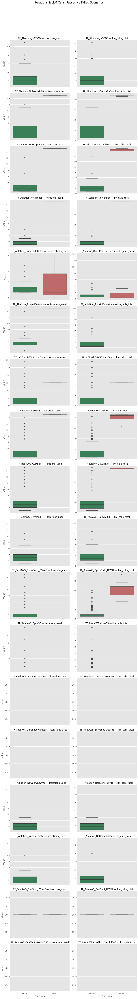

📊 Mean effort by outcome:


mean  median   max  count
Model                      Metric          Outcome                            
TF_Ablation_IaCGOD         iterations_used Passed    2.92     2.0  11.0     50
                           llm_calls_total Passed    7.50     5.0  31.0     50
TF_Ablation_NoDenseRAG     iterations_used Failed   15.00    15.0  15.0      2
                                           Passed    3.83     3.0  12.0     47
                           llm_calls_total Failed   43.50    43.5  44.0      2
...                                                   ...     ...   ...    ...
TF_RealAWS_Opus55          llm_calls_total Passed    3.12     2.0  35.0    250
TF_RealAWS_ZeroShot_Opus55 iterations_used Failed    1.00     1.0   1.0     72
                                           Passed    1.00     1.0   1.0    178
                           llm_calls_total Failed    1.00     1.0   1.0     72
                                           Passed    1.00     1.0   1.0    178

[68 rows x 4 columns]

  TF_Ablation_NoDenseRAG: 2/2 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  TF_Ablation_NoGraphRAG: 2/2 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  TF_Ablation_NoPlanner: 1/1 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  TF_Ablation_OpenCodeRetriever: 1/3 failed scenarios (33%) hit the observed max iteration count (8) before giving up -- the rest failed before exhausting their budget.
  TF_Ablation_TrivyAllSeverities: 1/1 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  TF_IaCEval_DSV4F_LintOnly: 0/5 failed scenarios (0%) hit the observed max iteration count (29) before giving up -- the rest failed before exhausting their budget.
  T

None

In [17]:
def _plot_effort_vs_outcome(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    effort_rows = []
    for model_name, df in dfs.items():
        if "final_validation_passed" not in df.columns or "iterations_used" not in df.columns:
            continue
        outcome = df["final_validation_passed"].map({True: "Passed", False: "Failed"})
        for col in ["iterations_used", "llm_calls_total"]:
            if col not in df.columns:
                continue
            tmp = pd.DataFrame({"Model": model_name, "Outcome": outcome, "Metric": col, "Value": df[col]})
            effort_rows.append(tmp)

    if effort_rows:
        effort_df = pd.concat(effort_rows, ignore_index=True).dropna(subset=["Value"])

        g = sns.catplot(
            data=effort_df, kind="box",
            x="Outcome", y="Value", hue="Outcome", col="Metric", row="Model",
            palette={"Passed": "seagreen", "Failed": "indianred"},
            height=4, aspect=1.3, sharey=False, legend=False,
        )
        g.set_titles("{row_name} — {col_name}")
        g.fig.suptitle("Iterations & LLM Calls: Passed vs Failed Scenarios", fontsize=15, y=1.03)
        plt.tight_layout()
        plt.show()

        print("📊 Mean effort by outcome:")
        summary = effort_df.groupby(["Model", "Metric", "Outcome"])["Value"].agg(["mean", "median", "max", "count"]).round(2)
        display(summary)

        for model_name, df in dfs.items():
            if "iterations_used" not in df.columns or "final_validation_passed" not in df.columns:
                continue
            max_iter = df["iterations_used"].max()
            exhausted = df[(df["final_validation_passed"] == False) & (df["iterations_used"] >= max_iter)]
            n_failed = (df["final_validation_passed"] == False).sum()
            if n_failed:
                print(f"  {model_name}: {len(exhausted)}/{n_failed} failed scenarios "
                      f"({len(exhausted)/n_failed:.0%}) hit the observed max iteration count ({max_iter:.0f}) "
                      f"before giving up -- the rest failed before exhausting their budget.")
    else:
        print("⚠️ No models with iteration/effort columns found.")

_out_effort_vs_outcome = widgets.interactive_output(_plot_effort_vs_outcome, {'selected_models': model_selector})
display(_out_effort_vs_outcome)

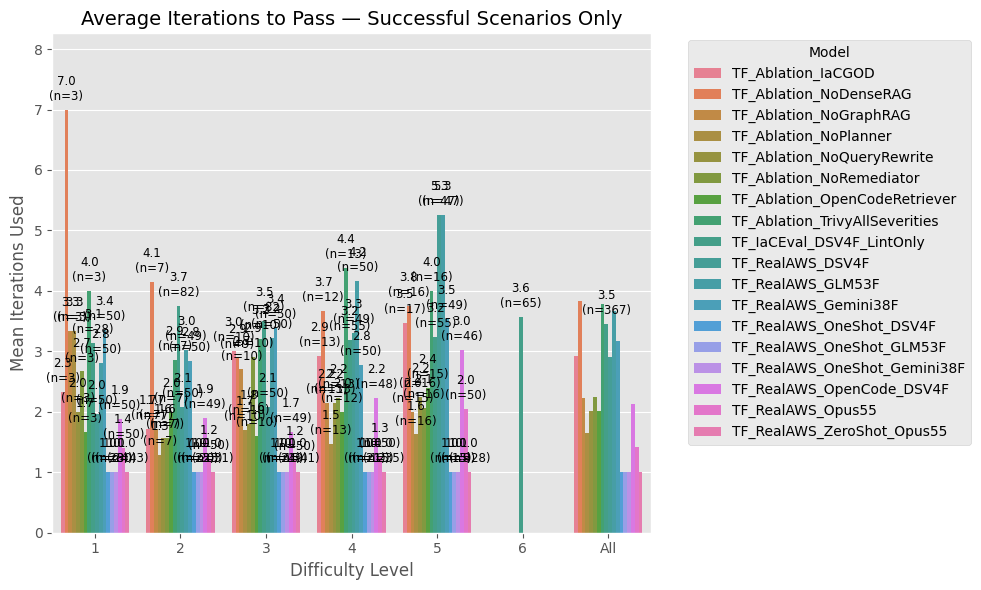

📊 Average iterations to pass, by difficulty (successful scenarios only):


,Model,Difficulty Level,N Passed,Mean Iterations,Median Iterations
0,TF_Ablation_IaCGOD,1,3,2.33,3.0
1,TF_Ablation_NoDenseRAG,1,3,7.00,8.0
2,TF_Ablation_NoGraphRAG,1,3,3.33,2.0
3,TF_Ablation_NoPlanner,1,3,3.33,2.0
4,TF_Ablation_NoQueryRewrite,1,3,2.00,2.0
...,...,...,...,...,...
104,TF_RealAWS_OneShot_GLM53F,All,74,1.00,1.0
105,TF_RealAWS_OneShot_Gemini38F,All,96,1.00,1.0
106,TF_RealAWS_OpenCode_DSV4F,All,242,2.13,1.0
107,TF_RealAWS_Opus55,All,250,1.42,1.0


None

In [18]:
def _plot_avg_iterations_to_pass(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    avg_iter_rows = []
    for model_name, df in dfs.items():
        if "final_validation_passed" not in df.columns or "iterations_used" not in df.columns:
            continue
        diff_col = "difficulty_level" if "difficulty_level" in df.columns else "difficulty"
        if diff_col not in df.columns:
            continue
        passed = df[df["final_validation_passed"] == True]
        grouped = passed.groupby(diff_col)["iterations_used"].agg(["mean", "median", "count"])
        for diff, row in grouped.iterrows():
            avg_iter_rows.append({
                "Model": model_name, "Difficulty Level": diff,
                "Mean Iterations": row["mean"], "Median Iterations": row["median"], "N Passed": int(row["count"]),
            })
        if len(passed):
            avg_iter_rows.append({
                "Model": model_name, "Difficulty Level": "All",
                "Mean Iterations": passed["iterations_used"].mean(),
                "Median Iterations": passed["iterations_used"].median(), "N Passed": len(passed),
            })

    if avg_iter_rows:
        avg_iter_df = pd.DataFrame(avg_iter_rows)
        order = sorted([d for d in avg_iter_df["Difficulty Level"].unique() if d != "All"]) + ["All"]
        avg_iter_df["Difficulty Level"] = pd.Categorical(avg_iter_df["Difficulty Level"], categories=order, ordered=True)
        avg_iter_df = avg_iter_df.sort_values(["Difficulty Level", "Model"])

        plt.figure(figsize=(10, 6))
        ax = sns.barplot(data=avg_iter_df, x="Difficulty Level", y="Mean Iterations", hue="Model", order=order)
        plt.title("Average Iterations to Pass — Successful Scenarios Only", fontsize=14)
        plt.ylim(0, avg_iter_df["Mean Iterations"].max() * 1.18)
        plt.ylabel("Mean Iterations Used")
        plt.xlabel("Difficulty Level")
        plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")

        for i, container in enumerate(ax.containers):
            model_name = ax.get_legend().get_texts()[i].get_text()
            for j, p in enumerate(container):
                height = p.get_height()
                if pd.isna(height) or (height == 0 and p.get_y() == 0):
                    continue
                diff_level = ax.get_xticklabels()[j].get_text()
                row = avg_iter_df[(avg_iter_df["Model"] == model_name) & (avg_iter_df["Difficulty Level"].astype(str) == diff_level)]
                if not row.empty:
                    n = row["N Passed"].values[0]
                    ax.annotate(f"{height:.1f}\n(n={n})", (p.get_x() + p.get_width() / 2., height),
                                ha="center", va="bottom", xytext=(0, 5), textcoords="offset points", fontsize=8.5)

        plt.tight_layout()
        plt.show()

        print("📊 Average iterations to pass, by difficulty (successful scenarios only):")
        display(avg_iter_df[["Model", "Difficulty Level", "N Passed", "Mean Iterations", "Median Iterations"]]
                .round(2).reset_index(drop=True))
    else:
        print("⚠️ No models with iterations_used/final_validation_passed/difficulty columns found.")

_out_avg_iterations_to_pass = widgets.interactive_output(_plot_avg_iterations_to_pass, {'selected_models': model_selector})
display(_out_avg_iterations_to_pass)

📊 Token & duration totals per model:


,total_tokens,mean_tokens,total_input_tokens,total_output_tokens,mean_duration_s,total_est_cost_usd
Model,,,,,,
TF_Ablation_IaCGOD,5384587.0,107691.74,0.0,0.0,603.90,0.0
TF_Ablation_NoDenseRAG,13989324.0,285496.41,0.0,0.0,357.20,0.0
TF_Ablation_NoGraphRAG,8403411.0,168068.22,0.0,0.0,1013.26,0.0
TF_Ablation_NoPlanner,3798947.0,75978.94,0.0,0.0,400.14,0.0
TF_Ablation_NoQueryRewrite,4980679.0,99613.58,0.0,0.0,450.11,0.0
TF_Ablation_NoRemediator,3881320.0,77626.40,0.0,0.0,457.31,0.0
TF_Ablation_OpenCodeRetriever,3676159.0,73523.18,3394753.0,281406.0,529.34,0.0
TF_Ablation_TrivyAllSeverities,10167090.0,203341.80,0.0,0.0,343.74,0.0
TF_IaCEval_DSV4F_LintOnly,38310078.0,102984.08,0.0,0.0,430.40,0.0


  ℹ️ INPUT_COST_PER_MTOK / OUTPUT_COST_PER_MTOK are both 0 -- set them above to see $ estimates instead of just token counts.


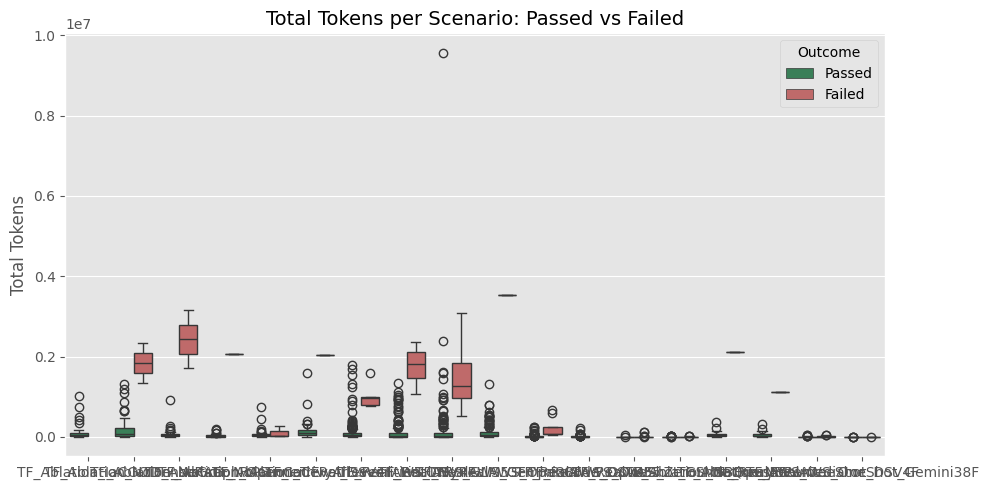

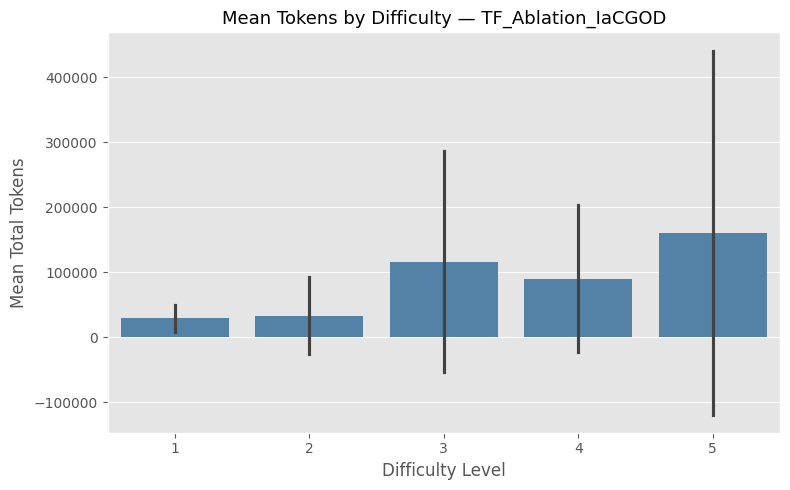

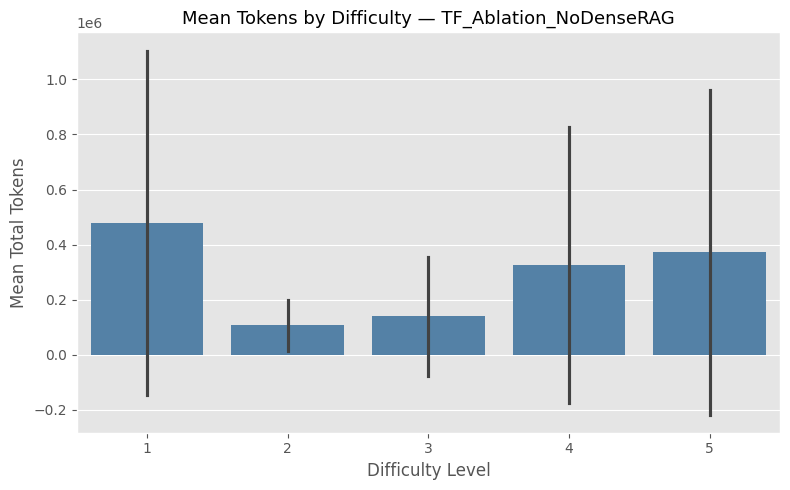

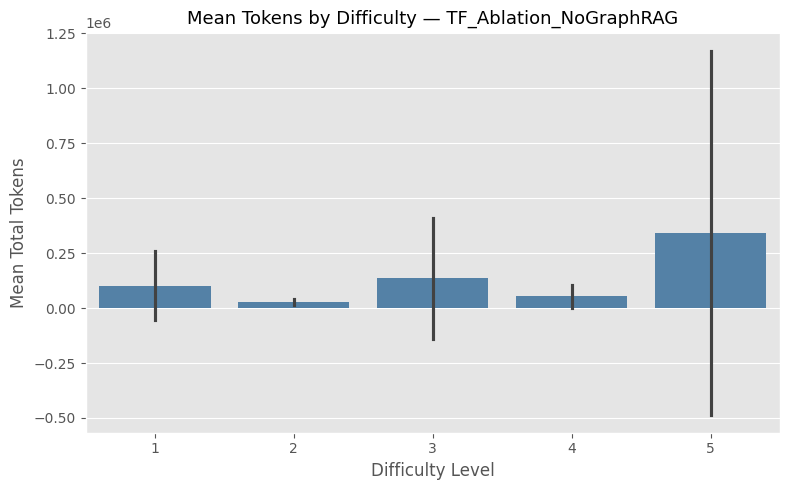

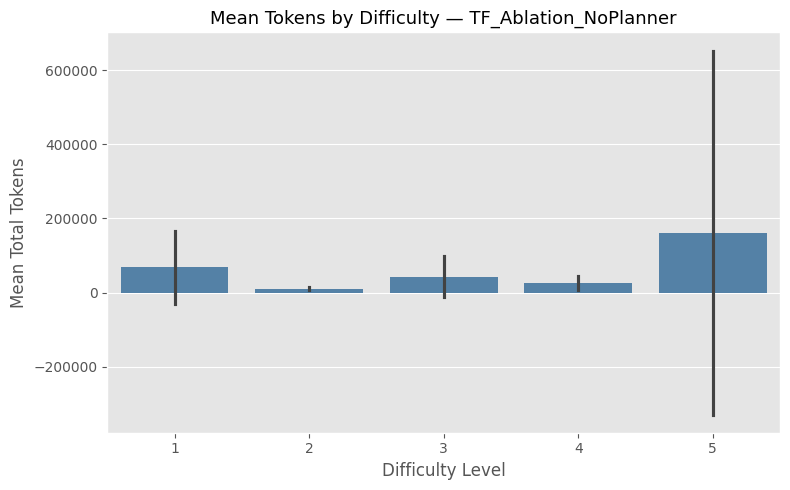

...

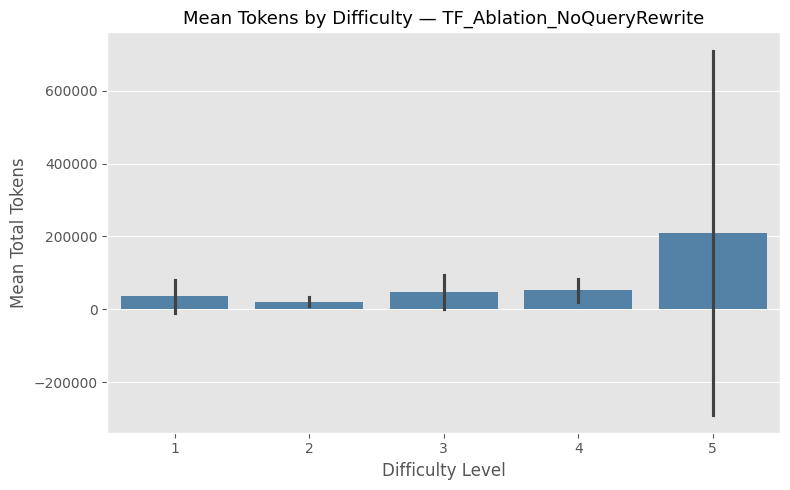

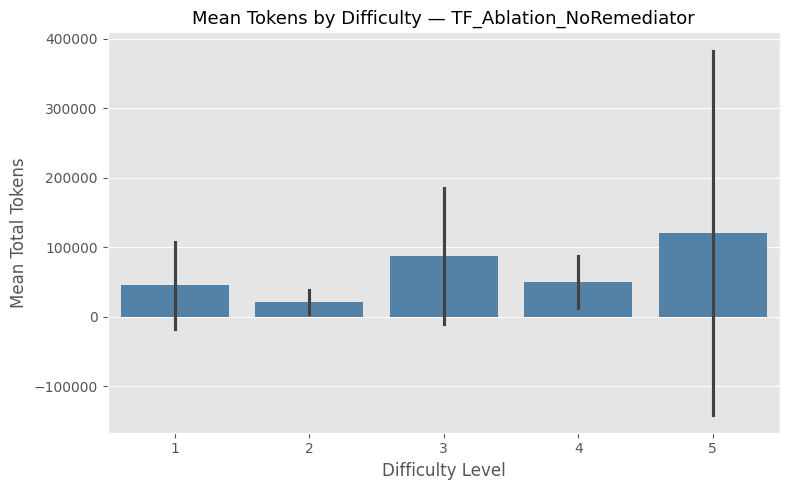

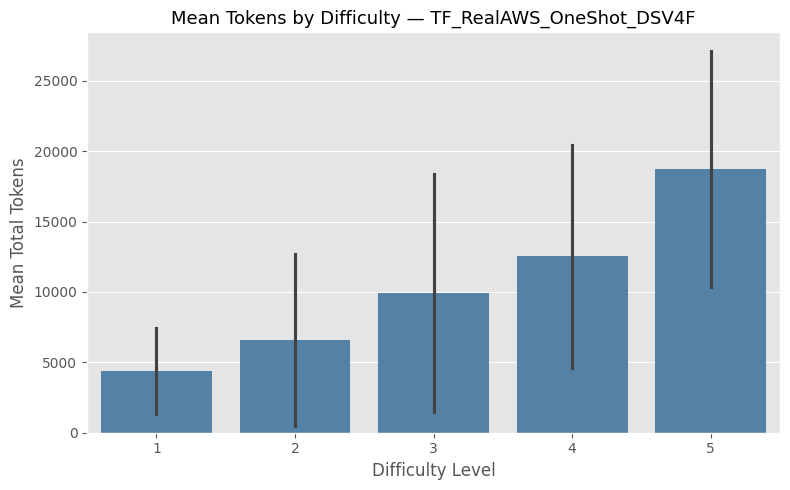

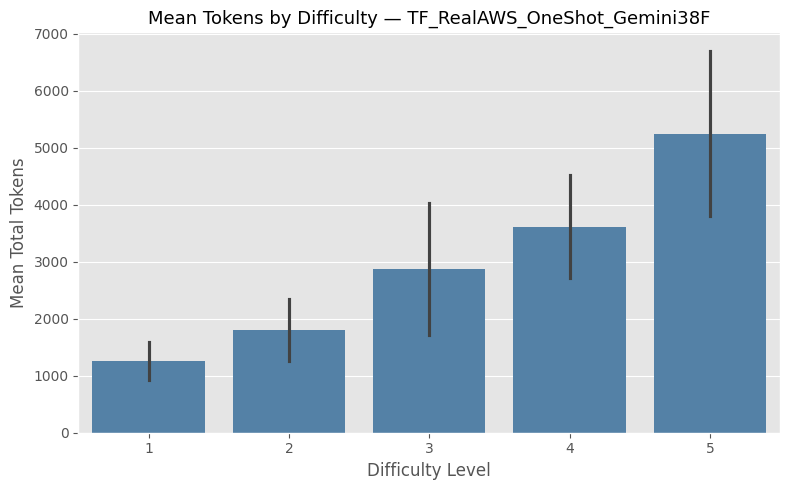

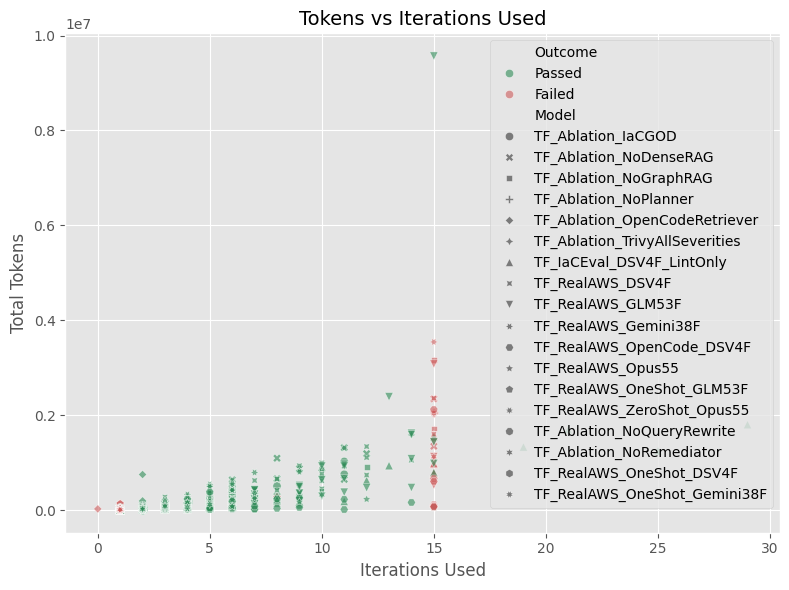

None

In [19]:
INPUT_COST_PER_MTOK = 0.0
OUTPUT_COST_PER_MTOK = 0.0

def _plot_token_cost_duration(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    token_cols_present = {c for c in ["token_input_tokens", "token_output_tokens", "token_all_tokens"]
                           if any(c in df.columns for df in dfs.values())}

    if token_cols_present:
        cost_rows = []
        for model_name, df in dfs.items():
            if "token_all_tokens" not in df.columns:
                continue
            d = df.copy()
            d["est_cost_usd"] = (
                d.get("token_input_tokens", 0).fillna(0) / 1_000_000 * INPUT_COST_PER_MTOK
                + d.get("token_output_tokens", 0).fillna(0) / 1_000_000 * OUTPUT_COST_PER_MTOK
            )
            d["Model"] = model_name
            d["Outcome"] = d["final_validation_passed"].map({True: "Passed", False: "Failed"}) \
                if "final_validation_passed" in d.columns else "Unknown"
            cost_rows.append(d[["Model", "Outcome", "token_input_tokens", "token_output_tokens",
                                 "token_all_tokens", "iterations_used", "duration_seconds", "est_cost_usd"]])

        cost_df = pd.concat(cost_rows, ignore_index=True)

        print("📊 Token & duration totals per model:")
        totals = cost_df.groupby("Model").agg(
            total_tokens=("token_all_tokens", "sum"),
            mean_tokens=("token_all_tokens", "mean"),
            total_input_tokens=("token_input_tokens", "sum"),
            total_output_tokens=("token_output_tokens", "sum"),
            mean_duration_s=("duration_seconds", "mean"),
            total_est_cost_usd=("est_cost_usd", "sum"),
        ).round(2)
        display(totals)

        if (INPUT_COST_PER_MTOK == 0) and (OUTPUT_COST_PER_MTOK == 0):
            print("  ℹ️ INPUT_COST_PER_MTOK / OUTPUT_COST_PER_MTOK are both 0 -- "
                  "set them above to see $ estimates instead of just token counts.")

        plt.figure(figsize=(10, 5))
        sns.boxplot(data=cost_df, x="Model", y="token_all_tokens", hue="Outcome",
                    palette={"Passed": "seagreen", "Failed": "indianred", "Unknown": "gray"})
        plt.title("Total Tokens per Scenario: Passed vs Failed", fontsize=14)
        plt.ylabel("Total Tokens")
        plt.xlabel("")
        plt.tight_layout()
        plt.show()

        for model_name, df in dfs.items():
            if "difficulty_level" not in df.columns or "token_all_tokens" not in df.columns:
                continue
            plt.figure(figsize=(8, 5))
            sns.barplot(data=df, x="difficulty_level", y="token_all_tokens", errorbar="sd", color="steelblue")
            plt.title(f"Mean Tokens by Difficulty — {model_name}", fontsize=13)
            plt.xlabel("Difficulty Level")
            plt.ylabel("Mean Total Tokens")
            plt.tight_layout()
            plt.show()

        if cost_df["est_cost_usd"].sum() > 0:
            eff = cost_df.groupby(["Model", "Outcome"])["est_cost_usd"].agg(["sum", "mean", "count"]).round(4)
            print("\n📊 Cost efficiency (est. $ spent, passed vs failed):")
            display(eff)

        plt.figure(figsize=(8, 6))
        sns.scatterplot(data=cost_df, x="iterations_used", y="token_all_tokens", hue="Outcome",
                         style="Model", alpha=0.6,
                         palette={"Passed": "seagreen", "Failed": "indianred", "Unknown": "gray"})
        plt.title("Tokens vs Iterations Used", fontsize=14)
        plt.xlabel("Iterations Used")
        plt.ylabel("Total Tokens")
        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ No token columns found in any model's dataframe.")

_out_token_cost_duration = widgets.interactive_output(_plot_token_cost_duration, {'selected_models': model_selector})
display(_out_token_cost_duration)

## Common Failures / Failure Patterns

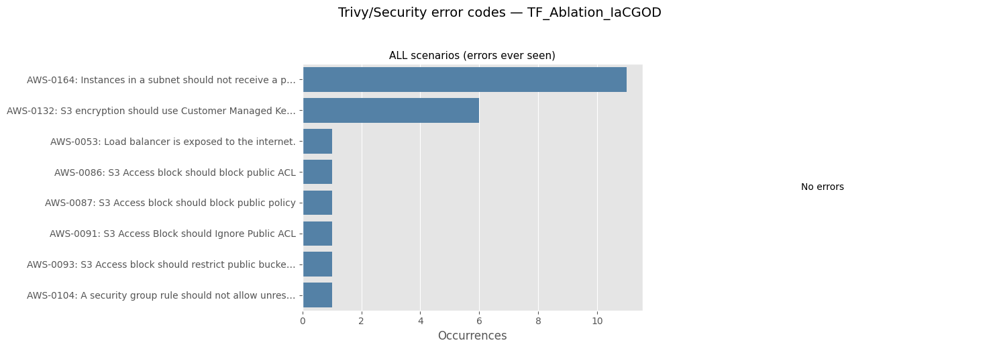

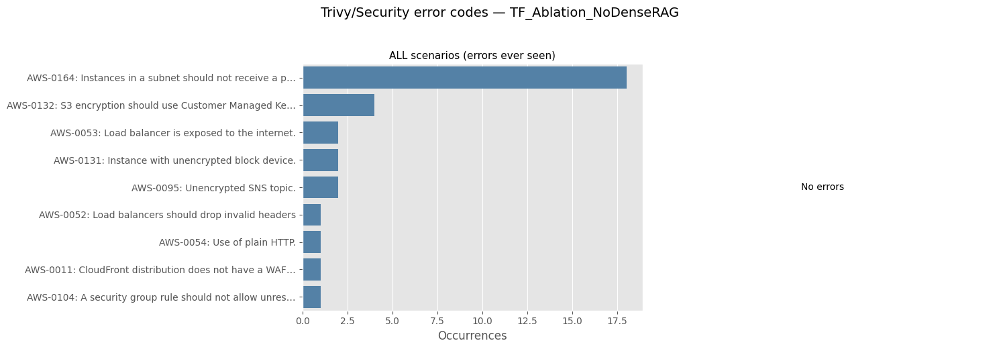

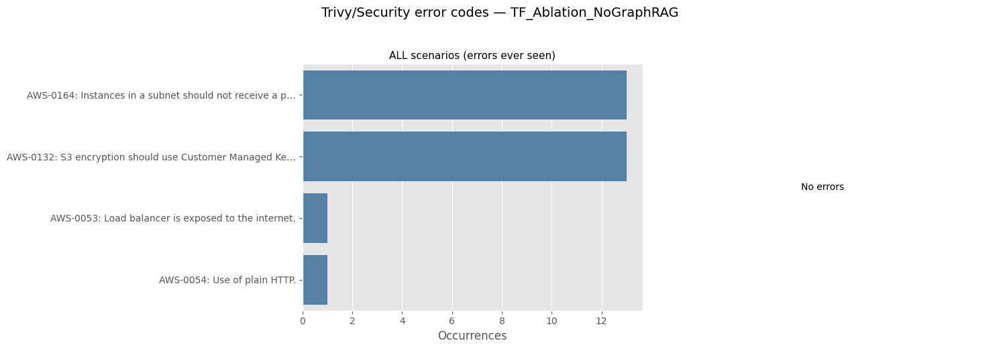

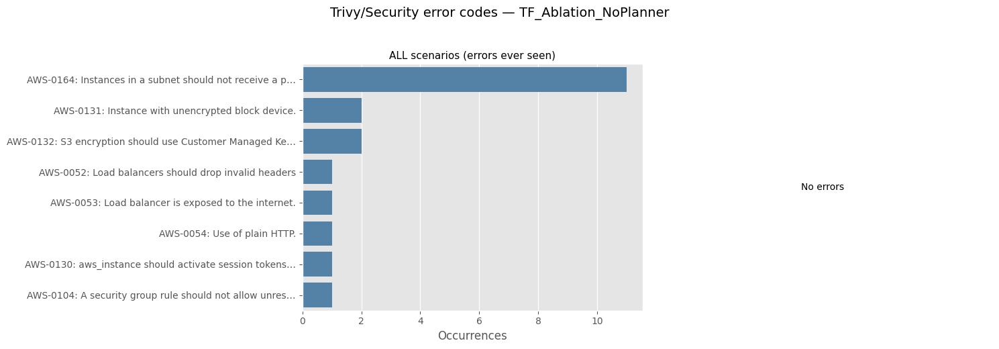

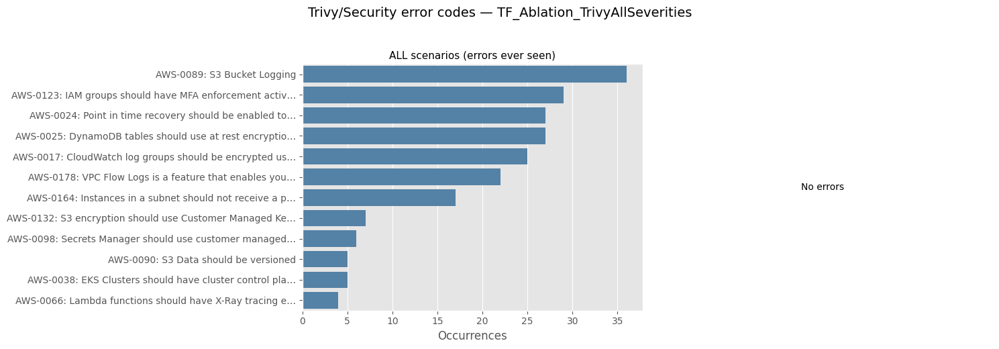

...

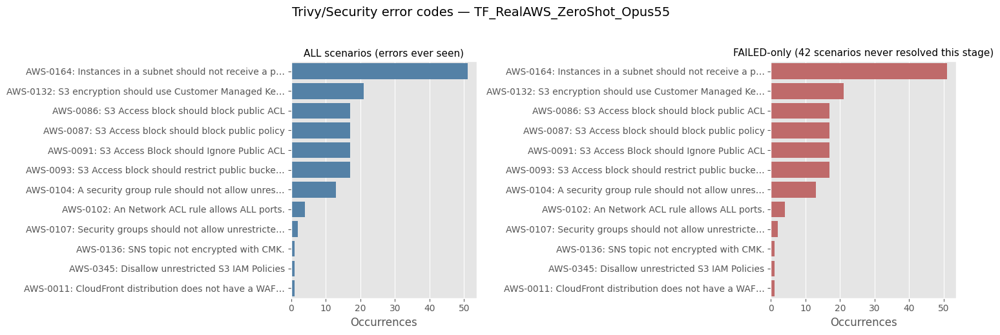

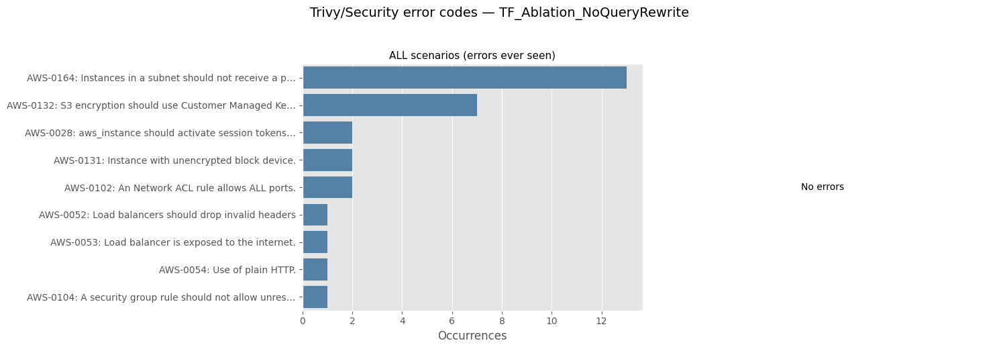

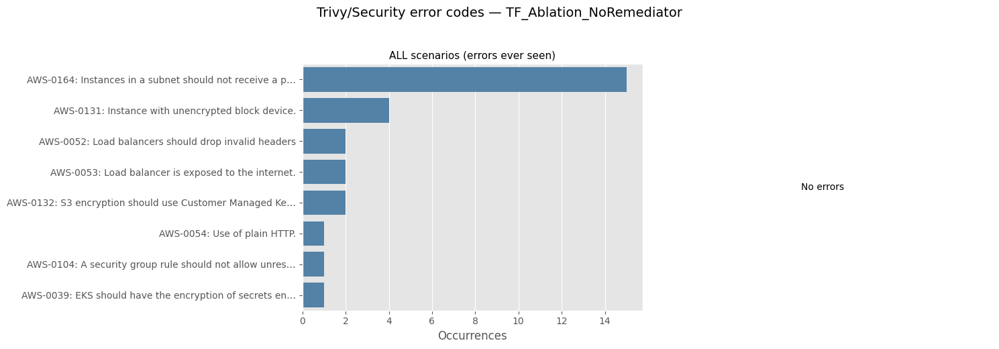

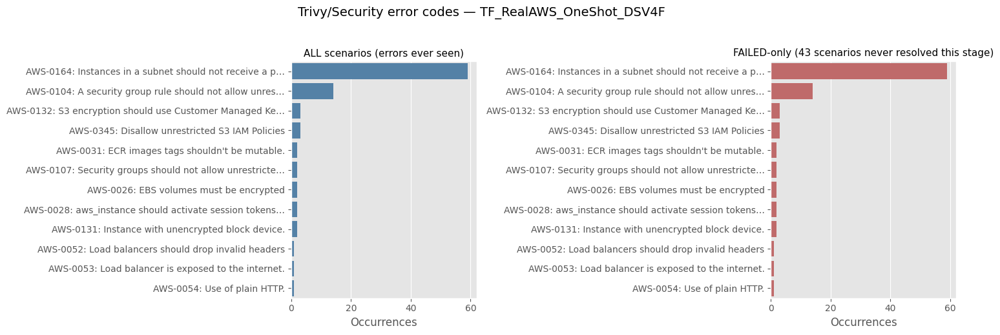

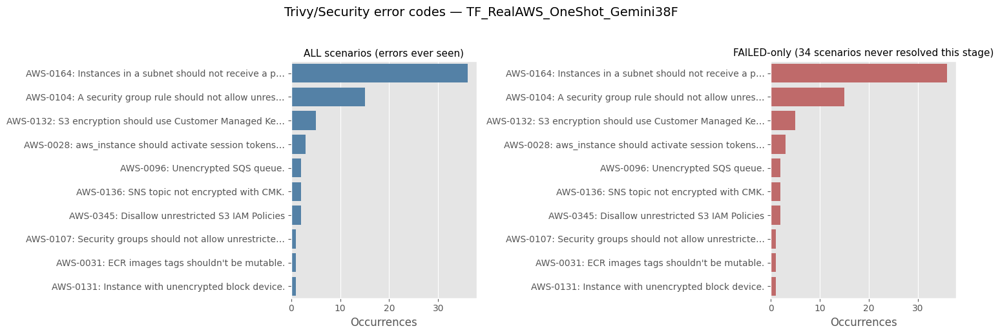

None

In [20]:
import re
from collections import defaultdict

CODE_RE = re.compile(r"\[([A-Za-z0-9_.\-]{1,20})\]")
GOOD_CODE_RE = re.compile(r"^(?:[EWI]\d{3,4}|AWS-\d{3,4}|[a-z][a-z_-]{2,19}|None)$")
_LINE_PREFIX_RE = re.compile(r"^\s*line\s+\d+(?:\s*,\s*column\s+\d+)?\s*:?\s*", re.I)
_RESOURCE_ONLY_RE = re.compile(r"^\s*Resource:\s*\S+\s*$", re.I)
_LINE_ONLY_RE = re.compile(r"^\s*line\s+\d+\s*$", re.I)
_SEVERITY_RE = re.compile(r"^\s*(CRITICAL|HIGH|MEDIUM|LOW)\s*:\s*", re.I)

CODE_MESSAGES = defaultdict(Counter)

def extract_error_entries(text) -> list:
    if not isinstance(text, str) or not text.strip():
        return []
    matches = list(CODE_RE.finditer(text))
    entries = []
    for i, m in enumerate(matches):
        code = m.group(1)
        if not GOOD_CODE_RE.match(code):
            continue
        start = m.end()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        segs = [s.strip() for s in text[start:end].split("|") if s.strip()]
        msg = ""
        for seg in segs:
            if _LINE_ONLY_RE.match(seg) or _RESOURCE_ONLY_RE.match(seg):
                continue
            seg = _SEVERITY_RE.sub("", _LINE_PREFIX_RE.sub("", seg)).strip()
            if " — " in seg:
                seg = seg.split(" — ", 1)[0].strip()
            if seg:
                msg = seg
                break
        entries.append((code, msg))
    return entries

def extract_error_codes(text) -> list:
    return [c for c, _ in extract_error_entries(text)]

def record_messages(entries) -> None:
    for code, msg in entries:
        if msg:
            CODE_MESSAGES[code][msg] += 1

def truncate_msg(msg: str, width: int = 45) -> str:
    msg = re.sub(r"\s+", " ", msg).strip()
    return msg if len(msg) <= width else msg[: width - 1].rstrip() + "…"

def describe_code(code: str, width: int = 45) -> str:
    msgs = CODE_MESSAGES.get(code)
    if not msgs:
        return code
    best_msg, _ = msgs.most_common(1)[0]
    return f"{code}: {truncate_msg(best_msg, width)}"

def top_codes_from_column(df: pd.DataFrame, col: str, mask: pd.Series = None) -> Counter:
    counter = Counter()
    series = df[col] if mask is None else df.loc[mask, col]
    for txt in series.dropna():
        entries = extract_error_entries(txt)
        counter.update(c for c, _ in entries)
        record_messages(entries)
    return counter

def _plot_common_failure_patterns(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    for stage in STAGE_CONFIG:
        for model_name, df in dfs.items():
            if stage["all_col"] not in df.columns or stage["passed_col"] not in df.columns:
                continue

            all_counter = top_codes_from_column(df, stage["all_col"])
            failed_mask = df[stage["passed_col"]] == False
            failed_counter = top_codes_from_column(df, stage["latest_col"], mask=failed_mask)

            if not all_counter and not failed_counter:
                continue

            fig, axes = plt.subplots(1, 2, figsize=(15, 5))
            for ax, counter, title, color in [
                (axes[0], all_counter, f"ALL scenarios (errors ever seen)", "steelblue"),
                (axes[1], failed_counter, f"FAILED-only ({int(failed_mask.sum())} scenarios never resolved this stage)", "indianred"),
            ]:
                top = pd.DataFrame(counter.most_common(12), columns=["Code", "Count"])
                if top.empty:
                    ax.text(0.5, 0.5, "No errors", ha="center", va="center")
                    ax.set_axis_off()
                    continue
                top["Label"] = top["Code"].apply(describe_code)
                sns.barplot(data=top, y="Label", x="Count", color=color, ax=ax)
                ax.set_title(title, fontsize=11)
                ax.set_xlabel("Occurrences")
                ax.set_ylabel("")
            fig.suptitle(f"{stage['label']} error codes — {model_name}", fontsize=14, y=1.03)
            plt.tight_layout()
            plt.show()

_out_common_failure_patterns = widgets.interactive_output(_plot_common_failure_patterns, {'selected_models': model_selector})
display(_out_common_failure_patterns)

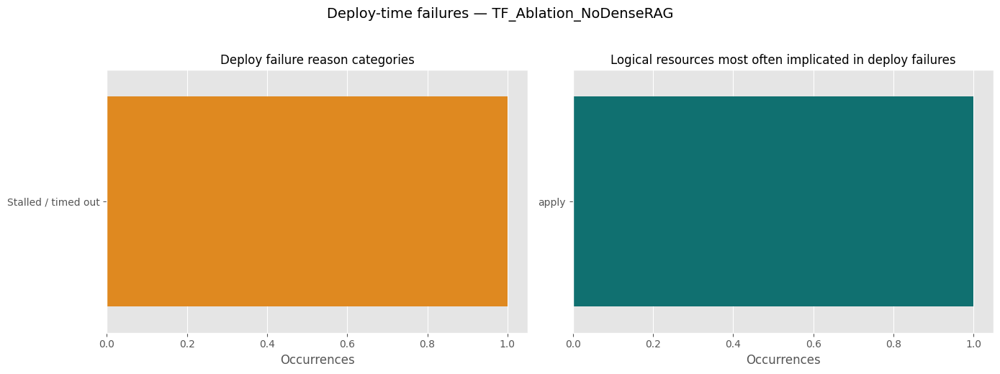

  TF_Ablation_NoDenseRAG: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


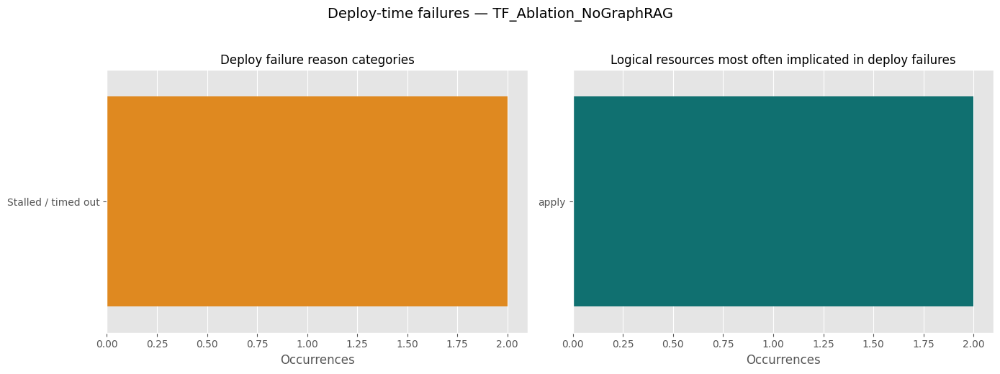

  TF_Ablation_NoGraphRAG: 2 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


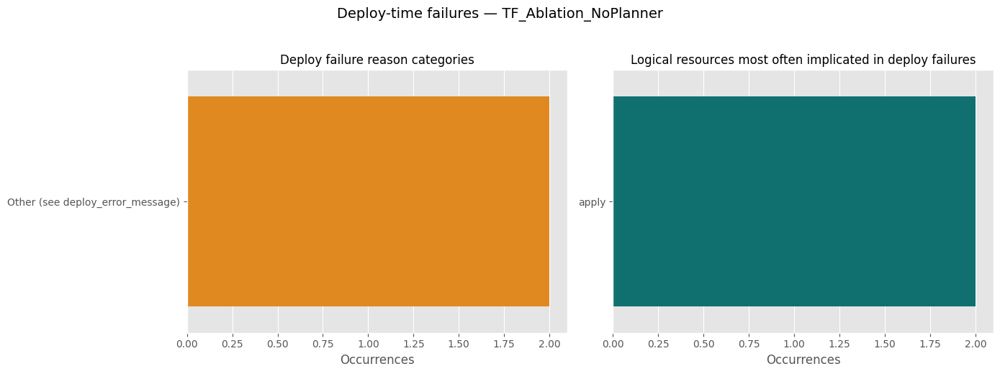

  TF_Ablation_NoPlanner: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


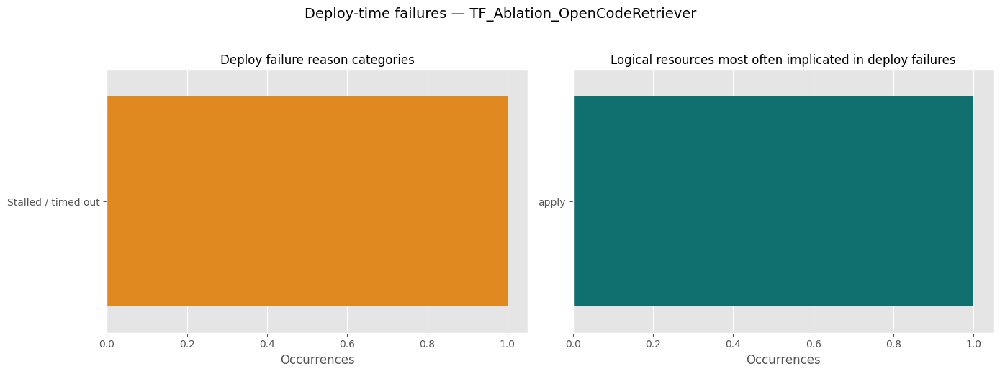

  TF_Ablation_OpenCodeRetriever: 3 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


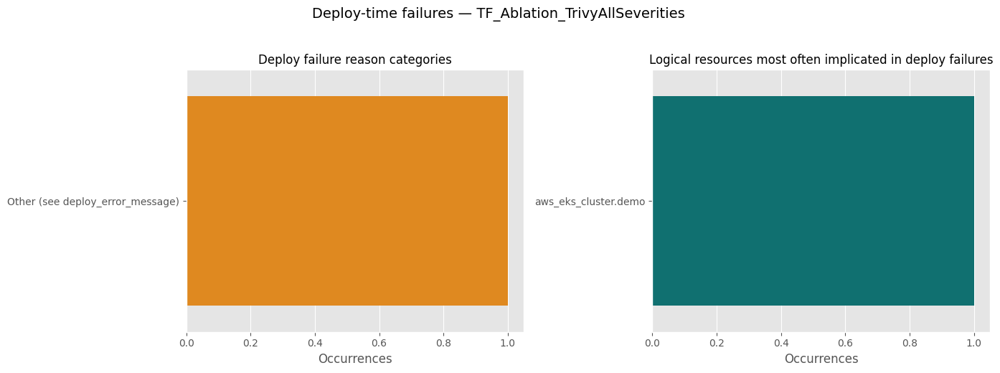

  TF_Ablation_TrivyAllSeverities: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


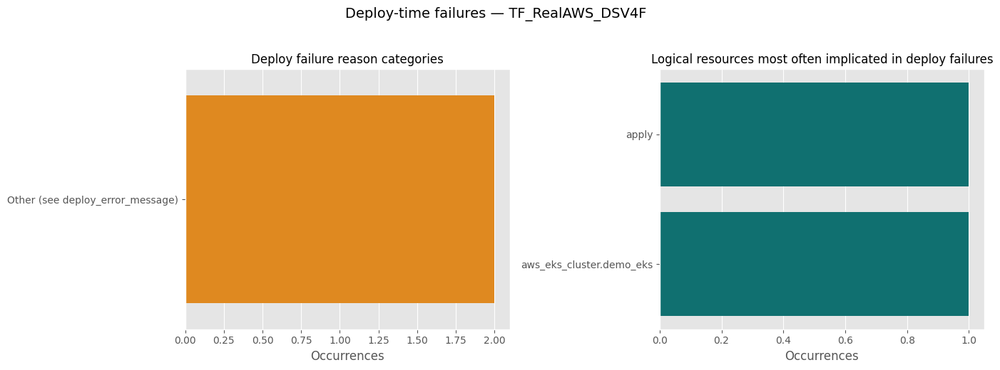

  TF_RealAWS_DSV4F: 2 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


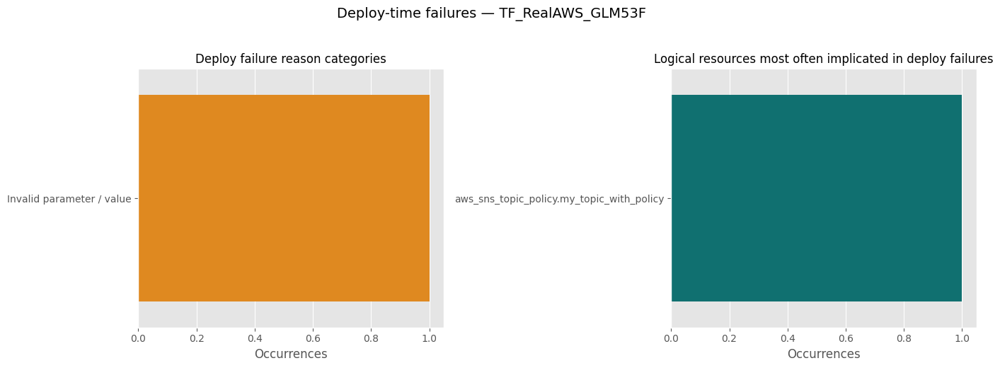

  TF_RealAWS_GLM53F: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


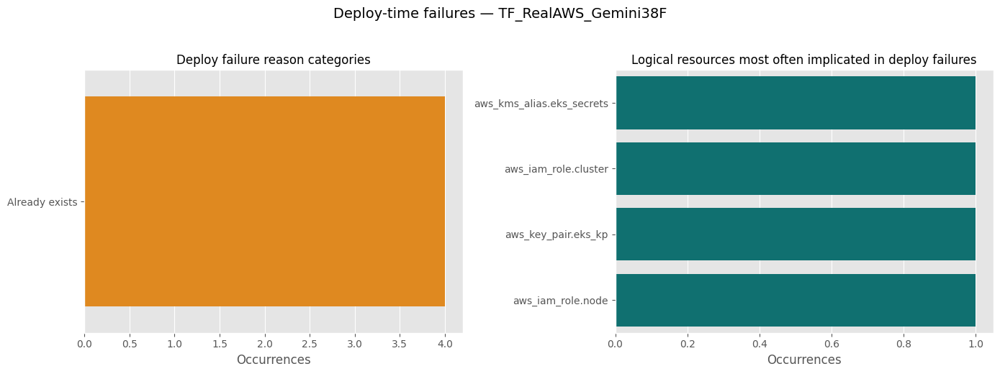

  TF_RealAWS_Gemini38F: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


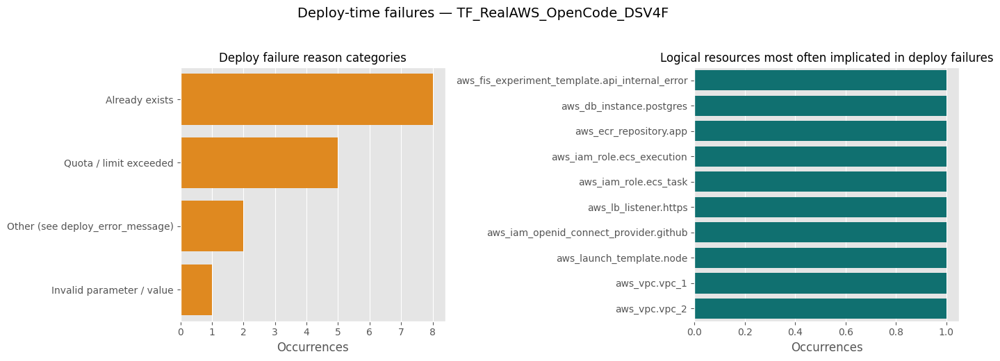

  TF_RealAWS_OpenCode_DSV4F: 8 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


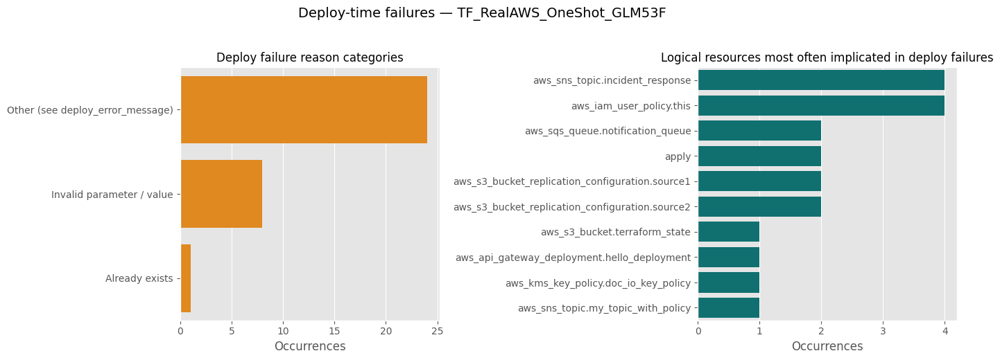

  TF_RealAWS_OneShot_GLM53F: 21 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


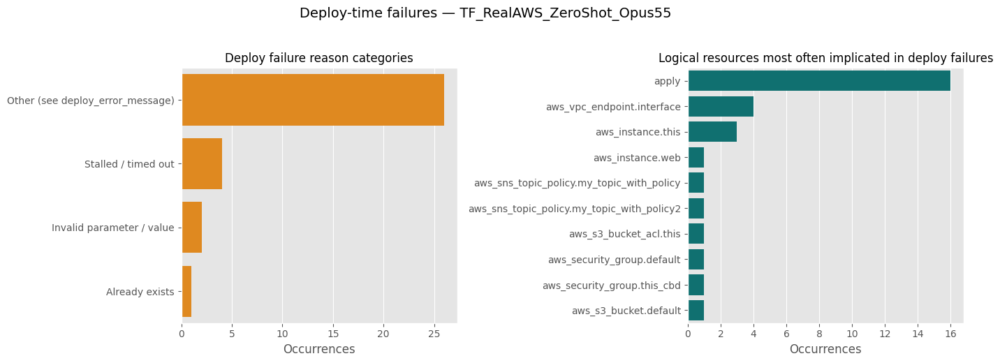

  TF_RealAWS_ZeroShot_Opus55: 25 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


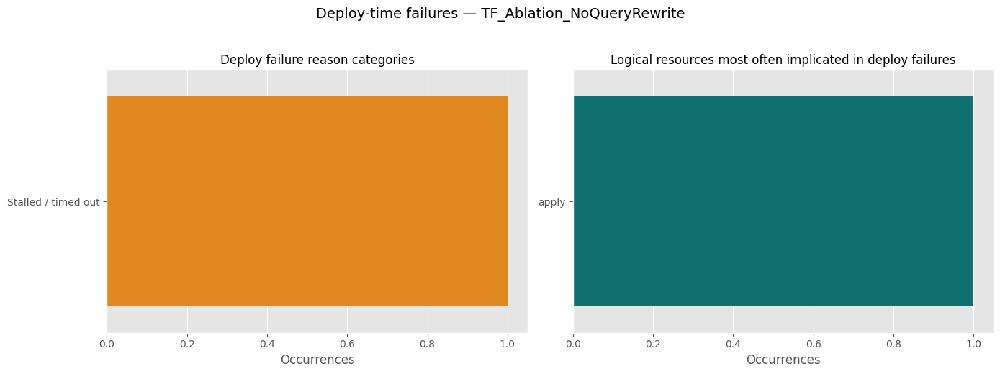

  TF_Ablation_NoQueryRewrite: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


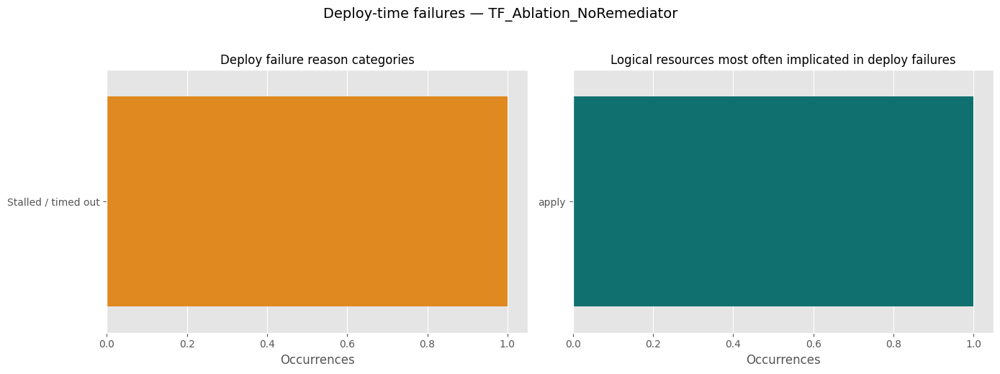

  TF_Ablation_NoRemediator: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


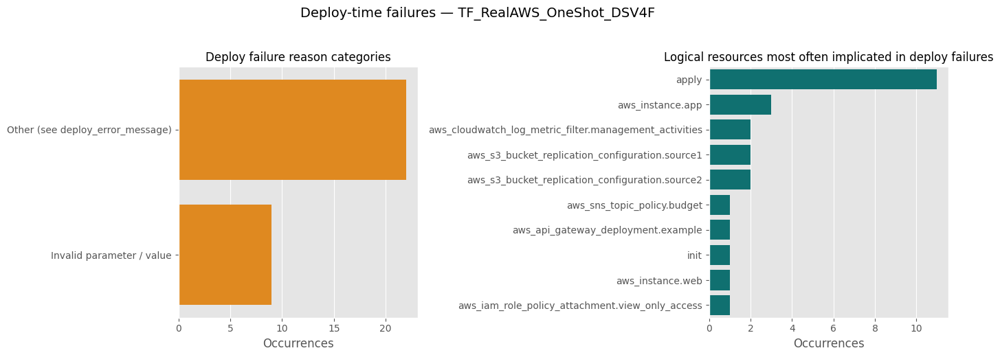

  TF_RealAWS_OneShot_DSV4F: 17 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


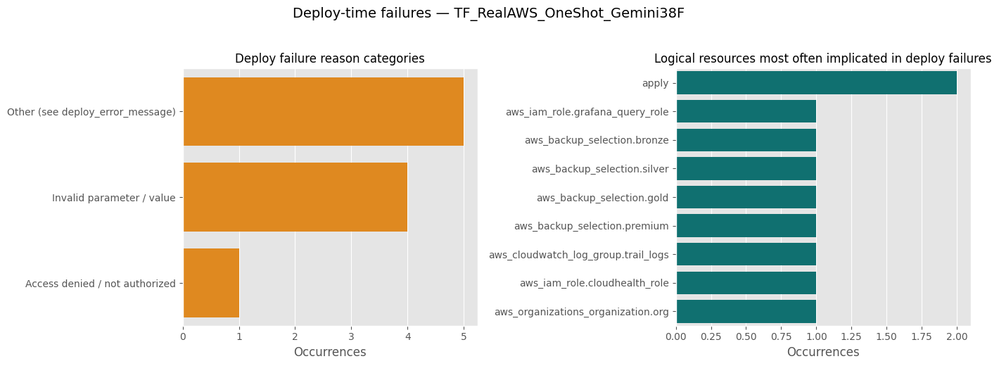

  TF_RealAWS_OneShot_Gemini38F: 7 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


None

In [21]:
import json as _json

DEPLOY_SIGNATURES = [
    ("Resource creation cancelled (rollback)", re.compile(r"creation cancelled", re.I)),
    ("Stalled / timed out", re.compile(r"stalled|timed?\s*out|>\s*\d+s\b", re.I)),
    ("Already exists", re.compile(r"already\s*exists", re.I)),
    ("Access denied / not authorized", re.compile(r"access\s*denied|not\s*authorized|forbidden", re.I)),
    ("Invalid parameter / value", re.compile(r"invalid\s*(parameter|value|request|instanceid|json)", re.I)),
    ("Quota / limit exceeded", re.compile(r"limit\s*exceeded|quota", re.I)),
    ("Validation failed (generic, needs DescribeEvents)", re.compile(r"validation\s*failed", re.I)),
]
STACK_NAME_RE = re.compile(r"^iac-god-eval-[0-9a-f]{6,}$")

def parse_deploy_failed_resources(cell):
    if not isinstance(cell, str) or not cell.strip():
        return []
    try:
        items = _json.loads(cell)
    except (ValueError, TypeError):
        return []
    out = []
    for it in items:
        if isinstance(it, dict):
            out.append((it.get("logical_name"), it.get("status_reason")))
    return out

def classify_deploy_reason(text) -> str:
    if not isinstance(text, str):
        return "Unknown"
    for label, pat in DEPLOY_SIGNATURES:
        if pat.search(text):
            return label
    return "Other (see deploy_error_message)"

def _plot_deploy_time_failure_reasons(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        if "deploy_failed_resources" not in df.columns:
            continue

        reason_counter = Counter()
        resource_counter = Counter()
        for cell in df["deploy_failed_resources"].dropna():
            for name, reason in parse_deploy_failed_resources(cell):
                reason_counter[classify_deploy_reason(reason)] += 1
                if name and not STACK_NAME_RE.match(name):
                    resource_counter[name] += 1

        if not reason_counter:
            continue

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        top_reasons = pd.DataFrame(reason_counter.most_common(10), columns=["Reason", "Count"])
        sns.barplot(data=top_reasons, y="Reason", x="Count", color="darkorange", ax=axes[0])
        axes[0].set_title("Deploy failure reason categories", fontsize=12)
        axes[0].set_xlabel("Occurrences")
        axes[0].set_ylabel("")

        top_res = pd.DataFrame(resource_counter.most_common(10), columns=["Logical Resource", "Count"])
        if not top_res.empty:
            sns.barplot(data=top_res, y="Logical Resource", x="Count", color="teal", ax=axes[1])
            axes[1].set_title("Logical resources most often implicated in deploy failures", fontsize=12)
            axes[1].set_xlabel("Occurrences")
            axes[1].set_ylabel("")
        else:
            axes[1].text(0.5, 0.5, "No per-resource detail\n(stack-level failure only)", ha="center", va="center")
            axes[1].set_axis_off()

        fig.suptitle(f"Deploy-time failures — {model_name}", fontsize=14, y=1.03)
        plt.tight_layout()
        plt.show()

        n_deploy_fail = (df["deploy_passed"] == False).sum() if "deploy_passed" in df.columns else None
        if n_deploy_fail:
            print(f"  {model_name}: {n_deploy_fail} scenario(s) failed to deploy; "
                  f"{reason_counter.get('Validation failed (generic, needs DescribeEvents)', 0)} of the reported "
                  f"reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS "
                  f"console/CLI to see the real underlying error.")

_out_deploy_time_failure_reasons = widgets.interactive_output(_plot_deploy_time_failure_reasons, {'selected_models': model_selector})
display(_out_deploy_time_failure_reasons)

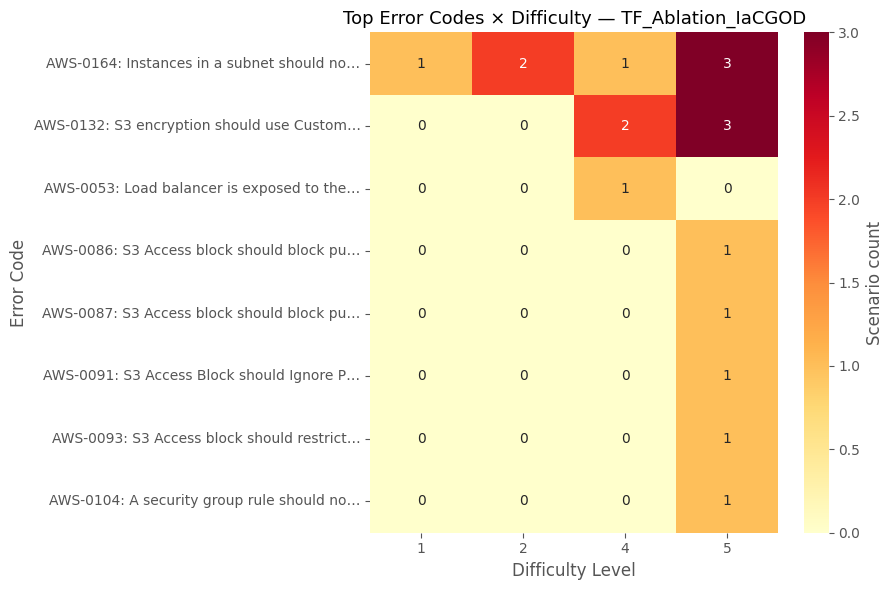

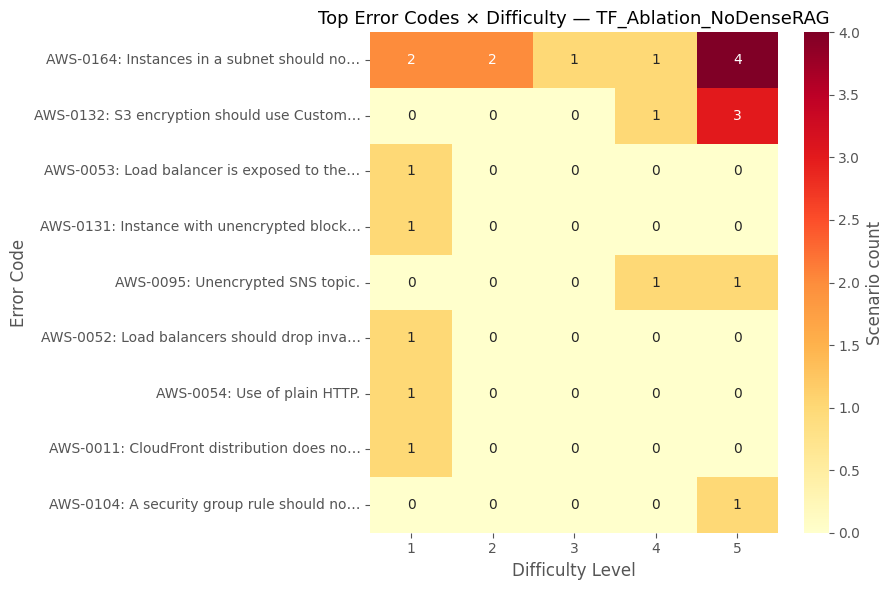

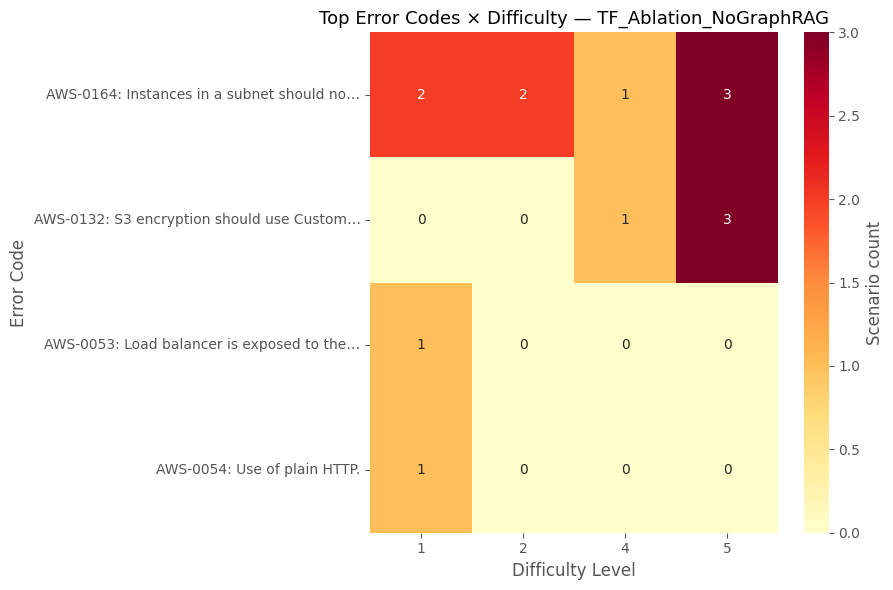

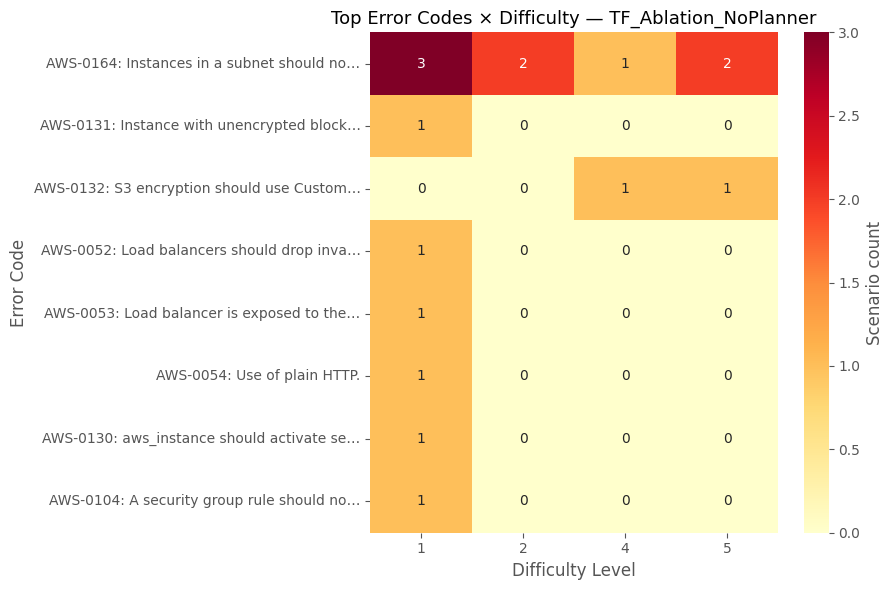

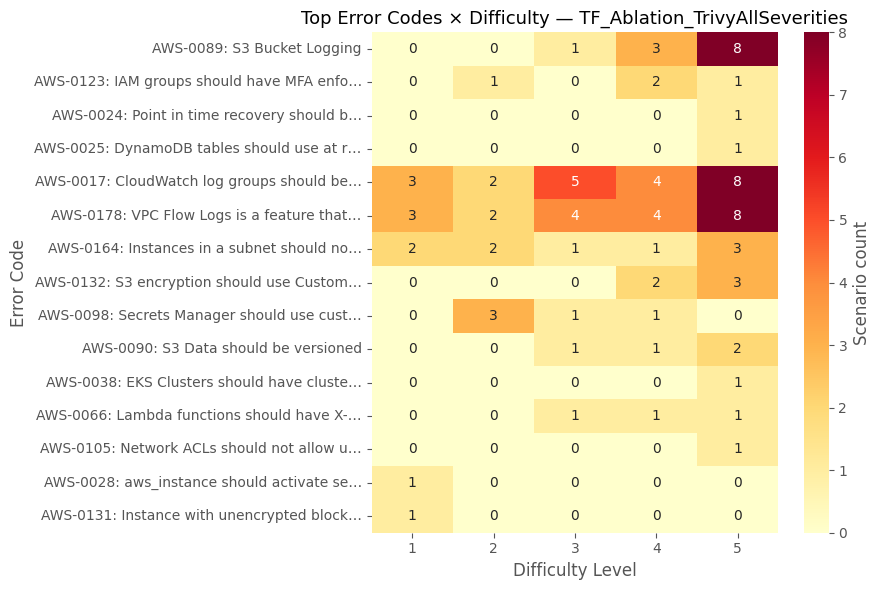

...

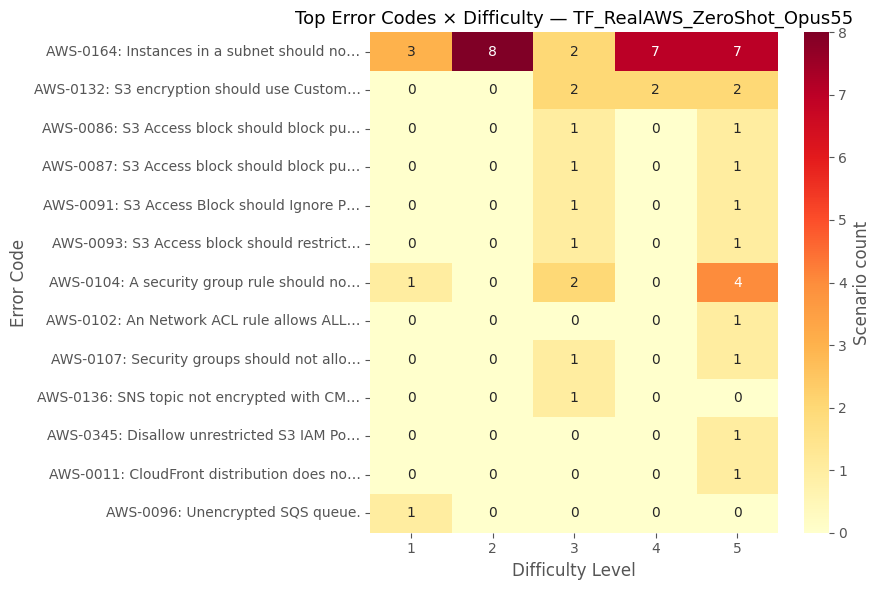

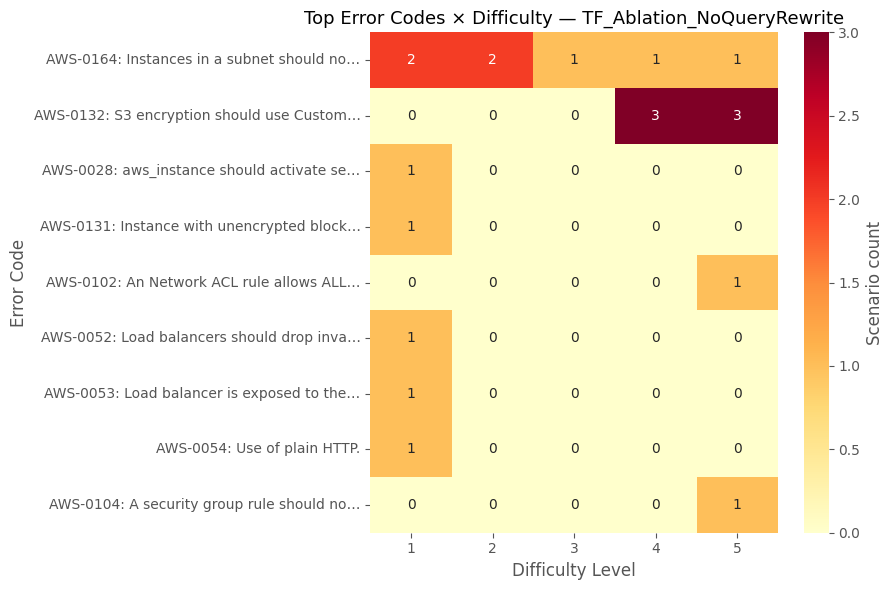

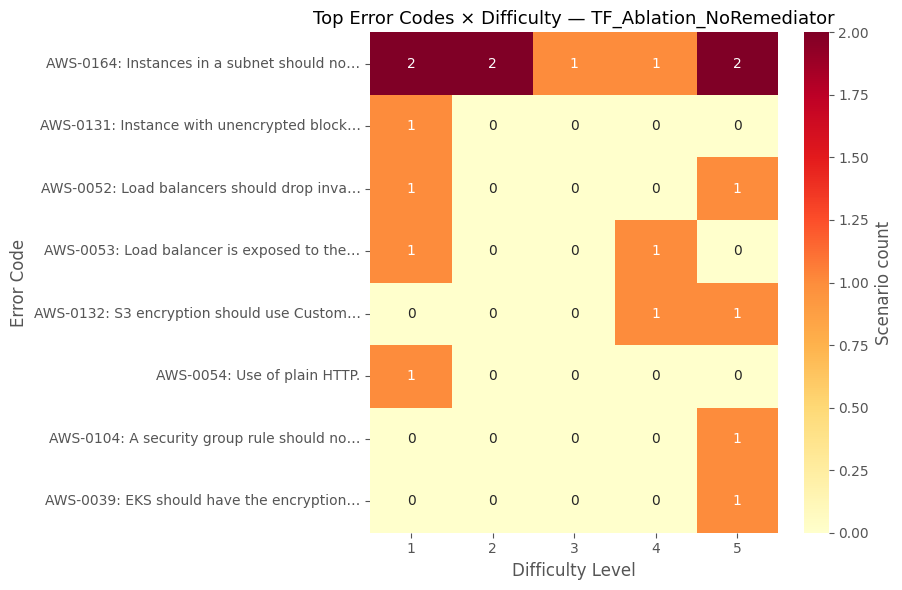

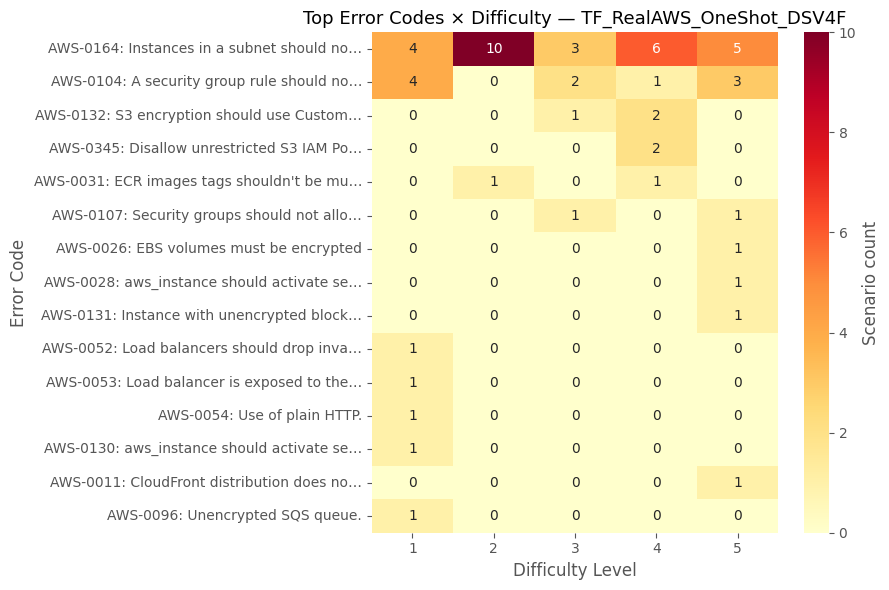

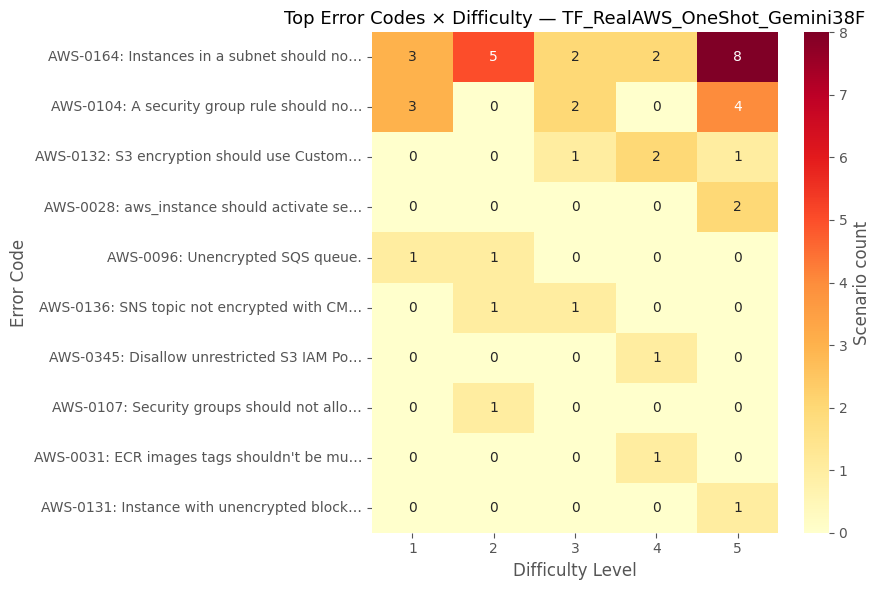

None

In [22]:
def _plot_error_codes_difficulty_heatmap(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        if "difficulty_level" not in df.columns:
            continue

        combined_counter = Counter()
        for stage in STAGE_CONFIG:
            if stage["all_col"] in df.columns:
                combined_counter.update(top_codes_from_column(df, stage["all_col"]))
        if not combined_counter:
            continue

        top_codes = [c for c, _ in combined_counter.most_common(15)]

        heat_rows = []
        for _, row in df.iterrows():
            diff = row.get("difficulty_level")
            if pd.isna(diff):
                continue
            codes_here = set()
            for stage in STAGE_CONFIG:
                codes_here.update(extract_error_codes(row.get(stage["all_col"])))
            for c in codes_here & set(top_codes):
                heat_rows.append({"Difficulty": diff, "Code": c})

        if not heat_rows:
            continue

        heat_df = pd.DataFrame(heat_rows)
        pivot = pd.crosstab(heat_df["Code"], heat_df["Difficulty"]).reindex(top_codes)
        pivot.index = [describe_code(c, width=32) for c in pivot.index]

        plt.figure(figsize=(9, 6))
        sns.heatmap(pivot, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={"label": "Scenario count"})
        plt.title(f"Top Error Codes × Difficulty — {model_name}", fontsize=13)
        plt.xlabel("Difficulty Level")
        plt.ylabel("Error Code")
        plt.tight_layout()
        plt.show()

_out_error_codes_difficulty_heatmap = widgets.interactive_output(_plot_error_codes_difficulty_heatmap, {'selected_models': model_selector})
display(_out_error_codes_difficulty_heatmap)

## Memory & Remediation Analysis (optional — requires local IaCGOD run logs)

In [23]:
import re
import json as _json
from pathlib import Path

RUNS_ROOT = Path("../runs")
_RUN_ID_RE = re.compile(r"^\d{8}_\d{6}_[0-9a-f]{6,}$")

def build_run_index(runs_root: Path) -> dict:
    idx = {}
    if not runs_root.exists():
        return idx
    for entry in runs_root.iterdir():
        if not entry.is_dir():
            continue
        if _RUN_ID_RE.match(entry.name):
            idx[entry.name] = entry
            continue
        try:
            for sub in entry.iterdir():
                if sub.is_dir() and _RUN_ID_RE.match(sub.name):
                    idx[sub.name] = sub
        except (PermissionError, OSError):
            continue
    return idx

RUN_INDEX = build_run_index(RUNS_ROOT)
print(f"📁 Indexed {len(RUN_INDEX)} run directories under {RUNS_ROOT.resolve()}")

RUN_COVERAGE = {}
for model_name, df in merged_dataframes.items():
    if "run_id" not in df.columns:
        continue
    located = df["run_id"].isin(RUN_INDEX.keys())
    RUN_COVERAGE[model_name] = located
    print(f"  {model_name}: {located.sum()}/{len(df)} scenarios have a locatable run log "
          f"({located.sum()/len(df):.0%}).")

if not RUN_INDEX:
    print("⚠️ RUNS_ROOT not found or empty -- skip the rest of this section "
          "(memory/remediation analysis needs the sibling IaCGOD run logs on disk).")

📁 Indexed 10759 run directories under /Users/iksena/Documents/research/IaCGOD/runs
  TF_Ablation_IaCGOD: 50/50 scenarios have a locatable run log (100%).
  TF_Ablation_NoDenseRAG: 49/49 scenarios have a locatable run log (100%).
  TF_Ablation_NoGraphRAG: 50/50 scenarios have a locatable run log (100%).
  TF_Ablation_NoPlanner: 50/50 scenarios have a locatable run log (100%).
  TF_Ablation_OpenCodeRetriever: 50/50 scenarios have a locatable run log (100%).
  TF_Ablation_TrivyAllSeverities: 50/50 scenarios have a locatable run log (100%).
  TF_IaCEval_DSV4F_LintOnly: 372/372 scenarios have a locatable run log (100%).
  TF_RealAWS_DSV4F: 250/250 scenarios have a locatable run log (100%).
  TF_RealAWS_GLM53F: 250/250 scenarios have a locatable run log (100%).
  TF_RealAWS_Gemini38F: 250/250 scenarios have a locatable run log (100%).
  TF_RealAWS_OpenCode_DSV4F: 250/250 scenarios have a locatable run log (100%).
  TF_RealAWS_Opus55: 250/250 scenarios have a locatable run log (100%).
  TF_Re


TF_Ablation_IaCGOD  (analyzed 50 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: 3.5 (96 remediation turns total across these runs).



TF_Ablation_NoDenseRAG  (analyzed 49 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: 6.6 (161 remediation turns total across these runs).

TF_Ablation_NoGraphRAG  (analyzed 50 run logs)
  1 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0132', 1)]
  Avg fix-objectives issued per remediation turn: 6.6 (87 remediation turns total across these runs).



TF_Ablation_NoPlanner  (analyzed 50 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: 5.9 (46 remediation turns total across these runs).

TF_Ablation_OpenCodeRetriever  (analyzed 50 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



TF_Ablation_TrivyAllSeverities  (analyzed 50 run logs)
  3 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0123', 1), ('AWS-0039', 1), ('AWS-0089', 1)]
  Avg fix-objectives issued per remediation turn: 7.0 (150 remediation turns total across these runs).



TF_IaCEval_DSV4F_LintOnly  (analyzed 300 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: 3.1 (717 remediation turns total across these runs).



TF_RealAWS_DSV4F  (analyzed 250 run logs)
  1 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0104', 1)]
  Avg fix-objectives issued per remediation turn: 4.1 (525 remediation turns total across these runs).



TF_RealAWS_GLM53F  (analyzed 250 run logs)
  1 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0164', 1)]
  Avg fix-objectives issued per remediation turn: 2.5 (714 remediation turns total across these runs).



TF_RealAWS_Gemini38F  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: 2.1 (556 remediation turns total across these runs).



TF_RealAWS_OpenCode_DSV4F  (analyzed 250 run logs)
  2 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0019', 1), ('AWS-0093', 1), ('AWS-0011', 1)]
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



TF_RealAWS_Opus55  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: 6.8 (106 remediation turns total across these runs).

TF_RealAWS_OneShot_GLM53F  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



TF_RealAWS_ZeroShot_Opus55  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).

TF_Ablation_NoQueryRewrite  (analyzed 50 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: 5.9 (64 remediation turns total across these runs).



TF_Ablation_NoRemediator  (analyzed 50 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).

TF_RealAWS_OneShot_DSV4F  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



TF_RealAWS_OneShot_Gemini38F  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).





In [24]:
FIX_OBJ_RE = re.compile(r"^\s*\d+\.\s+\*\*", re.MULTILINE)
ASSISTANT_TURN_RE = re.compile(r"^\[assistant\]\s*$", re.MULTILINE)

def load_iteration_codes(run_dir: Path) -> dict:
    out = {}
    for f in sorted(run_dir.glob("iteration_*.json")):
        try:
            d = _json.loads(f.read_text())
        except (ValueError, OSError):
            continue
        codes = set()
        for vr in d.get("validation_results", []) or []:
            for err in vr.get("errors", []) or []:
                entries = extract_error_entries(err)
                codes.update(c for c, _ in entries)
                record_messages(entries)
        out[d.get("iteration", len(out) + 1)] = codes
    return out

def count_remediator_turns_and_fix_objectives(run_dir: Path) -> tuple:
    hist = run_dir / "remediator_history.txt"
    if not hist.exists():
        return 0, 0
    text = hist.read_text(errors="ignore")
    return len(ASSISTANT_TURN_RE.findall(text)), len(FIX_OBJ_RE.findall(text))

MEMORY_SAMPLE_LIMIT = 300

memory_summaries = {}
for model_name, df in merged_dataframes.items():
    if model_name not in RUN_COVERAGE:
        continue
    located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
    if located_df.empty:
        continue

    recur_counter, persist_counter = Counter(), Counter()
    fix_obj_counts, turn_counts = [], []
    n_recurring_runs, n_persistent_runs = 0, 0

    for _, row in located_df.iterrows():
        run_dir = RUN_INDEX[row["run_id"]]
        itcodes = load_iteration_codes(run_dir)
        iters_sorted = sorted(itcodes.keys())
        if len(iters_sorted) < 2:
            occurrences = {}
        else:
            occurrences = {}
            for i in iters_sorted:
                for c in itcodes[i]:
                    occurrences.setdefault(c, []).append(i)

        run_has_recur, run_has_persist = False, False
        for c, occ in occurrences.items():
            if len(occ) > 1 and (occ[-1] - occ[0]) > (len(occ) - 1):
                recur_counter[c] += 1
                run_has_recur = True
            elif len(occ) == len(iters_sorted) and len(iters_sorted) > 1:
                persist_counter[c] += 1
                run_has_persist = True
        n_recurring_runs += run_has_recur
        n_persistent_runs += run_has_persist

        n_turns, n_fix = count_remediator_turns_and_fix_objectives(run_dir)
        turn_counts.append(n_turns)
        fix_obj_counts.append(n_fix)

    memory_summaries[model_name] = {
        "n_runs": len(located_df),
        "recur_counter": recur_counter,
        "persist_counter": persist_counter,
        "n_recurring_runs": n_recurring_runs,
        "n_persistent_runs": n_persistent_runs,
        "turn_counts": turn_counts,
        "fix_obj_counts": fix_obj_counts,
    }

    print(f"\n{'='*90}\n{model_name}  (analyzed {len(located_df)} run logs)")
    print(f"  {n_recurring_runs} run(s) had an error code disappear then reappear in a later iteration.")
    print(f"  {n_persistent_runs} run(s) had an error code present in EVERY iteration (never cleared).")
    if recur_counter:
        print(f"  Most-recurring codes: {recur_counter.most_common(8)}")
    if persist_counter:
        print(f"  Most-persistent codes: {persist_counter.most_common(8)}")

    mean_items_per_turn = (sum(fix_obj_counts) / sum(turn_counts)) if sum(turn_counts) else float("nan")
    print(f"  Avg fix-objectives issued per remediation turn: {mean_items_per_turn:.1f} "
          f"({sum(turn_counts)} remediation turns total across these runs).")

if memory_summaries:
    fig, axes = plt.subplots(1, len(memory_summaries), figsize=(7 * len(memory_summaries), 5), squeeze=False)
    for ax, (model_name, summ) in zip(axes[0], memory_summaries.items()):
        combo = Counter(summ["recur_counter"]) + Counter(summ["persist_counter"])
        top = pd.DataFrame(combo.most_common(10), columns=["Code", "Count"])
        if top.empty:
            ax.text(0.5, 0.5, "No recurring/persistent codes", ha="center", va="center")
            ax.set_axis_off()
            continue
        top["Label"] = top["Code"].apply(describe_code)
        sns.barplot(data=top, y="Label", x="Count", color="crimson", ax=ax)
        ax.set_title(f"{model_name}\n(recurring + persistent error codes)", fontsize=11)
        ax.set_xlabel("Run count")
        ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

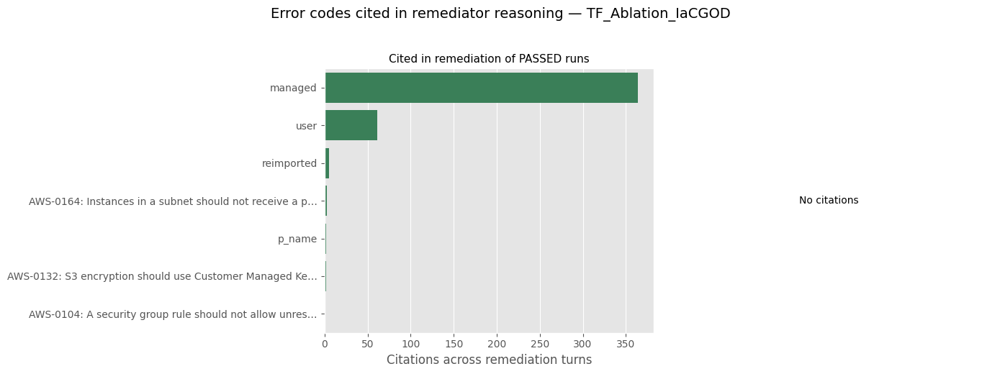


TF_Ablation_IaCGOD — root-cause keyword themes in remediator reasoning:
  Passed runs: [('encryption', 15), ('security group', 10), ('public access', 6), ('deprecated', 5), ('hardcoded', 4), ('self-contained', 3), ('customer managed key', 3), ('type mismatch', 2)]
  Failed runs: []


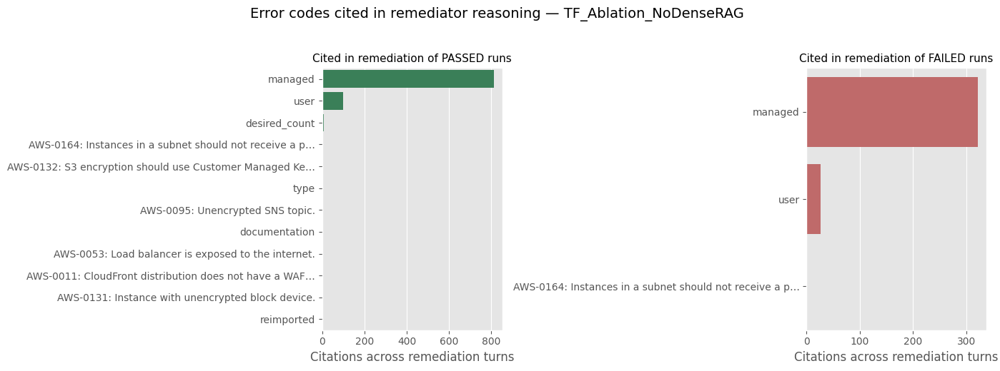


TF_Ablation_NoDenseRAG — root-cause keyword themes in remediator reasoning:
  Passed runs: [('deprecated', 18), ('encryption', 16), ('hardcoded', 13), ('security group', 11), ('public access', 11), ('customer managed key', 6), ('trust policy', 3), ('self-contained', 2)]
  Failed runs: [('deprecated', 2), ('encryption', 2), ('customer managed key', 2), ('security group', 1)]


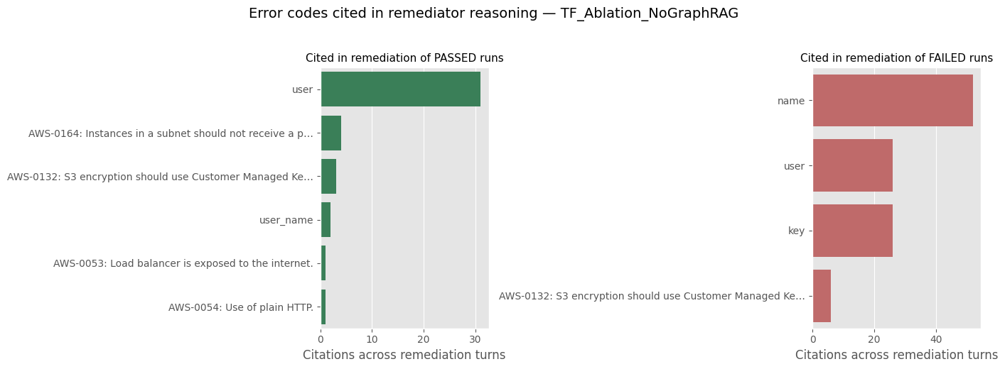


TF_Ablation_NoGraphRAG — root-cause keyword themes in remediator reasoning:
  Passed runs: [('hardcoded', 10), ('encryption', 9), ('self-contained', 5), ('security group', 4), ('customer managed key', 3), ('deprecated', 2), ('trust policy', 2), ('iam permission', 1)]
  Failed runs: [('hardcoded', 2), ('encryption', 2), ('customer managed key', 2), ('deprecated', 1), ('security group', 1)]


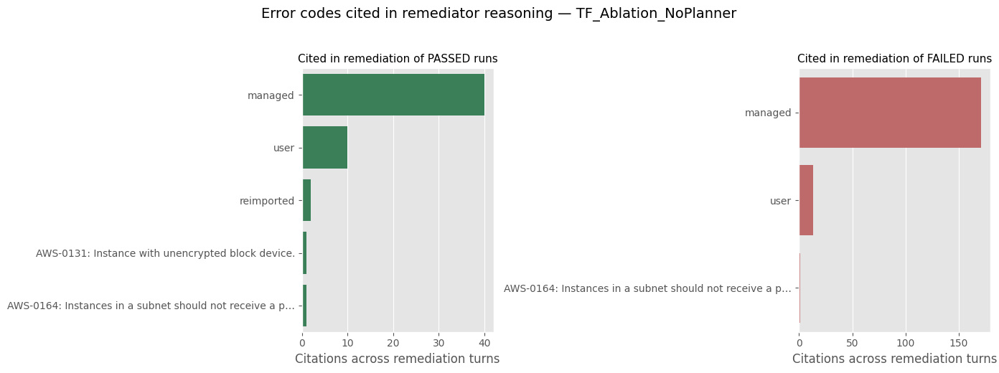


TF_Ablation_NoPlanner — root-cause keyword themes in remediator reasoning:
  Passed runs: [('hardcoded', 7), ('deprecated', 6), ('encryption', 5), ('security group', 3), ('public access', 2), ('self-contained', 2), ('customer managed key', 1)]
  Failed runs: [('deprecated', 1), ('hardcoded', 1), ('encryption', 1), ('customer managed key', 1), ('security group', 1)]


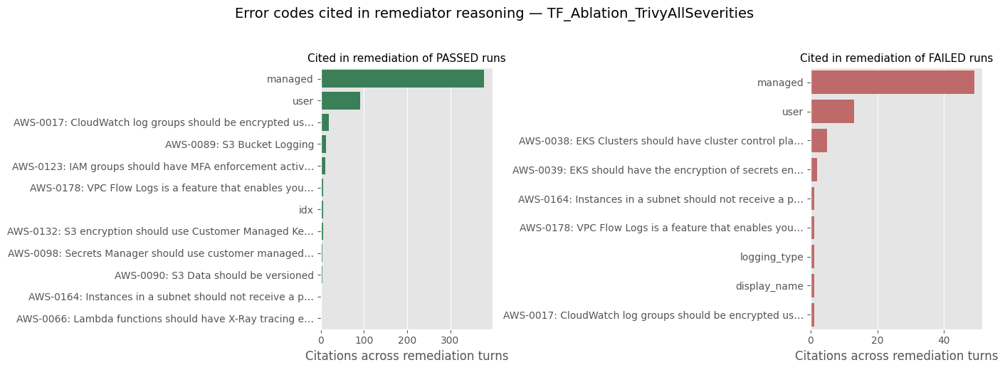


TF_Ablation_TrivyAllSeverities — root-cause keyword themes in remediator reasoning:
  Passed runs: [('encryption', 39), ('hardcoded', 33), ('deprecated', 32), ('security group', 14), ('customer managed key', 11), ('self-contained', 10), ('trust policy', 8), ('public access', 7)]
  Failed runs: [('deprecated', 1), ('hardcoded', 1), ('trust policy', 1), ('encryption', 1), ('customer managed key', 1), ('security group', 1)]


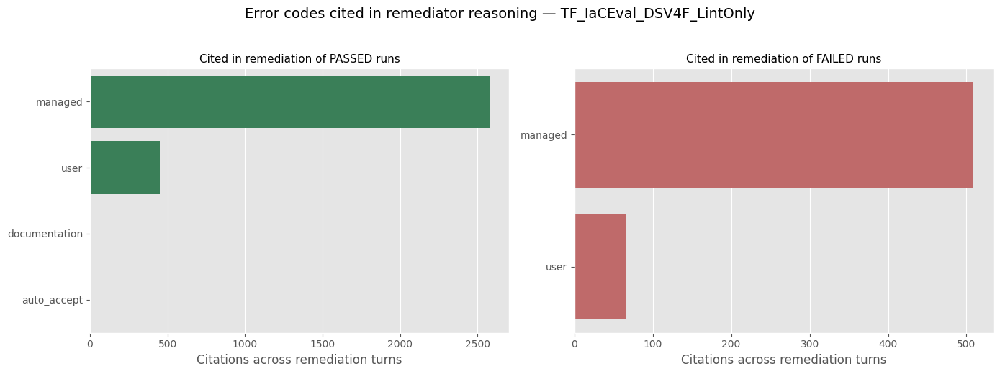


TF_IaCEval_DSV4F_LintOnly — root-cause keyword themes in remediator reasoning:
  Passed runs: [('encryption', 102), ('deprecated', 62), ('security group', 51), ('public access', 45), ('hardcoded', 13), ('self-contained', 5), ('trust policy', 4), ('missing resource', 3)]
  Failed runs: [('encryption', 5), ('security group', 4), ('deprecated', 2), ('missing resource', 1), ('iam permission', 1), ('trust policy', 1), ('public access', 1), ('hardcoded', 1)]


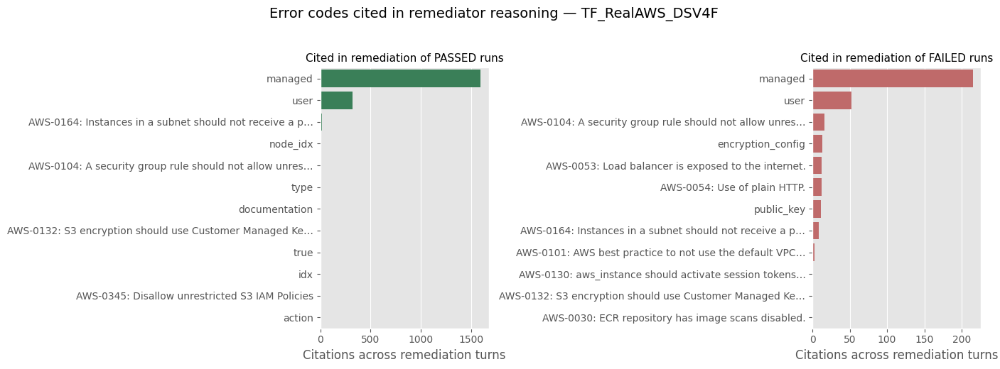


TF_RealAWS_DSV4F — root-cause keyword themes in remediator reasoning:
  Passed runs: [('encryption', 69), ('deprecated', 50), ('hardcoded', 44), ('security group', 42), ('public access', 29), ('self-contained', 15), ('customer managed key', 14), ('trust policy', 9)]
  Failed runs: [('deprecated', 4), ('encryption', 4), ('security group', 3), ('public access', 2), ('hardcoded', 2), ('customer managed key', 2), ('missing resource', 1), ('trust policy', 1)]


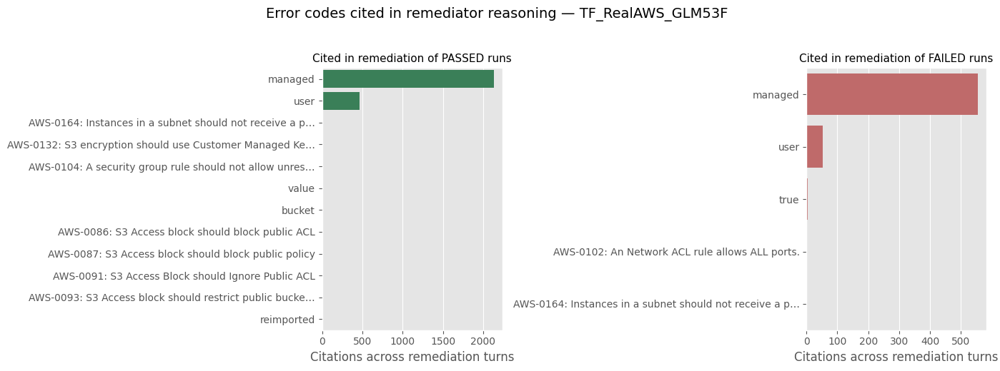


TF_RealAWS_GLM53F — root-cause keyword themes in remediator reasoning:
  Passed runs: [('hardcoded', 82), ('encryption', 68), ('deprecated', 54), ('security group', 45), ('public access', 37), ('trust policy', 19), ('self-contained', 17), ('customer managed key', 13)]
  Failed runs: [('deprecated', 4), ('hardcoded', 4), ('encryption', 4), ('public access', 2), ('security group', 2), ('missing resource', 1)]


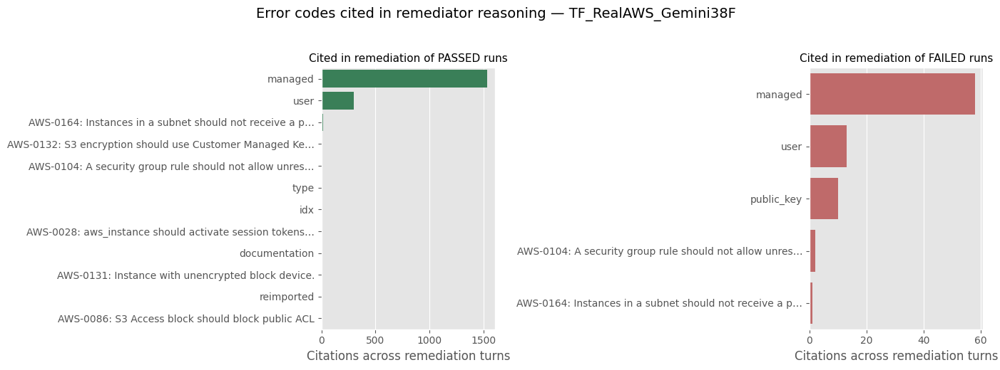


TF_RealAWS_Gemini38F — root-cause keyword themes in remediator reasoning:
  Passed runs: [('deprecated', 63), ('encryption', 62), ('security group', 45), ('public access', 26), ('customer managed key', 18), ('self-contained', 5), ('trust policy', 4), ('hardcoded', 4)]
  Failed runs: [('deprecated', 1), ('encryption', 1), ('security group', 1)]


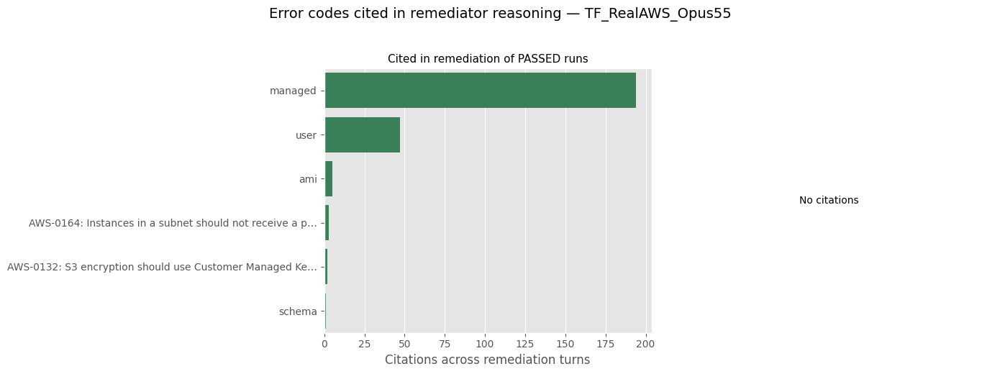


TF_RealAWS_Opus55 — root-cause keyword themes in remediator reasoning:
  Passed runs: [('security group', 26), ('encryption', 26), ('hardcoded', 22), ('deprecated', 10), ('public access', 10), ('customer managed key', 8), ('self-contained', 2), ('trust policy', 1)]
  Failed runs: []


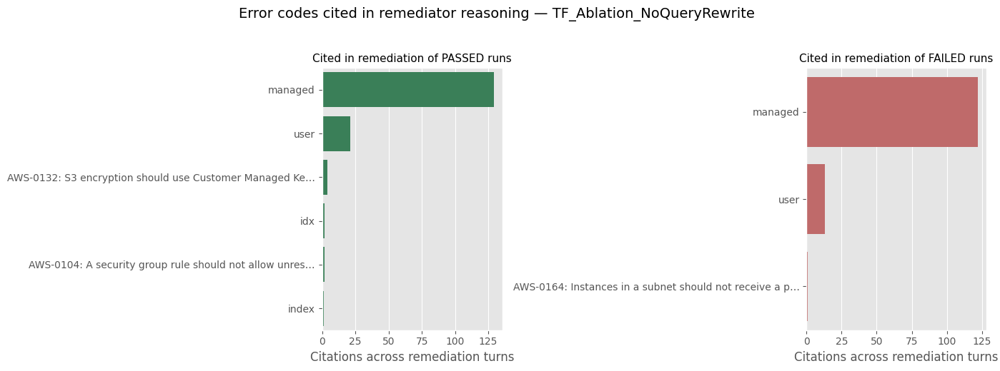


TF_Ablation_NoQueryRewrite — root-cause keyword themes in remediator reasoning:
  Passed runs: [('hardcoded', 16), ('encryption', 14), ('security group', 8), ('deprecated', 7), ('public access', 6), ('customer managed key', 6), ('self-contained', 3), ('type mismatch', 2)]
  Failed runs: [('deprecated', 1), ('encryption', 1), ('security group', 1)]


None

In [25]:
ROOT_CAUSE_KEYWORDS = [
    "circular dependency", "deprecated", "hardcoded", "self-contained", "self-containment",
    "unused parameter", "missing resource", "iam permission", "trust policy",
    "encryption", "customer managed key", "public access", "security group",
    "dependson", "intrinsic function", "type mismatch", "not authorized",
]

def cited_codes_and_keywords(run_dir: Path) -> tuple:
    hist = run_dir / "remediator_history.txt"
    if not hist.exists():
        return Counter(), Counter()
    text = hist.read_text(errors="ignore")
    assistant_blocks = re.split(r"^\[assistant\]\s*$", text, flags=re.MULTILINE)[1:]
    assistant_text = "\n".join(assistant_blocks)
    codes = Counter(c for c in CODE_RE.findall(assistant_text) if GOOD_CODE_RE.match(c))
    low = assistant_text.lower()
    kws = Counter(kw for kw in ROOT_CAUSE_KEYWORDS if kw in low)
    return codes, kws

def _plot_remediator_fix_citations(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        if model_name not in RUN_COVERAGE or "final_validation_passed" not in df.columns:
            continue
        located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
        if located_df.empty:
            continue

        cited_passed, cited_failed = Counter(), Counter()
        kw_passed, kw_failed = Counter(), Counter()
        for _, row in located_df.iterrows():
            run_dir = RUN_INDEX[row["run_id"]]
            codes, kws = cited_codes_and_keywords(run_dir)
            bucket_c = cited_passed if row["final_validation_passed"] else cited_failed
            bucket_k = kw_passed if row["final_validation_passed"] else kw_failed
            bucket_c.update(codes)
            bucket_k.update(kws)

        if not (cited_passed or cited_failed):
            continue

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        for ax, counter, title, color in [
            (axes[0], cited_passed, "Cited in remediation of PASSED runs", "seagreen"),
            (axes[1], cited_failed, "Cited in remediation of FAILED runs", "indianred"),
        ]:
            top = pd.DataFrame(counter.most_common(12), columns=["Code", "Count"])
            if top.empty:
                ax.text(0.5, 0.5, "No citations", ha="center", va="center")
                ax.set_axis_off()
                continue
            top["Label"] = top["Code"].apply(describe_code)
            sns.barplot(data=top, y="Label", x="Count", color=color, ax=ax)
            ax.set_title(title, fontsize=11)
            ax.set_xlabel("Citations across remediation turns")
            ax.set_ylabel("")
        fig.suptitle(f"Error codes cited in remediator reasoning — {model_name}", fontsize=14, y=1.03)
        plt.tight_layout()
        plt.show()

        print(f"\n{model_name} — root-cause keyword themes in remediator reasoning:")
        print(f"  Passed runs: {kw_passed.most_common(8)}")
        print(f"  Failed runs: {kw_failed.most_common(8)}")

_out_remediator_fix_citations = widgets.interactive_output(_plot_remediator_fix_citations, {'selected_models': model_selector})
display(_out_remediator_fix_citations)

📊 Security-code lifecycle: 521 (scenario, code) instances across 335 scenarios with security findings.


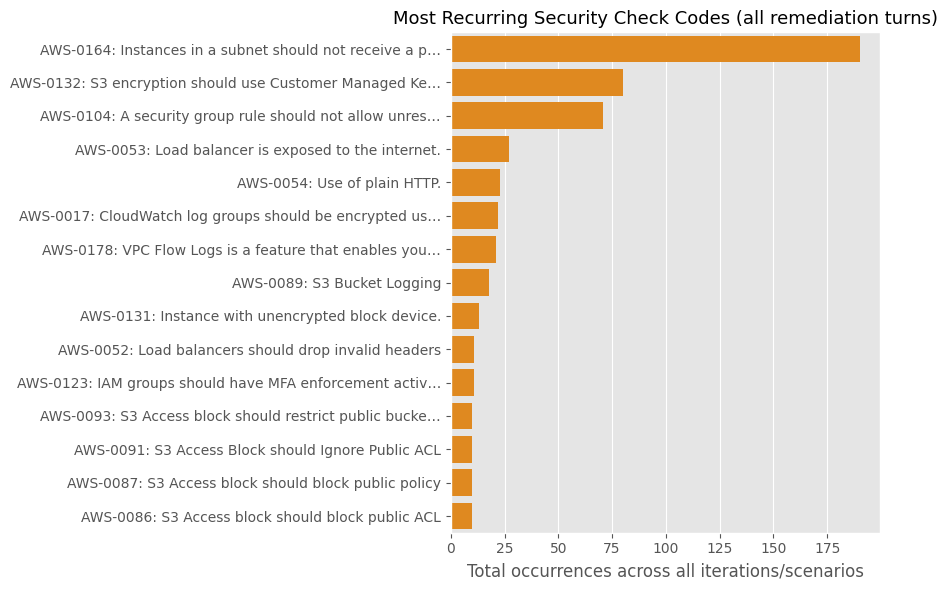

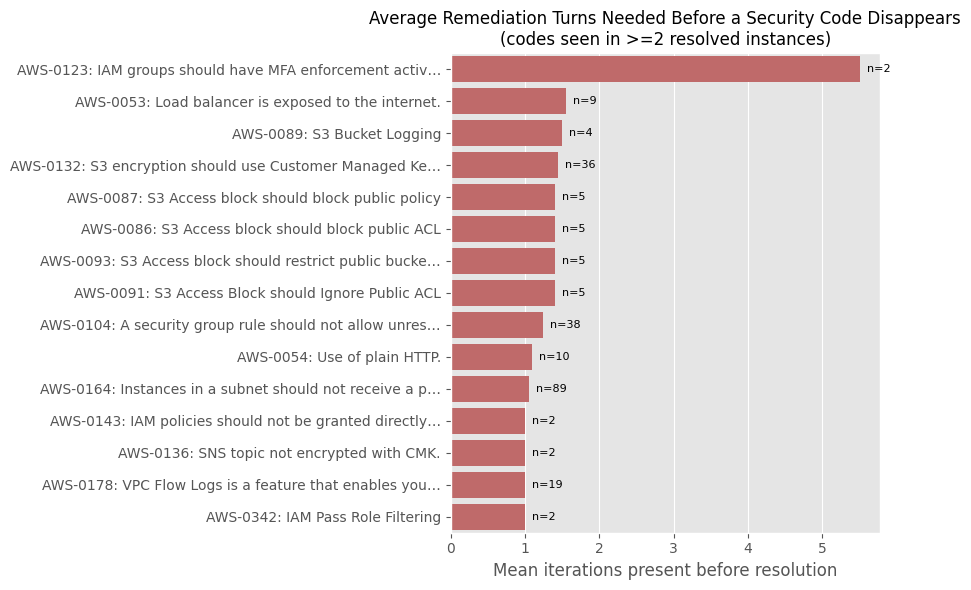


  Overall: 304/521 security-code instances were resolved by the run's own final iteration (217 were still open at the end).
  Median iterations-to-resolve (resolved instances only): 1.0


In [26]:
SECURITY_STAGES = ("trivy", "checkov")

def load_final_report(run_dir: Path) -> dict | None:
    path = run_dir / "final_report.json"
    if not path.exists():
        return None
    try:
        return _json.loads(path.read_text())
    except (ValueError, OSError):
        return None

def security_codes_by_iteration(remediation_history: list) -> dict:
    out = {}
    for entry in remediation_history:
        codes = set()
        for stage_result in entry.get("errors", []) or []:
            if stage_result.get("stage") not in SECURITY_STAGES:
                continue
            for err in stage_result.get("errors", []) or []:
                entries = extract_error_entries(err)
                codes.update(c for c, _ in entries)
                record_messages(entries)
        out[entry["iteration"]] = codes
    return out

def security_code_lifecycle(codes_by_iter: dict) -> list:
    if not codes_by_iter:
        return []
    iters_sorted = sorted(codes_by_iter)
    last_iter = iters_sorted[-1]
    all_codes = set().union(*codes_by_iter.values()) if codes_by_iter else set()
    rows = []
    for code in all_codes:
        present = [i for i in iters_sorted if code in codes_by_iter[i]]
        first_seen, last_seen = min(present), max(present)
        resolved = code not in codes_by_iter[last_iter]
        rows.append({
            "code": code,
            "first_seen_iteration": first_seen,
            "last_seen_iteration": last_seen,
            "resolved_by_end": resolved,
            "iterations_present": (last_seen - first_seen + 1) if resolved else None,
        })
    return rows

security_lifecycle_rows = []
security_occurrence_counter = Counter()

for model_name, df in merged_dataframes.items():
    if model_name not in RUN_COVERAGE:
        continue
    located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
    for _, row in located_df.iterrows():
        run_dir = RUN_INDEX[row["run_id"]]
        report = load_final_report(run_dir)
        if not report:
            continue
        codes_by_iter = security_codes_by_iteration(report.get("remediation_history", []))
        if not codes_by_iter:
            continue
        for it, codes in codes_by_iter.items():
            security_occurrence_counter.update(codes)
        for r in security_code_lifecycle(codes_by_iter):
            r["model"] = model_name
            r["row_number"] = row["row_number"]
            r["run_id"] = row["run_id"]
            security_lifecycle_rows.append(r)

if security_lifecycle_rows:
    sec_life_df = pd.DataFrame(security_lifecycle_rows)
    print(f"📊 Security-code lifecycle: {len(sec_life_df)} (scenario, code) instances "
          f"across {sec_life_df.groupby(['model','row_number']).ngroups} scenarios with security findings.")

    top_occurrence = pd.DataFrame(security_occurrence_counter.most_common(15), columns=["Code", "Occurrences"])
    top_occurrence["Label"] = top_occurrence["Code"].apply(describe_code)

    plt.figure(figsize=(9, 6))
    sns.barplot(data=top_occurrence, y="Label", x="Occurrences", color="darkorange")
    plt.title("Most Recurring Security Check Codes (all remediation turns)", fontsize=13)
    plt.xlabel("Total occurrences across all iterations/scenarios")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    resolved_df = sec_life_df[sec_life_df["resolved_by_end"]]
    if not resolved_df.empty:
        avg_iters = resolved_df.groupby("code")["iterations_present"].agg(["mean", "count"]).reset_index()
        avg_iters = avg_iters[avg_iters["count"] >= 2].sort_values("mean", ascending=False).head(15)
        avg_iters["Label"] = avg_iters["code"].apply(describe_code)

        if not avg_iters.empty:
            plt.figure(figsize=(9, 6))
            ax = sns.barplot(data=avg_iters, y="Label", x="mean", color="indianred")
            for i, (mean, count) in enumerate(zip(avg_iters["mean"], avg_iters["count"])):
                ax.annotate(f"n={count}", (mean, i), va="center", xytext=(5, 0), textcoords="offset points", fontsize=8)
            plt.title("Average Remediation Turns Needed Before a Security Code Disappears\n(codes seen in >=2 resolved instances)", fontsize=12)
            plt.xlabel("Mean iterations present before resolution")
            plt.ylabel("")
            plt.tight_layout()
            plt.show()

        print(f"\n  Overall: {len(resolved_df)}/{len(sec_life_df)} security-code instances were resolved by "
              f"the run's own final iteration ({len(sec_life_df) - len(resolved_df)} were still open at the end).")
        print(f"  Median iterations-to-resolve (resolved instances only): {resolved_df['iterations_present'].median():.1f}")
    else:
        print("No resolved security-code instances found.")
else:
    print("⚠️ No security-code lifecycle data found -- check RUN_INDEX/RUN_COVERAGE above "
          "(needs the sibling IaCGOD run logs for these row_numbers on disk).")

In [27]:
DEBUG_MODEL = None
DEBUG_ROW_NUMBER = None

if security_lifecycle_rows:
    debug_model = DEBUG_MODEL or security_lifecycle_rows[0]["model"]
    candidates = [r for r in security_lifecycle_rows if r["model"] == debug_model]
    debug_row_number = DEBUG_ROW_NUMBER if DEBUG_ROW_NUMBER is not None else candidates[0]["row_number"]

    match = merged_dataframes[debug_model]
    match = match[match["row_number"] == debug_row_number]
    if match.empty or match.iloc[0]["run_id"] not in RUN_INDEX:
        print(f"⚠️ No locatable run for model={debug_model!r} row_number={debug_row_number!r}.")
    else:
        run_id = match.iloc[0]["run_id"]
        run_dir = RUN_INDEX[run_id]
        print(f"Model: {debug_model} | row_number: {debug_row_number} | run_id: {run_id}")
        print(f"Run dir: {run_dir.resolve()}\n")

        report = load_final_report(run_dir)
        codes_by_iter = security_codes_by_iteration(report.get("remediation_history", []))
        print("Security codes present, per iteration:")
        for it in sorted(codes_by_iter):
            codes = codes_by_iter[it]
            print(f"  iter {it}: {sorted(codes) if codes else '(none)'}")

        print("\nPer-code lifecycle:")
        display(pd.DataFrame(security_code_lifecycle(codes_by_iter)))
else:
    print("No security lifecycle data to debug -- run the previous cell first.")

Model: TF_Ablation_IaCGOD | row_number: 6 | run_id: 20260929_002056_2fdbe218
Run dir: /Users/iksena/Documents/research/IaCGOD/runs/Ablation_IaCGOD_TF_runs/20260929_002056_2fdbe218

Security codes present, per iteration:
  iter 1: (none)
  iter 2: ['AWS-0164']

Per-code lifecycle:


,code,first_seen_iteration,last_seen_iteration,resolved_by_end,iterations_present
0,AWS-0164,2,2,False,None


📊 Knowledge-base context measured across 3300 remediation turns (1089 scenarios).


word_count         token_count          \
                                     mean  median        mean  median   
model                                                                   
TF_Ablation_IaCGOD                 1044.1   780.0      2339.8  1678.5   
TF_Ablation_NoDenseRAG             1473.3  1215.0      3304.8  2766.0   
TF_Ablation_NoGraphRAG              114.9    98.0       296.7   205.0   
TF_Ablation_NoPlanner              1169.2   780.5      2638.9  1761.5   
TF_Ablation_NoQueryRewrite         1160.3   669.5      2557.7  1481.5   
TF_Ablation_NoRemediator           1034.5   755.0      2347.4  1597.0   
TF_Ablation_TrivyAllSeverities      805.4   390.0      1819.9   854.0   
TF_IaCEval_DSV4F_LintOnly           997.0   823.0      2181.0  1845.0   
TF_RealAWS_DSV4F                    812.8   469.0      1817.9  1062.0   
TF_RealAWS_GLM53F                   849.5   482.5      1885.4  1098.0   
TF_RealAWS_Gemini38F                847.1   672.5      1888.8  1517.5   
TF_RealAWS_Opus55                   612.8   386.5      1377.9   942.0   

                               char_count          n_retrieval_queries         
                                     mean   median                mean median  
model                                                                          
TF_Ablation_IaCGOD                 9875.9   7075.0                 2.8    2.0  
TF_Ablation_NoDenseRAG            13944.4  11560.0                 4.6    5.0  
TF_Ablation_NoGraphRAG             1202.0    828.0                 5.1    6.0  
TF_Ablation_NoPlanner             11179.0   7619.5                 4.8    5.0  
TF_Ablation_NoQueryRewrite        10861.4   6220.5                 1.5    1.0  
TF_Ablation_NoRemediator           9992.4   6645.0                 4.5    5.0  
TF_Ablation_TrivyAllSeverities     7614.1   3621.5                 3.1    2.0  
TF_IaCEval_DSV4F_LintOnly          9365.1   7918.0                 1.5    1.0  
TF_RealAWS_DSV4F                   7736.4   4499.0                 3.0    2.0  
TF_RealAWS_GLM53F                  8001.8   4632.0                 2.4    2.0  
TF_RealAWS_Gemini38F               7963.7   6306.0                 1.4    1.0  
TF_RealAWS_Opus55                  5852.8   4120.0                 3.3    1.0

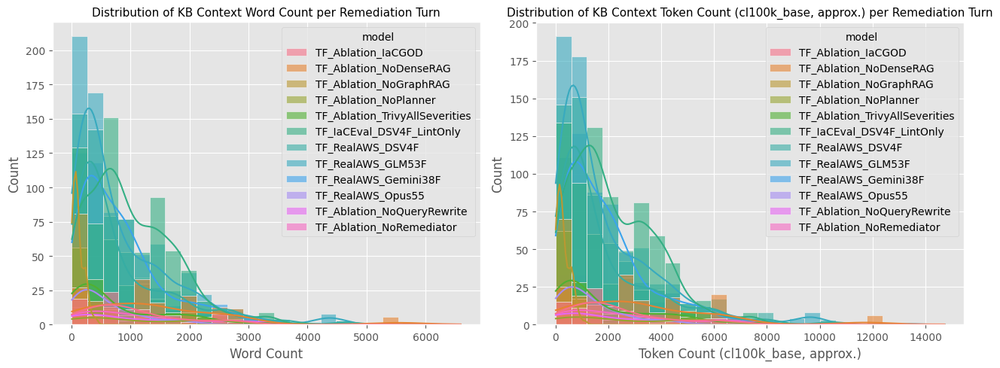

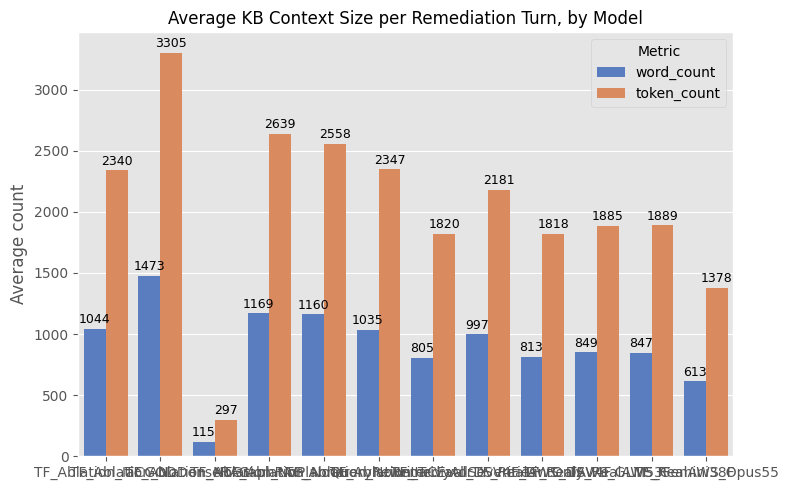

None

In [28]:
try:
    import tiktoken
    _KB_ENC = tiktoken.get_encoding("cl100k_base")
    def _count_tokens(text: str) -> int:
        return len(_KB_ENC.encode(text)) if text else 0
except ImportError:
    print("⚠️ tiktoken not installed -- token counts will be NaN (word counts still work). pip install tiktoken.")
    def _count_tokens(text: str) -> float:
        return float("nan")

kb_context_rows = []
for model_name, df in merged_dataframes.items():
    if model_name not in RUN_COVERAGE:
        continue
    located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
    for _, row in located_df.iterrows():
        run_dir = RUN_INDEX[row["run_id"]]
        report = load_final_report(run_dir)
        if not report:
            continue
        for entry in report.get("remediation_history", []):
            text = entry.get("retriever_context", "") or ""
            kb_context_rows.append({
                "model": model_name,
                "row_number": row["row_number"],
                "run_id": row["run_id"],
                "iteration": entry["iteration"],
                "char_count": len(text),
                "word_count": len(text.split()),
                "token_count": _count_tokens(text),
                "n_retrieval_queries": len(entry.get("retrieval_queries", []) or []),
            })

kb_df = pd.DataFrame(kb_context_rows) if kb_context_rows else pd.DataFrame()

def _plot_kb_context_size(selected_models):
    if kb_context_rows:
        kb_df_sel = kb_df[kb_df["model"].isin(selected_models)]
        if kb_df_sel.empty:
            print("⚠️ No knowledge-base context data for the selected model(s).")
            return

        print(f"📊 Knowledge-base context measured across {len(kb_df_sel)} remediation turns "
              f"({kb_df_sel.groupby(['model','row_number']).ngroups} scenarios).")

        summary = kb_df_sel.groupby("model")[["word_count", "token_count", "char_count", "n_retrieval_queries"]].agg(["mean", "median"])
        display(summary.round(1))

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        for ax, col, label in zip(axes, ["word_count", "token_count"], ["Word Count", "Token Count (cl100k_base, approx.)"]):
            sns.histplot(data=kb_df_sel, x=col, hue="model", bins=25, ax=ax, kde=True, alpha=0.6)
            ax.set_title(f"Distribution of KB Context {label} per Remediation Turn", fontsize=11)
            ax.set_xlabel(label)
        plt.tight_layout()
        plt.show()

        avg_by_model = kb_df_sel.groupby("model")[["word_count", "token_count"]].mean().reset_index()
        avg_plot = avg_by_model.melt(id_vars="model", var_name="Metric", value_name="Average")
        plt.figure(figsize=(8, 5))
        ax = sns.barplot(data=avg_plot, x="model", y="Average", hue="Metric")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", fontsize=9, padding=2)
        plt.title("Average KB Context Size per Remediation Turn, by Model", fontsize=12)
        plt.ylabel("Average count")
        plt.xlabel("")
        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ No knowledge-base context data found -- check RUN_INDEX/RUN_COVERAGE above "
              "(needs the sibling IaCGOD run logs for these row_numbers on disk).")

_out_kb_context_size = widgets.interactive_output(_plot_kb_context_size, {'selected_models': model_selector})
display(_out_kb_context_size)

In [29]:
DEBUG_KB_MODEL = None
DEBUG_KB_ROW_NUMBER = None
DEBUG_KB_ITERATION = None

if kb_context_rows:
    debug_model = DEBUG_KB_MODEL or kb_context_rows[0]["model"]
    candidates = [r for r in kb_context_rows if r["model"] == debug_model]
    if DEBUG_KB_ROW_NUMBER is not None:
        candidates = [r for r in candidates if r["row_number"] == DEBUG_KB_ROW_NUMBER]
    if DEBUG_KB_ITERATION is not None:
        candidates = [r for r in candidates if r["iteration"] == DEBUG_KB_ITERATION]
    nonempty = [r for r in candidates if r["char_count"] > 0]
    candidates = nonempty or candidates

    if not candidates:
        print("⚠️ No matching (model, row_number, iteration) found.")
    else:
        picked = candidates[0]
        run_dir = RUN_INDEX[picked["run_id"]]
        report = load_final_report(run_dir)
        entry = next(e for e in report["remediation_history"] if e["iteration"] == picked["iteration"])
        text = entry.get("retriever_context", "") or ""

        print(f"Model: {picked['model']} | row_number: {picked['row_number']} | "
              f"run_id: {picked['run_id']} | iteration: {picked['iteration']}")
        print(f"Run dir: {run_dir.resolve()}")
        print(f"Retrieval queries: {entry.get('retrieval_queries')}")
        print(f"\nchar_count={len(text)}  word_count={len(text.split())}  token_count={_count_tokens(text)}\n")
        print("─" * 80)
        print(text[:4000] + ("\n... [truncated]" if len(text) > 4000 else ""))
        print("─" * 80)
else:
    print("No KB context data to debug -- run the previous cell first.")

Model: TF_Ablation_IaCGOD | row_number: 3 | run_id: 20260920_044840_6163f0d1 | iteration: 1
Run dir: /Users/iksena/Documents/research/IaCGOD/runs/Ablation_runs/20260920_044840_6163f0d1
Retrieval queries: ['terraform init failed: Error: Failed to install provider\n\nError while installing hashicorp/aws v5.100.0: open\n/tmp/iac-god-tf-plugin-cache/registry.terraform.io/hashicorp/aws/5.100.0/linux_amd64/terraform-provider-aws_v5.100.0_x5:\ntext file busy']

char_count=4558  word_count=478  token_count=1139

────────────────────────────────────────────────────────────────────────────────
## Official Terraform Provider Schema Context


### aws_security_group
Required: None(None)
Optional: vpc_id(string) — (Optional) Id of the VPC that the desired security group belongs to., tags_all(map(string)), tags(map(string)) — (Optional) Map of tags, each pair of which must exactly match, revoke_rules_on_delete(bool), region(string) — Region where this resource will be [managed](https://docs.aws.amazo